# 2. Data Preparation

Upload zip & read all CSV files 🗃️

In [1]:
# ============================================================
# LOAD ALL 20YY GNSS SCINTILLATION DATA
# Input : 20YY.zip
# Output: df (combined satellite-level observations)
# ============================================================

import pandas as pd
import numpy as np

from io import BytesIO
from zipfile import ZipFile
from google.colab import files


# ============================================================
# 1. UPLOAD ZIP FILE
# ============================================================

uploaded = files.upload()

if not uploaded:
    raise ValueError("No ZIP file uploaded.")

zip_name = next(iter(uploaded))

if not zip_name.lower().endswith(".zip"):
    raise ValueError("Please upload a ZIP file.")


# ============================================================
# 2. READ ALL CSV FILES
# ============================================================

dataframes = []
failed_files = []

with ZipFile(BytesIO(uploaded[zip_name])) as archive:

    csv_files = sorted(
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
        and "__MACOSX" not in name
        and not name.rsplit("/", 1)[-1].startswith("._")
    )

    if not csv_files:
        raise ValueError("No CSV files found in the ZIP archive.")

    print("ZIP file:", zip_name)
    print("CSV files found:", len(csv_files))

    for file_name in csv_files:

        try:
            daily_df = pd.read_csv(
                BytesIO(archive.read(file_name)),
                skiprows=2,              # Skip introductory lines
                header=0,                # Third line contains headers
                usecols=range(19),       # Ignore extra trailing field
                skipinitialspace=True,
                encoding="utf-8-sig"
            )

            # Clean column names.
            daily_df.columns = (
                daily_df.columns.astype(str).str.strip()
            )

            # Remove completely empty rows.
            daily_df = daily_df.dropna(how="all")

            if not daily_df.empty:
              dataframes.append(daily_df)

        except Exception as error:
            failed_files.append((file_name, str(error)))


# ============================================================
# 3. CHECK LOADING RESULTS
# ============================================================

print("\n========== FILE LOADING SUMMARY ==========")

print("Total CSV files:", len(csv_files))
print("Successfully loaded:", len(dataframes))
print("Failed files:", len(failed_files))

if failed_files:
    print("\nFiles that could not be read:")

    for name, error in failed_files:
        print(f"{name}: {error}")

if not dataframes:
    raise ValueError(
        "No CSV files could be loaded. Check the file structure."
    )


# ============================================================
# 4. COMBINE ALL DAILY DATA INTO df
# ============================================================

# Ensure every file has the same columns.
reference_columns = dataframes[0].columns.tolist()

for i, daily_df in enumerate(dataframes):

    if daily_df.columns.tolist() != reference_columns:
        raise ValueError(
            f"Inconsistent columns in loaded file number {i + 1}."
        )

df = pd.concat(
    dataframes,
    ignore_index=True
)

# Remove completely empty rows and columns.
df = (
    df.dropna(how="all")
      .dropna(axis=1, how="all")
)


# ============================================================
# 5. VALIDATE AND SORT CHRONOLOGICALLY
# ============================================================

required_columns = [
    "YYYY", "MM", "DD", "Second", "PRN"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert sorting fields to numeric.
sort_columns = []

for col in required_columns:

    sort_col = f"_sort_{col}"

    df[sort_col] = pd.to_numeric(
        df[col], errors="coerce"
    )

    sort_columns.append(sort_col)

# Reject invalid date, time or PRN values.
# Do not restrict observations to the ZIP filename year.

if df[sort_columns].isna().any().any():
    raise ValueError(
        "Invalid date, time or PRN values detected."
    )

# Sort observations using their actual recorded values.
df = (
    df.sort_values(
        sort_columns,
        kind="stable"
    )
    .drop(columns=sort_columns)
    .reset_index(drop=True)
)


# ============================================================
# 6. CREATE DATE COLUMN FOR EASY INSPECTION
# ============================================================

df["_DATE"] = pd.to_datetime(
    {
        "year": pd.to_numeric(df["YYYY"]),
        "month": pd.to_numeric(df["MM"]),
        "day": pd.to_numeric(df["DD"])
    },
    errors="coerce"
)

if df["_DATE"].isna().any():
    raise ValueError("Invalid calendar dates detected.")

df = df.sort_values(
    ["_DATE", "Second", "PRN"],
    kind="stable"
).reset_index(drop=True)


print("\n========== OBSERVATIONS BY YEAR ==========")

year_counts = (
    pd.to_numeric(df["YYYY"])
    .value_counts()
    .sort_index()
)

print(year_counts.to_string())

print("\nYears found in dataset:")
print(sorted(pd.to_numeric(df["YYYY"]).unique()))


Saving 2019.zip to 2019.zip
ZIP file: 2019.zip
CSV files found: 221

========== FILE LOADING SUMMARY ==========
Total CSV files: 221
Successfully loaded: 221
Failed files: 0

========== OBSERVATIONS BY YEAR ==========
YYYY
2019    2733017
2020          9

Years found in dataset:
[np.int64(2019), np.int64(2020)]


Data Preprocessing (Cleaning 🧼 🧹 🧽 )

[Reference](https://chatgpt.com/s/t_6af001d1208c8191ae072d3917d6b54e)


INITIAL DATA QUALITY ASSESSMENT
Total observations: 2733026
Total columns: 20

Missing values in original dataset:
YYYY                                 0
MM                                   0
DD                                   0
Second                               0
Total satellite                      0
PRN                                  0
Azimuth                              0
Elevation                            0
L1 CNo                               0
Total S4                             0
Correction to total S4               0
60-second phase sigma                0
Average of Carrier divergence        0
Sigma of Carrier Divergence          0
TEC at TOW                       54090
L1 Lock time                         0
Channel status                       0
L2 Lock Time                         0
L2 CNo                               0
_DATE                                0
dtype: int64

Duplicate observations:
Duplicate rows: 0

Date coverage:
Start: 2019-01-01 00:00:00
End: 

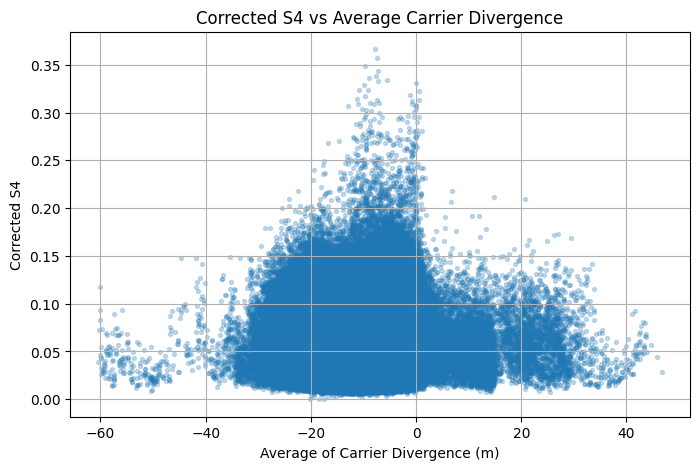

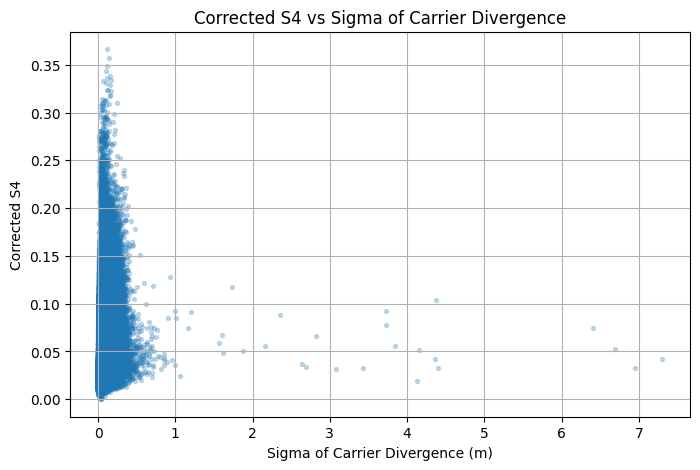


Correlation with Corrected S4:
Corrected_S4                     1.000000
Average of Carrier divergence    0.066998
Sigma of Carrier Divergence      0.314250
Name: Corrected_S4, dtype: float64

IMPORTANT:
High carrier divergence may indicate multipath contamination.
Do not remove observations using an arbitrary cutoff.
Review the plots before deciding whether an additional
receiver-specific multipath rejection rule is justified.

STEP 6: MISSING VALUE CHECK
Missing values in each column:
YYYY                                0
MM                                  0
DD                                  0
Second                              0
Total satellite                     0
PRN                                 0
Azimuth                             0
Elevation                           0
L1 CNo                              0
Total S4                            0
Correction to total S4              0
60-second phase sigma               0
Average of Carrier divergence       0
Sigma of Carr

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# GNSS S4 PREPROCESSING — 2016
# Uses the existing DataFrame: df
#
# Target: Corrected S4 - Amplitude scintillation
# S4 threshold for later classification: 0.20
#
# Quality criteria:
#   L1 Lock time > 60 seconds
#   Elevation > 25 degrees
#
# Output:
#   df_clean
#   One additional column: Corrected_S4
# ============================================================


# ============================================================
# 1. ESTABLISH THE SCIENTIFIC DEFINITION OF THE TARGET
# ============================================================

# S4 is the amplitude scintillation index.
# It measures the normalised standard deviation of received
# signal intensity.
#
# Corrected S4 will be used as the target measurement.
#
# Proposed threshold for the later binary classification:
#   Corrected S4 < 0.20  : Non-scintillation / below threshold
#   Corrected S4 >= 0.20 : Scintillation
#
# The threshold is an operational choice, not a universal
# boundary applicable to every receiver or study.

S4_THRESHOLD = 0.20


# ============================================================
# 1.5. INITIAL DATA QUALITY ASSESSMENT
# ============================================================

print("\nINITIAL DATA QUALITY ASSESSMENT")

print("Total observations:", len(df))
print("Total columns:", len(df.columns))

print("\nMissing values in original dataset:")
print(df.isna().sum())

print("\nDuplicate observations:")

duplicate_count = df.duplicated(
    subset=["_DATE", "Second", "PRN"]
).sum()

print("Duplicate rows:", duplicate_count)

print("\nDate coverage:")
print("Start:", df["_DATE"].min())
print("End:", df["_DATE"].max())
print("Unique dates:", df["_DATE"].nunique())

print("\nSatellite coverage:")
print("Unique PRNs:", df["PRN"].nunique())
print("PRNs:", sorted(df["PRN"].dropna().unique()))


# ============================================================
# 2. APPLY RECEIVER-SPECIFIC QUALITY CRITERIA
# ============================================================

# README recommendations:
# L1 Lock time > 60 seconds
# Elevation > 25 degrees

df_clean = df.copy()

initial_rows = len(df_clean)

# Record observations removed by each criterion.
# Sequential filtering prevents double-counting.

# ------------------------------------------------------------
# FILTER 1: L1 LOCK TIME
# ------------------------------------------------------------

before_lock = len(df_clean)

df_clean = df_clean.loc[
    df_clean["L1 Lock time"] > 60
].copy()

removed_lock = before_lock - len(df_clean)

# ------------------------------------------------------------
# FILTER 2: ELEVATION
# ------------------------------------------------------------

before_elevation = len(df_clean)

df_clean = df_clean.loc[
    df_clean["Elevation"] > 25
].copy()

removed_elevation = before_elevation - len(df_clean)

# ------------------------------------------------------------
# QUALITY FILTER SUMMARY
# ------------------------------------------------------------

print("\nRECEIVER-SPECIFIC QUALITY FILTERING")

print("Initial observations:", initial_rows)

print("Removed by L1 Lock time:", removed_lock)

print("Removed by Elevation:", removed_elevation)

print("Total observations removed:",
      removed_lock + removed_elevation)

print("Remaining observations:", len(df_clean))


# ============================================================
# 3. CORRECT THE S4 MEASUREMENT
# ============================================================

# The GSV4004B manual specifies an RSS correction:
#
# Corrected S4 = sqrt(Total S4^2 - Correction S4^2)
#
# If the correction is greater than Total S4, corrected S4
# is set to zero.

df_clean["Corrected_S4"] = np.sqrt(
    np.maximum(
        0,
        df_clean["Total S4"]**2 -
        df_clean["Correction to total S4"]**2
    )
)

print("\nSTEP 3: S4 CORRECTION")
print("Corrected S4 calculated.")
print("Corrected S4 minimum:", df_clean["Corrected_S4"].min())
print("Corrected S4 maximum:", df_clean["Corrected_S4"].max())


# ------------------------------------------------------------
# CORRECTED S4 STATISTICAL SUMMARY
# ------------------------------------------------------------

print("\nCORRECTED S4 STATISTICS")

print(
    df_clean["Corrected_S4"].describe()
)

print(
    "\nNegative corrected S4 values:",
    (df_clean["Corrected_S4"] < 0).sum()
)

print(
    "Missing corrected S4 values:",
    df_clean["Corrected_S4"].isna().sum()
)

print(
    "Infinite corrected S4 values:",
    np.isinf(df_clean["Corrected_S4"]).sum()
)


# ============================================================
# 4. REMOVE INVALID MEASUREMENTS AND PHYSICALLY IMPOSSIBLE VALUES
# ============================================================

# Check the validity of the observation date, time, PRN,
# satellite geometry and S4 measurements.
#
# S4 is NOT restricted to a maximum of 1 because values
# greater than 1 can occur during severe scintillation.

valid_mask = (
    df_clean["_DATE"].notna() &

    np.isfinite(df_clean["Second"]) &
    df_clean["Second"].between(0, 86399.999) &

    np.isfinite(df_clean["PRN"]) &
    (df_clean["PRN"] > 0) &
    (df_clean["PRN"] % 1 == 0) &

    np.isfinite(df_clean["Azimuth"]) &
    df_clean["Azimuth"].between(0, 360, inclusive="left") &

    np.isfinite(df_clean["Elevation"]) &
    df_clean["Elevation"].between(0, 90) &

    np.isfinite(df_clean["Total S4"]) &
    (df_clean["Total S4"] >= 0) &

    np.isfinite(df_clean["Correction to total S4"]) &
    (df_clean["Correction to total S4"] >= 0) &

    np.isfinite(df_clean["Corrected_S4"]) &
    (df_clean["Corrected_S4"] >= 0)
)

before_invalid_removal = len(df_clean)

df_clean = df_clean.loc[valid_mask].copy()

print("\nSTEP 4: INVALID MEASUREMENT REMOVAL")
print("Observations before removal:", before_invalid_removal)
print("Observations after removal:", len(df_clean))
print("Invalid observations removed:",
      before_invalid_removal - len(df_clean))

# ============================================================
# 4.5. DEFINE THE SCINTILLATION REFERENCE LABEL
# ============================================================

# Reference threshold:
# Corrected S4 < 0.20  = 0 (Below scintillation threshold)
# Corrected S4 >= 0.20 = 1 (Meets scintillation threshold)

S4_THRESHOLD = 0.20

df_clean["LABEL"] = (
    df_clean["Corrected_S4"] >= S4_THRESHOLD
).astype(int)

# ------------------------------------------------------------
# REFERENCE LABEL DISTRIBUTION
# ------------------------------------------------------------

label_counts = df_clean["LABEL"].value_counts().sort_index()

label_percentages = (
    df_clean["LABEL"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

label_summary = pd.DataFrame({
    "Observations": label_counts,
    "Percentage (%)": label_percentages
})

label_summary.index = [
    "Below S4 threshold (0)",
    "Meets S4 threshold (1)"
]

print("\nSCINTILLATION REFERENCE LABEL DISTRIBUTION")

print(label_summary)

print("\nS4 reference threshold:", S4_THRESHOLD)

print("Total labelled observations:", len(df_clean))

# ============================================================
# 4.6. VERIFY CORRECTED S4 AND LABEL CONSISTENCY
# ============================================================

# Confirm that LABEL matches the corrected S4 threshold.

label_mismatch = (
    df_clean["LABEL"] !=
    (df_clean["Corrected_S4"] >= S4_THRESHOLD).astype(int)
).sum()

print("\nREFERENCE LABEL VERIFICATION")

print("Incorrect LABEL assignments:", label_mismatch)

print(
    "Minimum corrected S4:",
    df_clean["Corrected_S4"].min()
)

print(
    "Maximum corrected S4:",
    df_clean["Corrected_S4"].max()
)

print(
    "Mean corrected S4:",
    df_clean["Corrected_S4"].mean()
)

print(
    "Median corrected S4:",
    df_clean["Corrected_S4"].median()
)

print(
    "Standard deviation:",
    df_clean["Corrected_S4"].std()
)

# ============================================================
# 5. IDENTIFY MULTIPATH CONTAMINATION
# ============================================================

# Carrier divergence measurements can help identify
# observations potentially affected by multipath.
#
# No universal carrier-divergence cutoff is imposed here.
# Therefore, observations are investigated rather than
# automatically deleted.

print("\nSTEP 5: MULTIPATH INVESTIGATION")

print("\nCarrier divergence summary:")
print(
    df_clean[
        [
            "Average of Carrier divergence",
            "Sigma of Carrier Divergence"
        ]
    ].describe()
)

# Plot 1: Corrected S4 against average carrier divergence

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Average of Carrier divergence"],
    df_clean["Corrected_S4"],
    alpha=0.25,
    s=8
)

plt.xlabel("Average of Carrier Divergence (m)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 vs Average Carrier Divergence")
plt.grid(True)
plt.show()


# Plot 2: Corrected S4 against carrier divergence sigma

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean["Sigma of Carrier Divergence"],
    df_clean["Corrected_S4"],
    alpha=0.25,
    s=8
)

plt.xlabel("Sigma of Carrier Divergence (m)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 vs Sigma of Carrier Divergence")
plt.grid(True)
plt.show()


# Check correlations as supporting diagnostic information

print("\nCorrelation with Corrected S4:")

print(
    df_clean[
        [
            "Corrected_S4",
            "Average of Carrier divergence",
            "Sigma of Carrier Divergence"
        ]
    ].corr()["Corrected_S4"]
)

print(
    "\nIMPORTANT:"
    "\nHigh carrier divergence may indicate multipath contamination."
    "\nDo not remove observations using an arbitrary cutoff."
    "\nReview the plots before deciding whether an additional"
    "\nreceiver-specific multipath rejection rule is justified."
)


# ============================================================
# 6. HANDLE MISSING VALUES CORRECTLY
# ============================================================

# Missing TEC does not invalidate an otherwise valid S4
# observation. Therefore, retain rows with missing TEC.
#
# Missing target measurements have already been excluded
# in Step 4.
#
# Optional predictor missing values are retained at this
# preprocessing stage. They can be handled later using
# training-data-only imputation.

print("\nSTEP 6: MISSING VALUE CHECK")

print("Missing values in each column:")

print(df_clean.isna().sum())

print(
    "\nMissing TEC observations:",
    df_clean["TEC at TOW"].isna().sum()
)

print(
    "Observations retained despite missing TEC:",
    df_clean["TEC at TOW"].isna().sum()
)


# ============================================================
# 7. CHECK DUPLICATE OBSERVATIONS AND DATA CONTINUITY
# ============================================================

# An observation is identified by:
#   Date + Second + PRN
#
# Duplicate observations are reported but not automatically
# removed. Their cause should be investigated first.

duplicate_mask = df_clean.duplicated(
    subset=["_DATE", "Second", "PRN"],
    keep=False
)

duplicates = df_clean.loc[duplicate_mask].sort_values(
    ["_DATE", "PRN", "Second"]
)

print("\nSTEP 7: DUPLICATE OBSERVATIONS")

print("Number of duplicate rows:", len(duplicates))
print(
    "Number of duplicated observation groups:",
    df_clean.duplicated(
        subset=["_DATE", "Second", "PRN"]
    ).sum()
)

if len(duplicates) > 0:
    print("\nExample duplicate observations:")
    print(
        duplicates[
            ["_DATE", "Second", "PRN", "Corrected_S4"]
        ].head(10)
    )
else:
    print("No duplicate observations found.")


# ------------------------------------------------------------
# CHECK DATA CONTINUITY
# ------------------------------------------------------------

# The receiver provides minutely observations.
# Check time differences for each satellite on each date.
#
# A difference greater than 60 seconds indicates a gap
# between consecutive observations.
#
# Gaps are reported, not interpolated or filled.

ordered = df_clean.sort_values(
    ["_DATE", "PRN", "Second"]
)

time_differences = (
    ordered.groupby(["_DATE", "PRN"])["Second"].diff()
)

gaps = time_differences[time_differences > 60]

print("\nDATA CONTINUITY")

print("Number of time gaps greater than 60 seconds:", len(gaps))

if len(gaps) > 0:
    print("Largest time gap (seconds):", gaps.max())
else:
    print("No gaps greater than 60 seconds found.")


# ============================================================
# FINAL PREPROCESSING SUMMARY
# ============================================================

print("\n" + "=" * 55)
print("FINAL PREPROCESSING SUMMARY")
print("=" * 55)

print("Original observations:", len(df))
print("Final cleaned observations:", len(df_clean))

print("Observation dates:", df_clean["_DATE"].nunique())
print("Unique satellite PRNs:", df_clean["PRN"].nunique())

print(
    "Date range:",
    df_clean["_DATE"].min(),
    "to",
    df_clean["_DATE"].max()
)

print(
    "Corrected S4 range:",
    df_clean["Corrected_S4"].min(),
    "to",
    df_clean["Corrected_S4"].max()
)

print("Final number of columns:", len(df_clean.columns))

print("\nREFERENCE LABEL COUNTS")

print("LABEL 0:", (df_clean["LABEL"] == 0).sum())
print("LABEL 1:", (df_clean["LABEL"] == 1).sum())

print("\nMISSING PREDICTOR VALUES")

predictor_features = [
    "L1 CNo",
    "L2 CNo",
    "Elevation",
    "Azimuth",
    "TEC at TOW",
    "Average of Carrier divergence",
    "Sigma of Carrier Divergence",
    "Total satellite"
]

print(df_clean[predictor_features].isna().sum())

print("\nCORRECTED S4 SUMMARY")

print(df_clean["Corrected_S4"].describe())

print("\nFinal DataFrame: df_clean")

Data Preprocessing (TARGET 🎯  AND DATA SPLIT)


[Reference](https://chatgpt.com/s/t_6af00195dfb88191920e0e096b1218fb)

STEP 1: CORRECTED S4 DISTRIBUTION
count    1.783960e+06
mean     4.609892e-02
std      2.327560e-02
min      0.000000e+00
25%      2.908608e-02
50%      4.116892e-02
75%      5.802474e-02
max      3.663138e-01
Name: Corrected_S4, dtype: float64


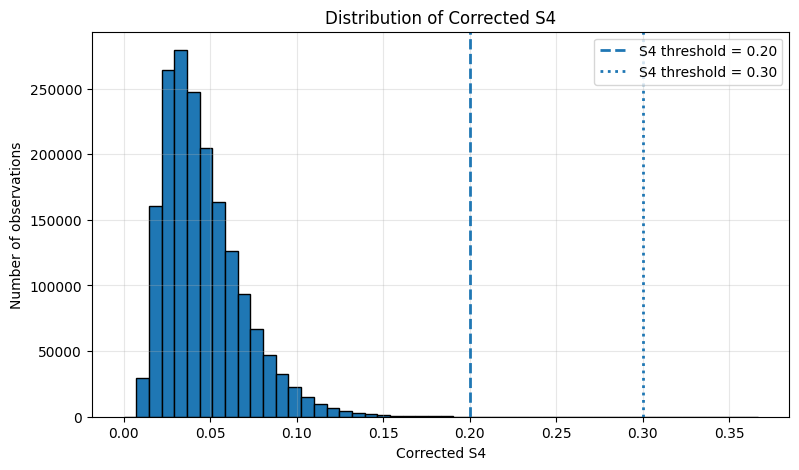


STEP 2: CREATE BINARY CLASSIFICATION LABEL
Label definition:
0 = Corrected S4 < 0.20
1 = Corrected S4 >= 0.20

STEP 3: CLASS DISTRIBUTION AT THRESHOLD 0.20
            Class   Count  Percentage
Non-scintillation 1783376   99.967264
    Scintillation     584    0.032736

STEP 4: SENSITIVITY ANALYSIS AT THRESHOLD 0.30
            Class   Count  Percentage
Non-scintillation 1783928   99.998206
    Scintillation      32    0.001794

Maximum corrected S4: 0.36631378625435324

STEP 5: FEATURE SELECTION

Selected model input features:
- L1 CNo
- L2 CNo
- Azimuth_sin
- Azimuth_cos
- Elevation
- Average of Carrier divergence
- Corrected_S4
- TEC at TOW
- Sigma of Carrier Divergence

Reference column: LABEL
Evaluation measurement: Corrected_S4

Excluded from model input:
- Total S4
- Correction to total S4
- LABEL
- YYYY
- MM
- DD
- Second
- _DATE
- PRN
- Total satellite
- Azimuth

MISSING VALUES IN SELECTED FEATURES
L1 CNo                              0
L2 CNo                              0
Az

In [8]:
# ============================================================
# GNSS SCINTILLATION CLASSIFICATION — TARGET AND DATA SPLIT
#
# Uses existing DataFrame: df_clean
#
# Target:
#   Corrected_S4 < 0.20  = 0
#   Corrected_S4 >= 0.20 = 1
#
# Chronological split:
#   70% Training
#   15% Validation
#   15% Testing
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. CHECK CORRECTED S4 DISTRIBUTION
# ============================================================

print("=" * 60)
print("STEP 1: CORRECTED S4 DISTRIBUTION")
print("=" * 60)

print(df_clean["Corrected_S4"].describe())

# Plot distribution

plt.figure(figsize=(9, 5))

plt.hist(
    df_clean["Corrected_S4"],
    bins=50,
    edgecolor="black"
)

plt.axvline(
    0.20,
    linestyle="--",
    linewidth=2,
    label="S4 threshold = 0.20"
)

plt.axvline(
    0.30,
    linestyle=":",
    linewidth=2,
    label="S4 threshold = 0.30"
)

plt.xlabel("Corrected S4")
plt.ylabel("Number of observations")
plt.title("Distribution of Corrected S4")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# ============================================================
# 2. CREATE BINARY LABEL USING 0.20
# ============================================================

print("\n" + "=" * 60)
print("STEP 2: CREATE BINARY CLASSIFICATION LABEL")
print("=" * 60)

S4_THRESHOLD = 0.20

df_clean["LABEL"] = (
    df_clean["Corrected_S4"] >= S4_THRESHOLD
).astype(int)

print("Label definition:")
print("0 = Corrected S4 < 0.20")
print("1 = Corrected S4 >= 0.20")


# ============================================================
# 3. COUNT CLASS 0 AND CLASS 1
# ============================================================

print("\n" + "=" * 60)
print("STEP 3: CLASS DISTRIBUTION AT THRESHOLD 0.20")
print("=" * 60)

class_counts = df_clean["LABEL"].value_counts().sort_index()

class_percentages = (
    df_clean["LABEL"].value_counts(normalize=True).sort_index() * 100
)

class_summary = pd.DataFrame({
    "Class": ["Non-scintillation", "Scintillation"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
    "Percentage": [
        class_percentages.get(0, 0),
        class_percentages.get(1, 0)
    ]
})

print(class_summary.to_string(index=False))


# ============================================================
# 4. CHECK 0.30 AS A SENSITIVITY THRESHOLD
# ============================================================

print("\n" + "=" * 60)
print("STEP 4: SENSITIVITY ANALYSIS AT THRESHOLD 0.30")
print("=" * 60)

# Temporary labels: no additional column is created.

labels_030 = (
    df_clean["Corrected_S4"] >= 0.30
).astype(int)

counts_030 = labels_030.value_counts().sort_index()

percentages_030 = (
    labels_030.value_counts(normalize=True).sort_index() * 100
)

sensitivity_summary = pd.DataFrame({
    "Class": ["Non-scintillation", "Scintillation"],
    "Count": [
        counts_030.get(0, 0),
        counts_030.get(1, 0)
    ],
    "Percentage": [
        percentages_030.get(0, 0),
        percentages_030.get(1, 0)
    ]
})

print(sensitivity_summary.to_string(index=False))

print("\nMaximum corrected S4:", df_clean["Corrected_S4"].max())

if df_clean["Corrected_S4"].max() < 0.30:
    print(
        "WARNING: No observations meet the 0.30 threshold. "
        "This threshold cannot produce a positive class."
    )

# ------------------------------------------------------------
# CREATE CIRCULAR AZIMUTH FEATURES
# ------------------------------------------------------------

azimuth_radians = np.deg2rad(df_clean["Azimuth"])

df_clean["Azimuth_sin"] = np.sin(azimuth_radians)
df_clean["Azimuth_cos"] = np.cos(azimuth_radians)


# ============================================================
# 5. FEATURE SELECTION AND FEATURE QUALITY ASSESSMENT
# ============================================================

print("\n" + "=" * 60)
print("STEP 5: FEATURE SELECTION")
print("=" * 60)

# ------------------------------------------------------------
# 5.1 SELECT MODEL INPUT FEATURES
# ------------------------------------------------------------

FEATURES = [
    "L1 CNo",
    "L2 CNo",
    "Azimuth_sin",
    "Azimuth_cos",
    "Elevation",
    "Average of Carrier divergence",
    "Corrected_S4",
    "TEC at TOW",
    "Sigma of Carrier Divergence"
]

TARGET = "LABEL"

# Verify required columns exist.

required_columns = FEATURES + [TARGET, "Corrected_S4", "_DATE", "PRN"]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("\nSelected model input features:")

for feature in FEATURES:
    print("-", feature)

print("\nReference column:", TARGET)
print("Evaluation measurement: Corrected_S4")


# ------------------------------------------------------------
# 5.2 EXCLUDE TARGET-RELATED AND IDENTIFICATION COLUMNS
# ------------------------------------------------------------

print("\nExcluded from model input:")

excluded_columns = [
    "Total S4",
    "Correction to total S4",
    "LABEL",
    "YYYY",
    "MM",
    "DD",
    "Second",
    "_DATE",
    "PRN",
    "Total satellite",
    "Azimuth"
]

for col in excluded_columns:
    print("-", col)


# ------------------------------------------------------------
# 5.3 CHECK MISSING AND INFINITE VALUES
# ------------------------------------------------------------

print("\nMISSING VALUES IN SELECTED FEATURES")

print(df_clean[FEATURES].isna().sum())

print("\nINFINITE VALUES IN SELECTED FEATURES")

print(
    df_clean[FEATURES]
    .apply(lambda col: np.isinf(col).sum())
)

# TEC is the only predictor allowed to have missing values
# at this stage.

unexpected_missing = (
    df_clean[FEATURES]
    .drop(columns=["TEC at TOW"])
    .isna()
    .sum()
)

if unexpected_missing.any():
    raise ValueError(
        "Unexpected missing values in predictors:\n"
        f"{unexpected_missing[unexpected_missing > 0]}"
    )

# Infinite values are not valid model inputs.

infinite_counts = (
    df_clean[FEATURES]
    .apply(lambda col: np.isinf(col).sum())
)

if infinite_counts.any():
    raise ValueError(
        "Infinite values detected in predictors:\n"
        f"{infinite_counts[infinite_counts > 0]}"
    )


# ------------------------------------------------------------
# 5.4 FEATURE SUMMARY STATISTICS
# ------------------------------------------------------------

print("\nFEATURE SUMMARY STATISTICS")

print(
    df_clean[FEATURES].describe().T
)


# ------------------------------------------------------------
# 5.5 CHECK POTENTIALLY IMPOSSIBLE FEATURE VALUES
# ------------------------------------------------------------

# These checks flag suspicious values.
# They do not automatically remove observations.

range_checks = {
    "L1 CNo": df_clean["L1 CNo"] < 0,

    "L2 CNo": df_clean["L2 CNo"] < 0,

    "Azimuth": ~df_clean["Azimuth"].between(
        0, 360, inclusive="left"
    ),

    "TEC at TOW": df_clean["TEC at TOW"] < 0,

    "Sigma of Carrier Divergence":
        df_clean["Sigma of Carrier Divergence"] < 0
}

print("\nFEATURE RANGE CHECKS")

for feature, condition in range_checks.items():
    count = condition.sum()

    print(f"{feature}: {count} potentially invalid observations")

print(
    "\nNote: These checks identify values for investigation. "
    "Do not automatically remove unusual values without "
    "receiver-specific justification."
)


# ============================================================
# 6. CHRONOLOGICAL DATA SPLIT
# ============================================================

print("\n" + "=" * 60)
print("STEP 6: CHRONOLOGICAL DATA SPLIT")
print("=" * 60)

# Sort unique observation dates.

unique_dates = np.sort(
    df_clean["_DATE"].dropna().unique()
)

n_dates = len(unique_dates)

# Allocate 70% training, 15% validation and 15% testing.

n_train = int(n_dates * 0.70)
n_val = int(n_dates * 0.15)

train_dates = unique_dates[:n_train]

val_dates = unique_dates[
    n_train:n_train + n_val
]

test_dates = unique_dates[
    n_train + n_val:
]

# Assign complete dates to each dataset.

train_df = df_clean[
    df_clean["_DATE"].isin(train_dates)
].copy()

val_df = df_clean[
    df_clean["_DATE"].isin(val_dates)
].copy()

test_df = df_clean[
    df_clean["_DATE"].isin(test_dates)
].copy()


# ------------------------------------------------------------
# 6.1 DISPLAY SPLIT INFORMATION
# ------------------------------------------------------------

def show_split(name, data):

    print(f"\n{name}")
    print("-" * 45)

    print("Observations:", len(data))
    print("Unique dates:", data["_DATE"].nunique())

    print(
        "Date range:",
        data["_DATE"].min(),
        "to",
        data["_DATE"].max()
    )

    print("\nReference label distribution:")

    counts = data[TARGET].value_counts().sort_index()

    percentages = (
        data[TARGET]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    for label in [0, 1]:

        description = (
            "Below S4 threshold"
            if label == 0
            else "Meets S4 threshold"
        )

        print(
            f"{description}: "
            f"{counts.get(label, 0):,} "
            f"({percentages.get(label, 0):.4f}%)"
        )


show_split("TRAINING DATA", train_df)
show_split("VALIDATION DATA", val_df)
show_split("TESTING DATA", test_df)


# ------------------------------------------------------------
# 6.2 VERIFY DATE OVERLAP
# ------------------------------------------------------------

print("\nDATE OVERLAP CHECK")

train_date_set = set(train_dates)
val_date_set = set(val_dates)
test_date_set = set(test_dates)

print(
    "Training-validation overlap:",
    len(train_date_set & val_date_set)
)

print(
    "Training-testing overlap:",
    len(train_date_set & test_date_set)
)

print(
    "Validation-testing overlap:",
    len(val_date_set & test_date_set)
)

if (
    len(train_date_set & val_date_set) > 0 or
    len(train_date_set & test_date_set) > 0 or
    len(val_date_set & test_date_set) > 0
):
    raise ValueError("Date overlap detected.")

print("\nChronological split completed.")


# ============================================================
# 7. NORMAL-ONLY TRAINING AND MISSING VALUE IMPUTATION
# ============================================================

print("\n" + "=" * 60)
print("STEP 7: NORMAL-ONLY TRAINING DATA")
print("=" * 60)


# # ------------------------------------------------------------
# # 7.1 SELECT NORMAL OBSERVATIONS FOR MODEL TRAINING
# # ------------------------------------------------------------

# # LABEL is used ONLY to select the normal training group.
# # LABEL is NOT included in model input features.

# train_normal_df = train_df.loc[
#     train_df[TARGET] == 0
# ].copy()

# print("All training observations:", len(train_df))

# print("Normal training observations:", len(train_normal_df))

# print(
#     "High-S4 training observations excluded:",
#     (train_df[TARGET] == 1).sum()
# )

# print(
#     "\nValidation observations:",
#     len(val_df)
# )

# print(
#     "Testing observations:",
#     len(test_df)
# )

# ------------------------------------------------------------
# 7.1 SELECT ALL TRAINING OBSERVATIONS
# ------------------------------------------------------------

# Use all training observations, including LABEL 0 and LABEL 1.
# LABEL is NOT included in model input features.

train_normal_df = train_df.loc[
    train_df[TARGET] == 0
].copy()

print("All training observations:", len(train_df))

print("Training observations used:", len(train_normal_df))

print(
    "High-S4 training observations included:",
    (train_df[TARGET] == 1).sum()
)

print(
    "\nValidation observations:",
    len(val_df)
)

print(
    "Testing observations:",
    len(test_df)
)

# ------------------------------------------------------------
# 7.2 EXTRACT MODEL INPUT FEATURES
# ------------------------------------------------------------

X_train_normal = train_normal_df[FEATURES].copy()

X_val = val_df[FEATURES].copy()

X_test = test_df[FEATURES].copy()

# Keep reference values separately for evaluation.

y_val = val_df[TARGET].copy()

y_test = test_df[TARGET].copy()

s4_val = val_df["Corrected_S4"].copy()

s4_test = test_df["Corrected_S4"].copy()


# ------------------------------------------------------------
# 7.3 HANDLE MISSING TEC
# ------------------------------------------------------------

from sklearn.impute import SimpleImputer

# Fit the imputer using training observations.

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_normal),
    columns=FEATURES,
    index=X_train_normal.index
)

# Apply the same training-derived median to validation
# and test observations.

X_val_imputed = pd.DataFrame(
    imputer.transform(X_val),
    columns=FEATURES,
    index=X_val.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=FEATURES,
    index=X_test.index
)

# Display the imputation values.

imputation_summary = pd.DataFrame({
    "Feature": FEATURES,
    "Training median used": imputer.statistics_
})

print("\nIMPUTATION VALUES")

print(imputation_summary.to_string(index=False))

print("\nMissing values after imputation:")

print("Training:", X_train_imputed.isna().sum().sum())
print("Validation:", X_val_imputed.isna().sum().sum())
print("Testing:", X_test_imputed.isna().sum().sum())


# ============================================================
# 8. FEATURE SCALING
# ============================================================

print("\n" + "=" * 60)
print("STEP 8: FEATURE SCALING")
print("=" * 60)

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 8.1 FIT SCALER USING TRAINING DATA
# ------------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_imputed),
    columns=FEATURES,
    index=X_train_imputed.index
)

# Apply the same fitted scaler to validation and test data.

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val_imputed),
    columns=FEATURES,
    index=X_val_imputed.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_imputed),
    columns=FEATURES,
    index=X_test_imputed.index
)


# ------------------------------------------------------------
# 8.2 CHECK SCALED FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

print("\nSCALED TRAINING FEATURE MEANS:")

print(X_train_scaled.mean().round(4))

print("\nSCALED TRAINING FEATURE STANDARD DEVIATIONS:")

print(X_train_scaled.std().round(4))


# ------------------------------------------------------------
# 8.3 CONFIRM NO MISSING OR INFINITE VALUES
# ------------------------------------------------------------

scaled_datasets = {
    "Training": X_train_scaled,
    "Validation": X_val_scaled,
    "Testing": X_test_scaled
}

print("\nFINAL MODEL INPUT CHECK")

for name, data in scaled_datasets.items():

    missing = data.isna().sum().sum()

    infinite = np.isinf(data.to_numpy()).sum()

    print(
        f"{name}: "
        f"Missing = {missing}, "
        f"Infinite = {infinite}"
    )

    if missing > 0 or infinite > 0:
        raise ValueError(
            f"Invalid model inputs detected in {name} data."
        )


print("\nFEATURE SCALING COMPLETED.")


# ============================================================
# 9. FINAL MODEL INPUT VERIFICATION
# ============================================================

print("\n" + "=" * 60)
print("STEP 9: FINAL MODEL INPUT VERIFICATION")
print("=" * 60)

print("\nMODEL INPUT FEATURES:")

for feature in FEATURES:
    print("-", feature)


print("\nISOLATION FOREST INPUTS:")

print("Training:", X_train_imputed.shape)
print("Validation:", X_val_imputed.shape)
print("Testing:", X_test_imputed.shape)


print("\nLOF AND ONE-CLASS SVM INPUTS:")

print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)


print("\nREFERENCE VALUES KEPT SEPARATELY:")

print("Validation LABEL:", y_val.shape)
print("Testing LABEL:", y_test.shape)

print("Validation corrected S4:", s4_val.shape)
print("Testing corrected S4:", s4_test.shape)


print("\nTRAINING DATA COMPOSITION:")

print("Total training observations:", len(X_train_normal))

print(
    "Observations below S4 threshold:",
    (train_df[TARGET] == 0).sum()
)

print(
    "Observations meeting S4 threshold:",
    (train_df[TARGET] == 1).sum()
)

print("\nALL PREPARATION STAGES COMPLETED.")

print("\nMODEL FEATURE VERIFICATION")

print("Number of features:", len(FEATURES))
print("Features:", FEATURES)

# for unsupervised models
assert "Corrected_S4" in FEATURES
assert "LABEL" not in FEATURES
assert "Elevation" in FEATURES
assert "Average of Carrier divergence" in FEATURES

assert "Total S4" not in FEATURES
assert "Correction to total S4" not in FEATURES

# for supervised models
# assert "Elevation" not in FEATURES
# assert "Average of Carrier divergence" not in FEATURES
# assert "Corrected_S4" not in FEATURES
# assert "LABEL" not in FEATURES

# if "Azimuth_sin" in FEATURES:
#     assert "Azimuth_cos" in FEATURES
#     assert "Azimuth" not in FEATURES
#     assert len(FEATURES) == 6
# else:
#     assert "Azimuth" in FEATURES
#     assert len(FEATURES) == 5

print("Feature verification passed.")

#3. Exploratory Analysis (EDA) 🌍

[Referece](https://chatgpt.com/s/t_6af000d3b4e48191a2f7aefce59cda70)


3.1 CORRECTED S4 DISTRIBUTION
count    1.783960e+06
mean     4.609892e-02
std      2.327560e-02
min      0.000000e+00
25%      2.908608e-02
50%      4.116892e-02
75%      5.802474e-02
max      3.663138e-01
Name: Corrected_S4, dtype: float64


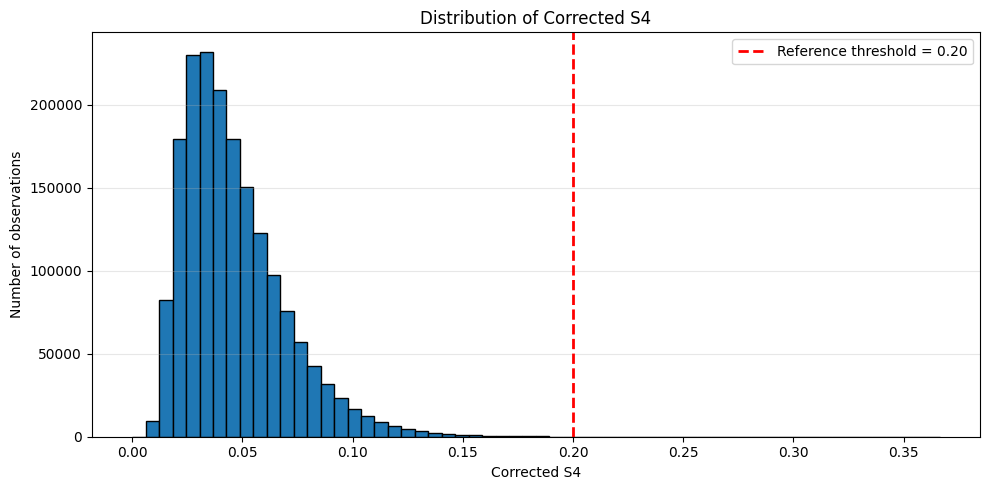


3.2 CLASS DISTRIBUTION
   Reference group  Observations  Percentage (%)
Below S4 threshold       1783376       99.967264
Meets S4 threshold           584        0.032736


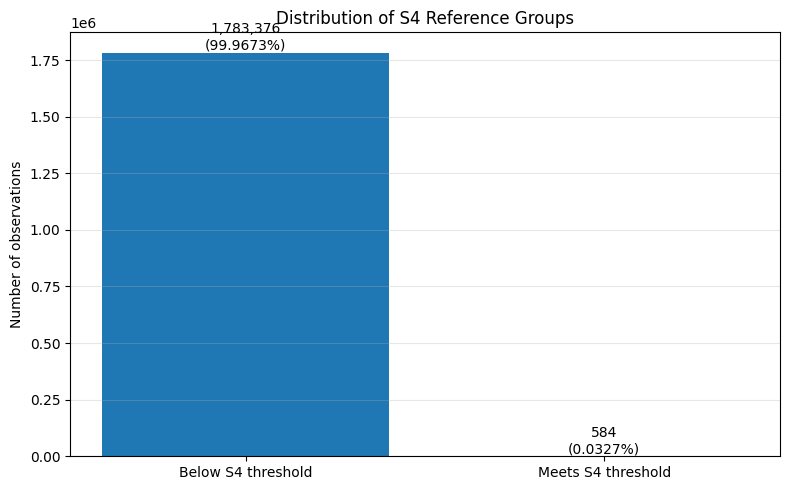


3.3 FEATURE DISTRIBUTIONS

FEATURE SUMMARY STATISTICS


,count,mean,std,min,25%,Median,50%,75%,max
L1 CNo,1783960.0,50.2974,2.8017,40.5823,48.2269,50.1977,50.1977,52.3586,57.8311
L2 CNo,1783960.0,42.1911,3.0664,26.9981,40.0487,42.4167,42.4167,44.3130,50.4612
Azimuth_sin,1783960.0,-0.0112,0.7777,-1.0000,-0.8282,-0.0458,-0.0458,0.8209,1.0000
Azimuth_cos,1783960.0,-0.2635,0.5707,-1.0000,-0.8012,-0.3240,-0.3240,0.2292,0.9208
Elevation,1783960.0,43.4660,12.8049,25.0001,32.2632,41.4068,41.4068,53.2090,73.1726
Average of Carrier divergence,1783960.0,-11.2556,5.9484,-60.4138,-15.4754,-11.0304,-11.0304,-7.0078,46.7216
Corrected_S4,1783960.0,0.0461,0.0233,0.0000,0.0291,0.0412,0.0412,0.0580,0.3663
TEC at TOW,1777117.0,6.9810,3.0772,-51.0374,4.7215,6.4270,6.4270,8.7725,34.3826
Sigma of Carrier Divergence,1783960.0,0.0538,0.0404,0.0019,0.0267,0.0444,0.0444,0.0707,7.2986


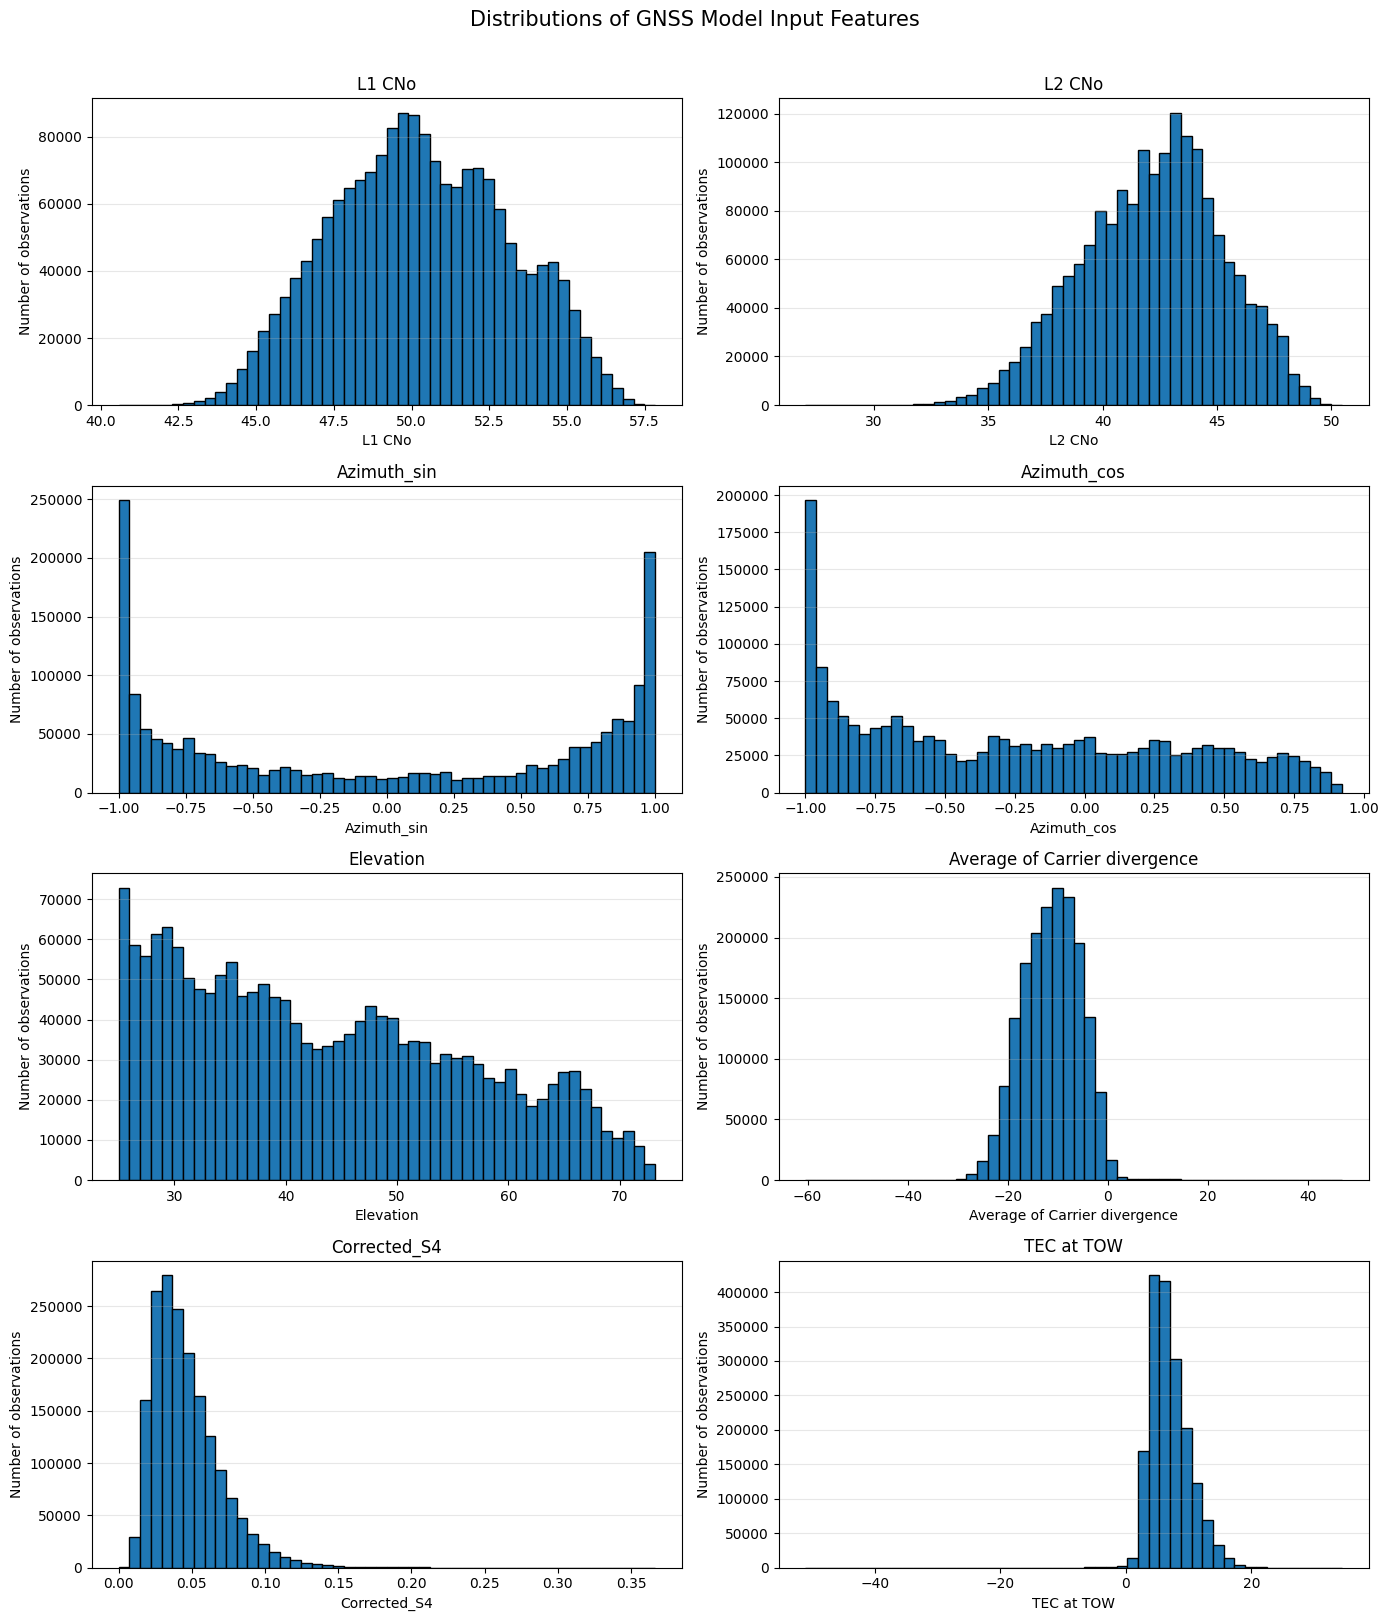


3.4 LOW-S4 VS HIGH-S4 FEATURE COMPARISON

FEATURE STATISTICS BY S4 REFERENCE GROUP


L1 CNo                    L2 CNo                  Azimuth_sin          \
          mean   median     std     mean   median     std        mean  median   
LABEL                                                                           
0      50.2990  50.1988  2.8008  42.1926  42.4180  3.0656     -0.0114 -0.0467   
1      45.5714  45.5999  0.9353  37.5860  37.6192  1.4700      0.5424  0.5490   

              Azimuth_cos  ... Average of Carrier divergence Corrected_S4  \
          std        mean  ...                           std         mean   
LABEL                      ...                                              
0      0.7777     -0.2638  ...                        5.9481        0.046   
1      0.2834      0.7276  ...                        5.1112        0.236   

                      TEC at TOW                 Sigma of Carrier Divergence  \
       median     std       mean  median     std                        mean   
LABEL                                                                          
0      0.0412  0.0230     6.9810  6.4269  3.0766                      0.0538   
1      0.2264  0.0321     7.0169  6.8161  4.5930                      0.0940   

                       
       median     std  
LABEL                  
0      0.0444  0.0404  
1      0.0739  0.0671  

[2 rows x 27 columns]

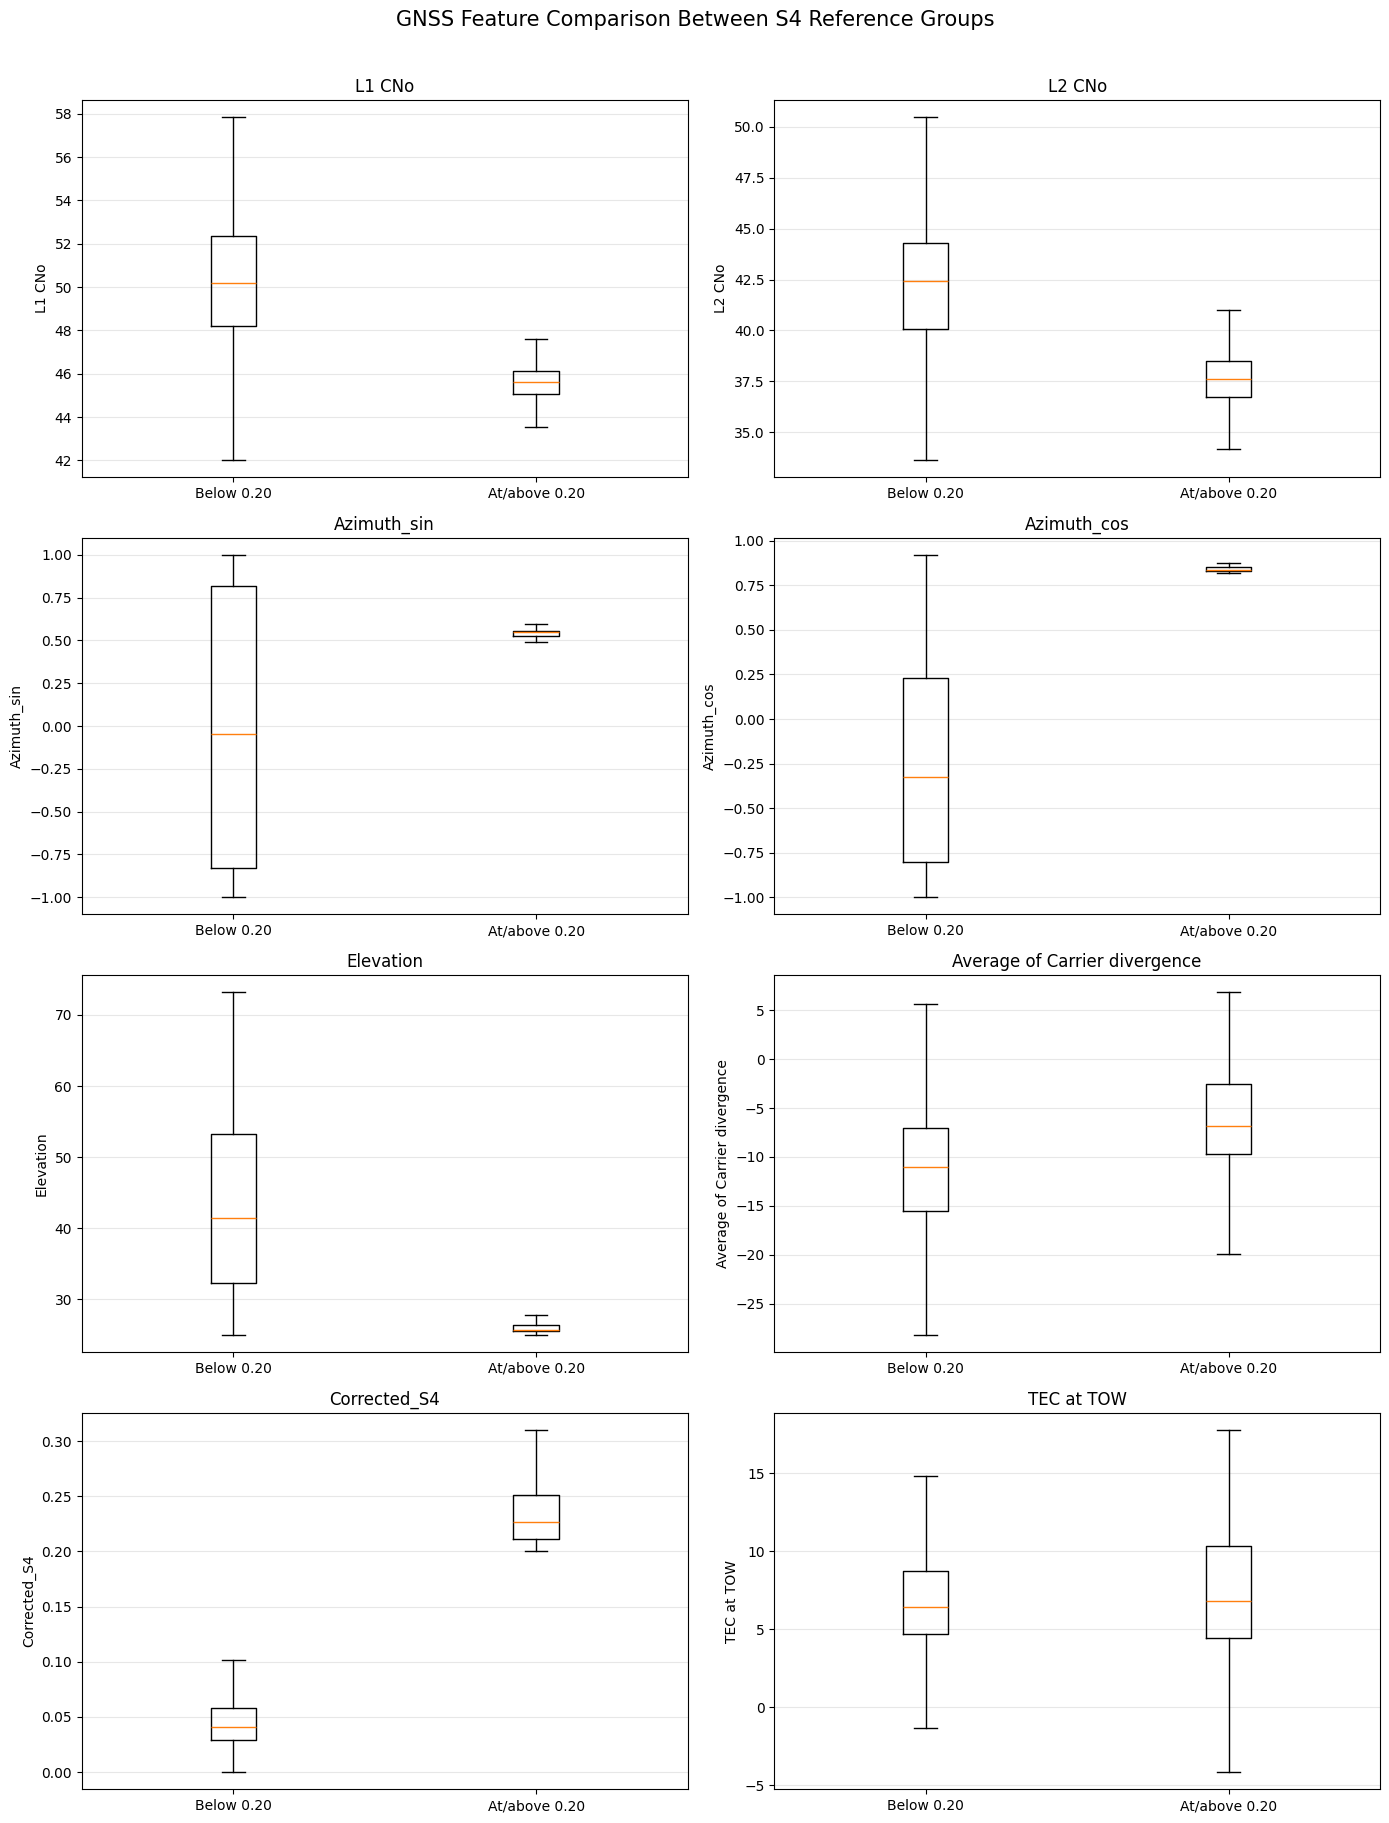


3.5 FEATURE CORRELATION ANALYSIS

SPEARMAN CORRELATION MATRIX


,L1 CNo,L2 CNo,Azimuth_sin,Azimuth_cos,Elevation,Average of Carrier divergence,Corrected_S4,TEC at TOW,Sigma of Carrier Divergence
L1 CNo,1.000,0.786,-0.080,-0.378,0.852,-0.162,-0.592,-0.286,-0.245
L2 CNo,0.786,1.000,-0.064,-0.388,0.831,-0.149,-0.521,-0.256,-0.198
Azimuth_sin,-0.080,-0.064,1.000,-0.004,-0.007,-0.380,0.149,-0.026,0.038
Azimuth_cos,-0.378,-0.388,-0.004,1.000,-0.494,0.244,0.330,0.131,0.137
Elevation,0.852,0.831,-0.007,-0.494,1.000,-0.243,-0.586,-0.339,-0.229
Average of Carrier divergence,-0.162,-0.149,-0.380,0.244,-0.243,1.000,0.078,-0.013,0.062
Corrected_S4,-0.592,-0.521,0.149,0.330,-0.586,0.078,1.000,0.258,0.337
TEC at TOW,-0.286,-0.256,-0.026,0.131,-0.339,-0.013,0.258,1.000,0.152
Sigma of Carrier Divergence,-0.245,-0.198,0.038,0.137,-0.229,0.062,0.337,0.152,1.000


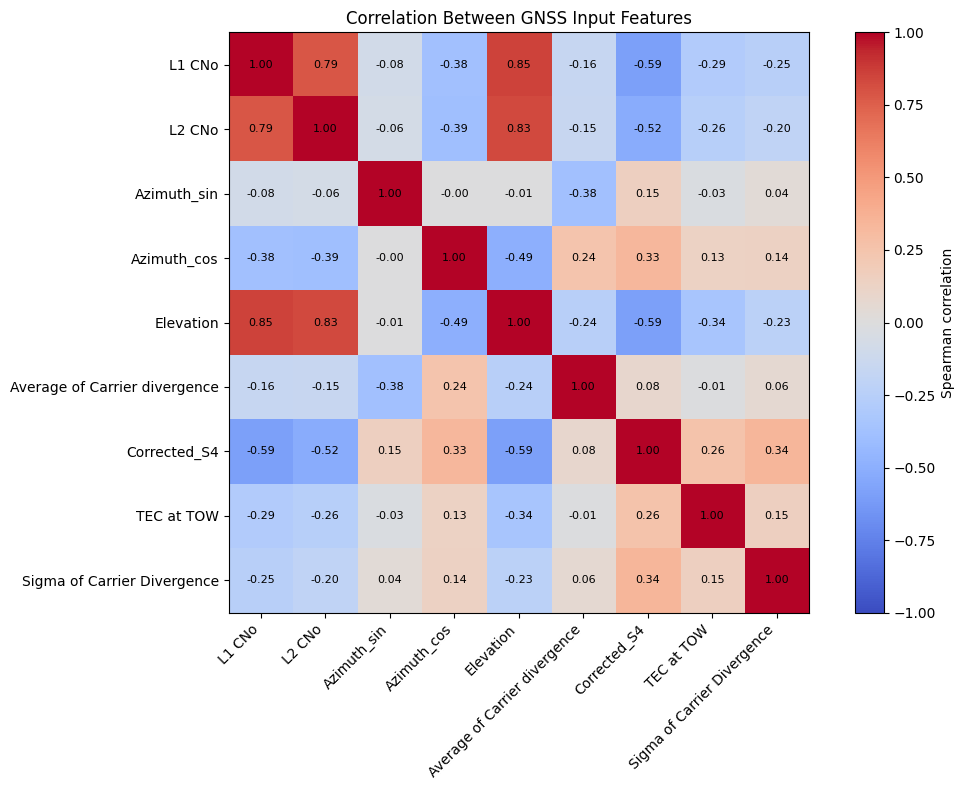


FEATURE PAIRS WITH ABSOLUTE CORRELATION >= 0.70


,Feature 1,Feature 2,Spearman correlation
0,L1 CNo,L2 CNo,0.785575
1,L1 CNo,Elevation,0.851918
2,L2 CNo,Elevation,0.830527



3.6 TEMPORAL OCCURRENCE ANALYSIS

HOURLY OCCURRENCE RATE


,Hour,Total_Observations,Scintillation_Observations,Occurrence_Rate (%)
0,0,76792,5,0.0065
1,1,77797,3,0.0039
2,2,76760,5,0.0065
3,3,75093,12,0.0160
4,4,75259,5,0.0066
5,5,76139,16,0.0210
6,6,76799,25,0.0326
7,7,75951,27,0.0355
8,8,76054,34,0.0447
9,9,74909,27,0.0360


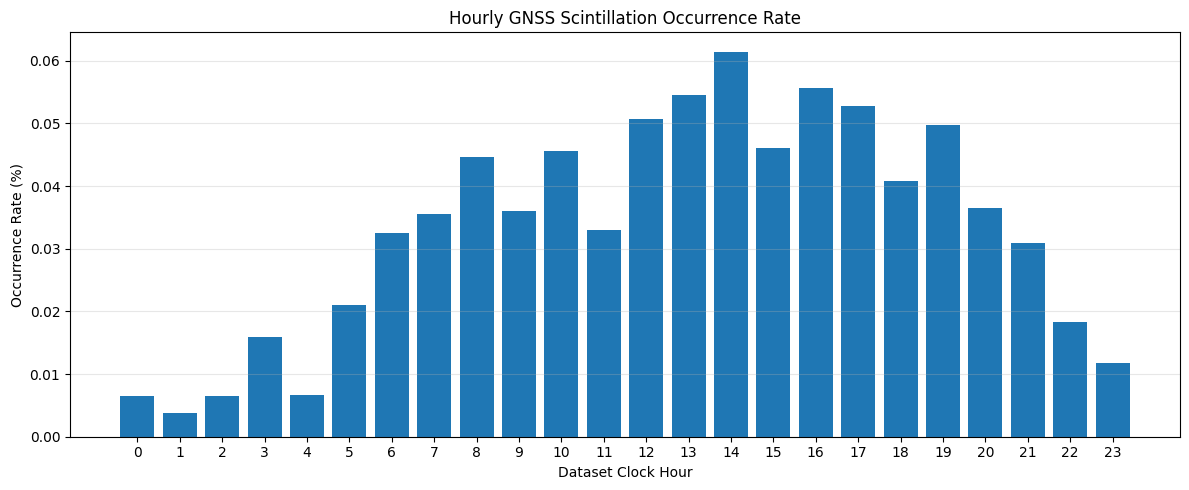


MONTHLY OCCURRENCE RATE


,Month,Total_Observations,Scintillation_Observations,Occurrence_Rate (%),Month_Name
0,1,188246.0,72.0,0.0382,January
1,2,213923.0,55.0,0.0257,February
2,3,236931.0,61.0,0.0257,March
3,4,189679.0,63.0,0.0332,April
4,5,68987.0,11.0,0.0159,May
5,6,NaN,NaN,NaN,June
6,7,NaN,NaN,NaN,July
7,8,NaN,NaN,NaN,August
8,9,148712.0,46.0,0.0309,September
9,10,242236.0,88.0,0.0363,October


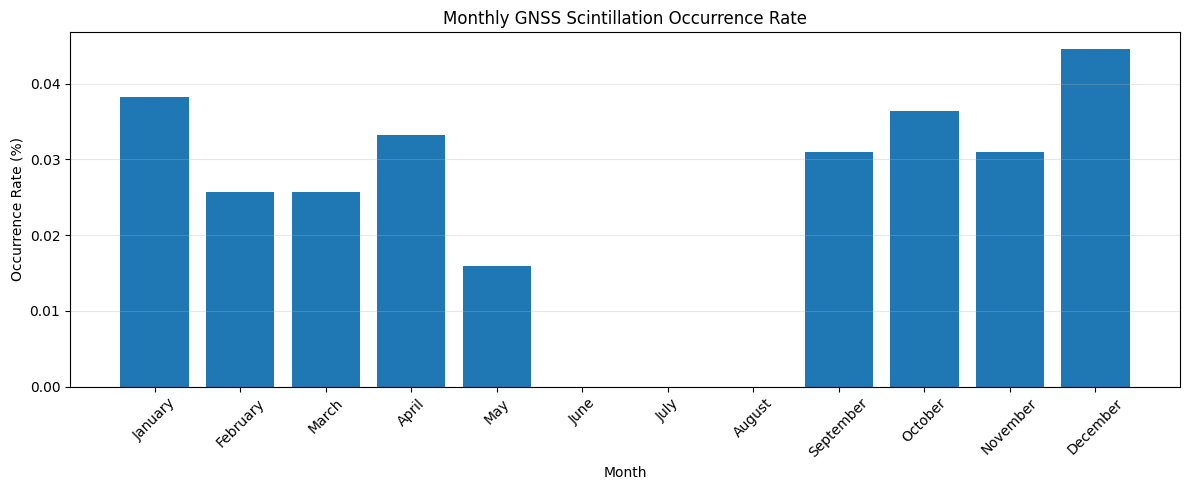


OCCURRENCE RATE BY TIME PERIOD


,Time_Period,Total_Observations,Scintillation_Observations,Occurrence_Rate (%)
0,Night (00-05),457840,46,0.0100
1,Morning (06-11),456286,173,0.0379
2,Afternoon (12-17),424013,227,0.0535
3,Evening (18-23),445821,138,0.0310


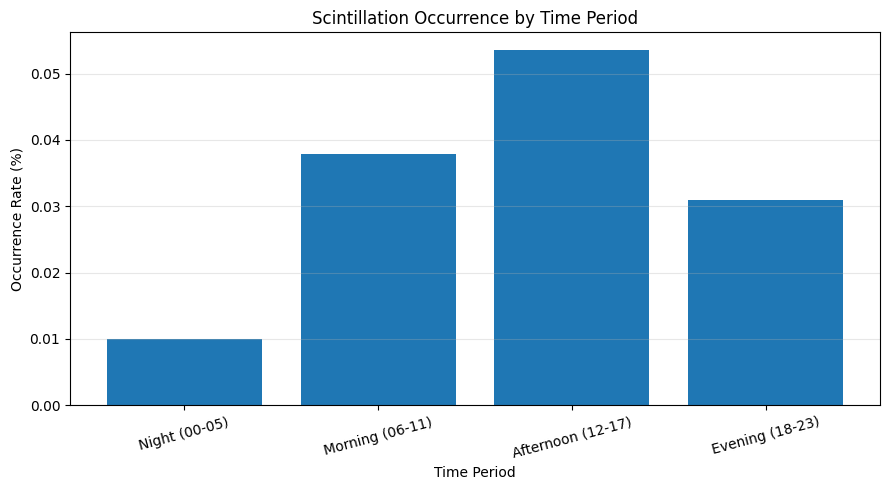


HIGHEST OCCURRENCE RATES
Hour: 14:00 (0.0615%)
Month: December (0.0445%)
Time period: Afternoon (12-17) (0.0535%)

IMPORTANT: Months without observations are missing coverage, not months with zero scintillation.
Time values represent dataset clock time; do not call them local time or UT unless the timezone is confirmed.

3.7 SATELLITE AND ELEVATION ANALYSIS

OCCURRENCE RATE BY SATELLITE PRN


,Total_Observations,High_S4_Observations,Occurrence_Rate (%)
PRN,,,
1,54167,185,0.3415
8,64550,147,0.2277
26,62472,111,0.1777
27,59262,49,0.0827
15,60045,13,0.0217
5,65275,11,0.0169
16,66510,9,0.0135
13,55915,7,0.0125
10,60097,7,0.0116


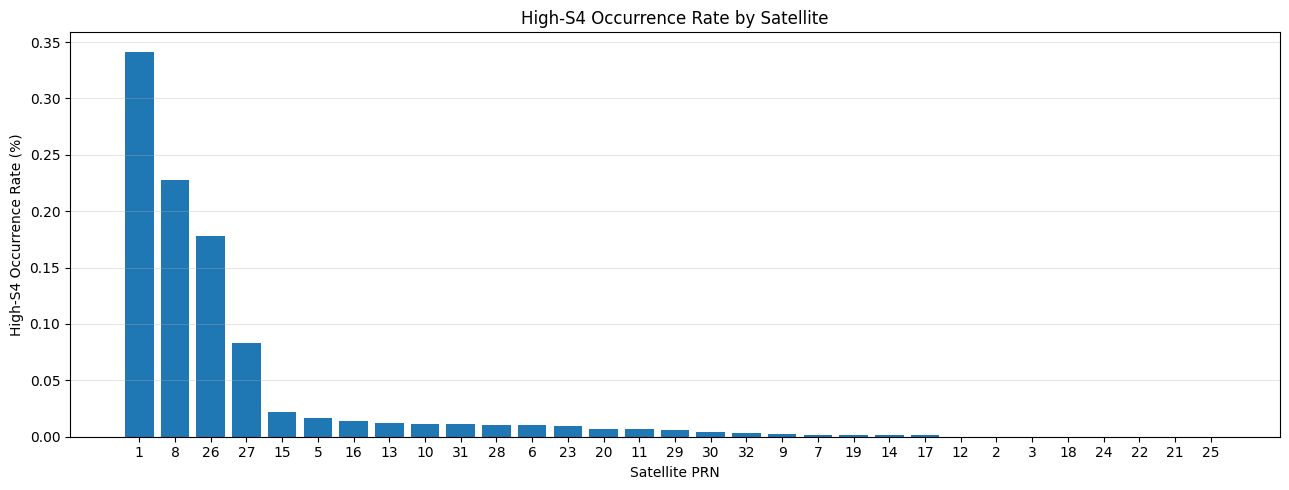

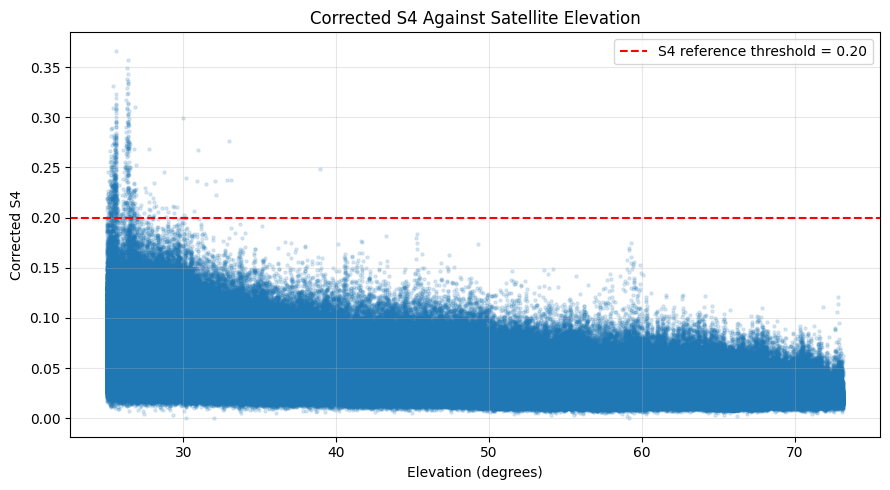


HIGH-S4 OCCURRENCE BY ELEVATION RANGE


,Elevation_Group,Total_Observations,High_S4_Observations,Occurrence_Rate (%)
0,"[25, 35)",585859,583,0.0995
1,"[35, 45)",431199,1,0.0002
2,"[45, 55)",376679,0,0.0000
3,"[55, 65)",262749,0,0.0000
4,"[65, 75)",127474,0,0.0000
5,"[75, 90)",0,0,NaN


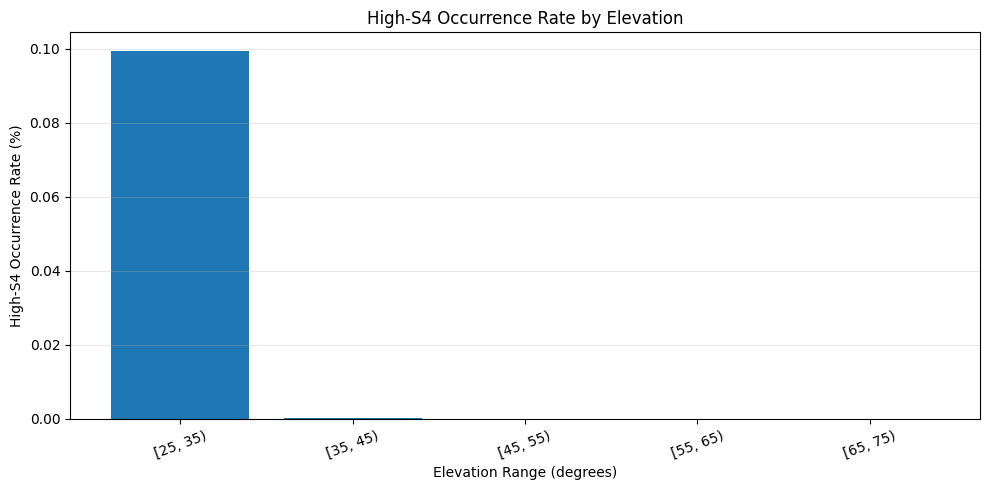


3.8 TEMPORAL CLUSTERING AND EVENT BEHAVIOUR

POSITIVE RUN SUMMARY
Total positive observations: 584
Total computationally grouped positive runs: 570
Positive observations accounted for: 584

Positive run duration statistics:


,Duration_Minutes
count,570.000000
mean,0.024561
std,0.195090
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,2.000000



NUMBER OF POSITIVE OBSERVATIONS PER RUN


,Positive_Observations_Per_Run,Number_of_Runs
0,1,560
1,2,6
2,3,4


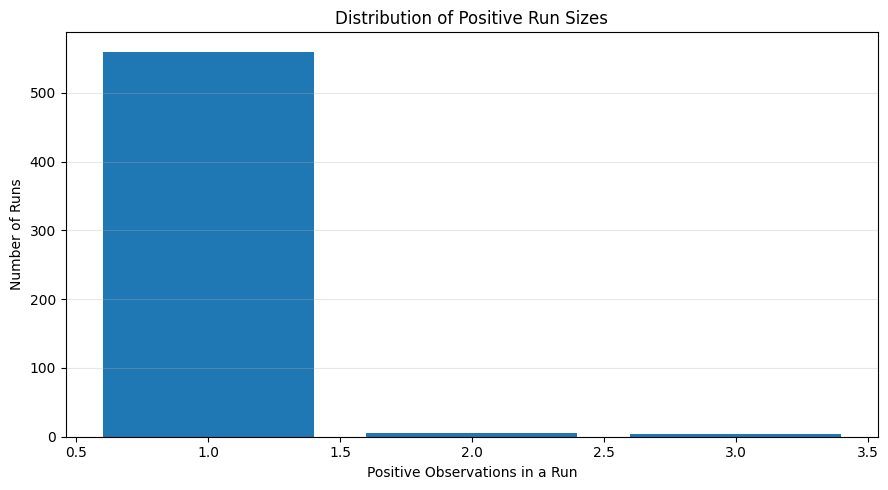


POSITIVE RUN DURATION DISTRIBUTION


,Duration_Minutes,Number_of_Runs
0,0.0,560
1,1.0,6
2,2.0,4


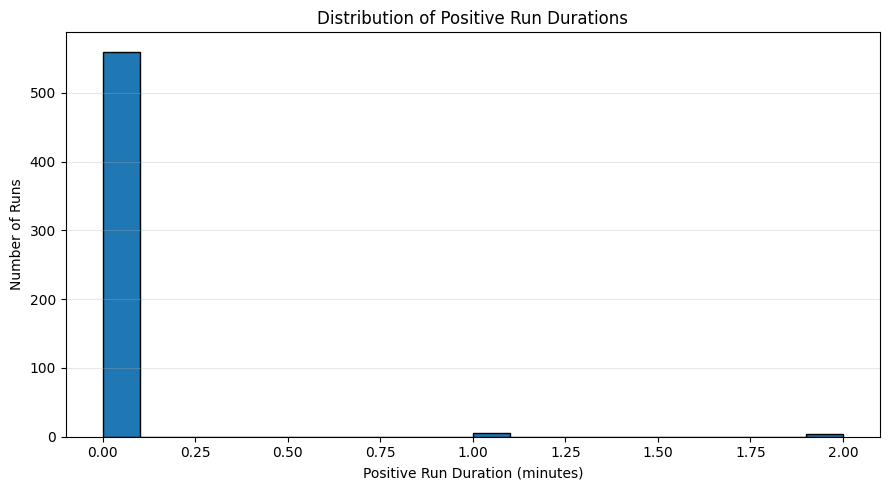


TIME GAPS BETWEEN POSITIVE RUNS


,Gap_From_Previous_Run_Minutes
count,547.000000
mean,9962.038391
std,40783.089539
min,2.000000
25%,1436.000000
50%,1436.000000
75%,2871.000000
max,455188.000000


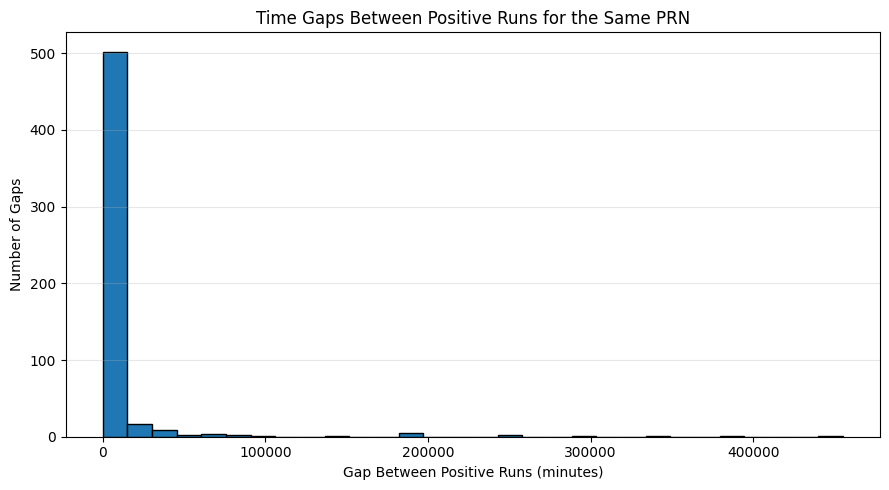


POSITIVE RUNS LASTING AT LEAST TWO MINUTES
Total positive runs: 570
Runs lasting at least two minutes: 4
Positive observations contained in these runs: 12


,Event_ID,PRN,Start_Time,End_Time,Number_of_Observations,Mean_Corrected_S4,Maximum_Corrected_S4,Duration_Minutes,Previous_Run_End,Gap_From_Previous_Run_Minutes
34,16_4,16,2019-11-05 13:44:00,2019-11-05 13:46:00,3,0.250089,0.275939,2.0,2019-11-01 13:41:00,5763.0
274,26_4,26,2019-01-04 09:26:00,2019-01-04 09:28:00,3,0.223542,0.233355,2.0,2019-01-03 11:01:00,1345.0
380,27_8,27,2019-03-24 07:18:00,2019-03-24 07:20:00,3,0.206141,0.210621,2.0,2019-03-22 08:03:00,2835.0
353,27_21,27,2019-04-14 05:59:00,2019-04-14 06:01:00,3,0.211559,0.222146,2.0,2019-04-05 07:05:00,12894.0



FINAL POSITIVE RUN SUMMARY
Total high-S4 observations: 584
Total positive runs: 570
Single-observation runs: 560
Runs lasting at least two minutes: 4
Maximum run duration (minutes): 2.0

NOTE: These runs are defined using the selected one-minute continuity rule. They should not automatically be interpreted as independent physical scintillation events.


In [9]:
# ============================================================
# 3.1 OVERALL CORRECTED S4 DISTRIBUTION
# ============================================================

print("\n" + "=" * 60)
print("3.1 CORRECTED S4 DISTRIBUTION")
print("=" * 60)

print(df_clean["Corrected_S4"].describe())

plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["Corrected_S4"],
    bins=60,
    edgecolor="black"
)

plt.axvline(
    0.20,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Reference threshold = 0.20"
)

plt.xlabel("Corrected S4")
plt.ylabel("Number of observations")
plt.title("Distribution of Corrected S4")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.2 CLASS IMBALANCE AND SCINTILLATION OCCURRENCE
# ============================================================

print("\n" + "=" * 60)
print("3.2 CLASS DISTRIBUTION")
print("=" * 60)

class_counts = (
    df_clean["LABEL"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

class_percentages = (
    df_clean["LABEL"]
    .value_counts(normalize=True)
    .reindex([0, 1], fill_value=0) * 100
)

class_summary = pd.DataFrame({
    "Reference group": [
        "Below S4 threshold",
        "Meets S4 threshold"
    ],
    "Observations": class_counts.values,
    "Percentage (%)": class_percentages.values
})

print(class_summary.to_string(index=False))

# Plot class distribution

plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Below S4 threshold", "Meets S4 threshold"],
    class_counts.values
)

for bar, percentage in zip(bars, class_percentages.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{bar.get_height():,.0f}\n({percentage:.4f}%)",
        ha="center",
        va="bottom"
    )

plt.ylabel("Number of observations")
plt.title("Distribution of S4 Reference Groups")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.3 DISTRIBUTION OF THE EIGHT MODEL INPUT FEATURES
# ============================================================

print("\n" + "=" * 60)
print("3.3 FEATURE DISTRIBUTIONS")
print("=" * 60)

# Summary statistics

feature_summary = df_clean[FEATURES].describe().T

feature_summary["Median"] = df_clean[FEATURES].median()

feature_summary = feature_summary[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "Median",
        "50%",
        "75%",
        "max"
    ]
]

print("\nFEATURE SUMMARY STATISTICS")

display(feature_summary.round(4))


# ------------------------------------------------------------
# HISTOGRAMS FOR ALL EIGHT FEATURES
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for feature, ax in zip(FEATURES, axes.flatten()):

    values = df_clean[feature].dropna()

    ax.hist(
        values,
        bins=50,
        edgecolor="black"
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of observations")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Distributions of GNSS Model Input Features",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 3.4 FEATURE COMPARISON BETWEEN S4 REFERENCE GROUPS
# ============================================================

print("\n" + "=" * 60)
print("3.4 LOW-S4 VS HIGH-S4 FEATURE COMPARISON")
print("=" * 60)

# ------------------------------------------------------------
# SUMMARY STATISTICS BY REFERENCE GROUP
# ------------------------------------------------------------

group_summary = (
    df_clean
    .groupby("LABEL")[FEATURES]
    .agg(["mean", "median", "std"])
)

print("\nFEATURE STATISTICS BY S4 REFERENCE GROUP")

display(group_summary.round(4))


# ------------------------------------------------------------
# BOXPLOTS FOR ALL EIGHT FEATURES
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for feature, ax in zip(FEATURES, axes.flatten()):

    group_0 = df_clean.loc[
        df_clean["LABEL"] == 0, feature
    ].dropna()

    group_1 = df_clean.loc[
        df_clean["LABEL"] == 1, feature
    ].dropna()

    ax.boxplot(
        [group_0, group_1],
        tick_labels=[
            "Below 0.20",
            "At/above 0.20"
        ],
        showfliers=False
    )

    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "GNSS Feature Comparison Between S4 Reference Groups",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()

# ============================================================
# 3.5 CORRELATION ANALYSIS OF MODEL INPUT FEATURES
# ============================================================

print("\n" + "=" * 60)
print("3.5 FEATURE CORRELATION ANALYSIS")
print("=" * 60)

# Spearman correlation is used because some GNSS features
# may have skewed distributions and nonlinear monotonic relationships.

correlation_matrix = df_clean[FEATURES].corr(
    method="spearman"
)

print("\nSPEARMAN CORRELATION MATRIX")

display(correlation_matrix.round(3))


# ------------------------------------------------------------
# CORRELATION HEATMAP
# ------------------------------------------------------------

plt.figure(figsize=(11, 8))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(
    image,
    label="Spearman correlation"
)

plt.xticks(
    range(len(FEATURES)),
    FEATURES,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(FEATURES)),
    FEATURES
)

for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):

        plt.text(
            j,
            i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Between GNSS Input Features")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# IDENTIFY HIGHLY CORRELATED FEATURE PAIRS
# ------------------------------------------------------------

correlation_pairs = []

for i in range(len(FEATURES)):

    for j in range(i + 1, len(FEATURES)):

        value = correlation_matrix.iloc[i, j]

        if abs(value) >= 0.70:

            correlation_pairs.append({
                "Feature 1": FEATURES[i],
                "Feature 2": FEATURES[j],
                "Spearman correlation": value
            })

print("\nFEATURE PAIRS WITH ABSOLUTE CORRELATION >= 0.70")

if correlation_pairs:

    display(pd.DataFrame(correlation_pairs))

else:

    print("No feature pairs exceed the selected 0.70 threshold.")

# ============================================================
# 3.6 TEMPORAL SCINTILLATION OCCURRENCE ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("3.6 TEMPORAL OCCURRENCE ANALYSIS")
print("=" * 60)

# Use the existing _DATE column.
# Second contains seconds since midnight.

df_clean["Hour"] = (
    df_clean["Second"] // 3600
).astype(int)

df_clean["Month"] = df_clean["_DATE"].dt.month

# ------------------------------------------------------------
# 3.6.1 HOURLY OCCURRENCE RATE
# ------------------------------------------------------------

hourly_results = (
    df_clean.groupby("Hour")
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reindex(range(24), fill_value=0)
    .reset_index()
)

hourly_results["Occurrence_Rate (%)"] = (
    hourly_results["Scintillation_Observations"] /
    hourly_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nHOURLY OCCURRENCE RATE")

display(hourly_results.round(4))

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_results["Hour"],
    hourly_results["Occurrence_Rate (%)"]
)

plt.xticks(range(24))
plt.xlabel("Dataset Clock Hour")
plt.ylabel("Occurrence Rate (%)")
plt.title("Hourly GNSS Scintillation Occurrence Rate")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.2 MONTHLY OCCURRENCE RATE
# ------------------------------------------------------------

monthly_results = (
    df_clean.groupby("Month")
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reindex(range(1, 13))
    .reset_index()
)

# Months without observations remain NaN, not zero.

monthly_results["Occurrence_Rate (%)"] = (
    monthly_results["Scintillation_Observations"] /
    monthly_results["Total_Observations"]
) * 100

monthly_results["Month_Name"] = pd.to_datetime(
    monthly_results["Month"],
    format="%m"
).dt.strftime("%B")

print("\nMONTHLY OCCURRENCE RATE")

display(monthly_results.round(4))

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_results["Month_Name"],
    monthly_results["Occurrence_Rate (%)"]
)

plt.xlabel("Month")
plt.ylabel("Occurrence Rate (%)")
plt.title("Monthly GNSS Scintillation Occurrence Rate")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.3 OCCURRENCE RATE BY TIME PERIOD
# ------------------------------------------------------------

df_clean["Time_Period"] = pd.cut(
    df_clean["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "Night (00-05)",
        "Morning (06-11)",
        "Afternoon (12-17)",
        "Evening (18-23)"
    ]
)

period_results = (
    df_clean.groupby("Time_Period", observed=False)
    .agg(
        Total_Observations=("LABEL", "count"),
        Scintillation_Observations=("LABEL", "sum")
    )
    .reset_index()
)

period_results["Occurrence_Rate (%)"] = (
    period_results["Scintillation_Observations"] /
    period_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nOCCURRENCE RATE BY TIME PERIOD")

display(period_results.round(4))

plt.figure(figsize=(9, 5))

plt.bar(
    period_results["Time_Period"].astype(str),
    period_results["Occurrence_Rate (%)"]
)

plt.xlabel("Time Period")
plt.ylabel("Occurrence Rate (%)")
plt.title("Scintillation Occurrence by Time Period")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.6.4 IDENTIFY HIGHEST OCCURRENCE RATES
# ------------------------------------------------------------

highest_hour = hourly_results.loc[
    hourly_results["Occurrence_Rate (%)"].idxmax()
]

valid_months = monthly_results.dropna(
    subset=["Occurrence_Rate (%)"]
)

highest_month = valid_months.loc[
    valid_months["Occurrence_Rate (%)"].idxmax()
]

highest_period = period_results.loc[
    period_results["Occurrence_Rate (%)"].idxmax()
]

print("\nHIGHEST OCCURRENCE RATES")

print(
    f"Hour: {int(highest_hour['Hour']):02d}:00 "
    f"({highest_hour['Occurrence_Rate (%)']:.4f}%)"
)

print(
    f"Month: {highest_month['Month_Name']} "
    f"({highest_month['Occurrence_Rate (%)']:.4f}%)"
)

print(
    f"Time period: {highest_period['Time_Period']} "
    f"({highest_period['Occurrence_Rate (%)']:.4f}%)"
)

print(
    "\nIMPORTANT: Months without observations are missing coverage, "
    "not months with zero scintillation."
)

print(
    "Time values represent dataset clock time; "
    "do not call them local time or UT unless the timezone is confirmed."
)

# ============================================================
# 3.7 SATELLITE AND ELEVATION ANALYSIS
# ============================================================

print("\n" + "=" * 60)
print("3.7 SATELLITE AND ELEVATION ANALYSIS")
print("=" * 60)


# ------------------------------------------------------------
# 3.7.1 OBSERVATION COUNTS AND OCCURRENCE RATE BY PRN
# ------------------------------------------------------------

prn_results = (
    df_clean.groupby("PRN")
    .agg(
        Total_Observations=("LABEL", "count"),
        High_S4_Observations=("LABEL", "sum")
    )
)

prn_results["Occurrence_Rate (%)"] = (
    prn_results["High_S4_Observations"] /
    prn_results["Total_Observations"]
) * 100

prn_results = prn_results.sort_values(
    "Occurrence_Rate (%)",
    ascending=False
)

print("\nOCCURRENCE RATE BY SATELLITE PRN")

display(prn_results.round(4))


# Plot occurrence rate by PRN

plt.figure(figsize=(13, 5))

plt.bar(
    prn_results.index.astype(str),
    prn_results["Occurrence_Rate (%)"]
)

plt.xlabel("Satellite PRN")
plt.ylabel("High-S4 Occurrence Rate (%)")
plt.title("High-S4 Occurrence Rate by Satellite")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.7.2 CORRECTED S4 AGAINST ELEVATION
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["Elevation"],
    df_clean["Corrected_S4"],
    alpha=0.15,
    s=5
)

plt.axhline(
    0.20,
    color="red",
    linestyle="--",
    label="S4 reference threshold = 0.20"
)

plt.xlabel("Elevation (degrees)")
plt.ylabel("Corrected S4")
plt.title("Corrected S4 Against Satellite Elevation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.7.3 HIGH-S4 OCCURRENCE BY ELEVATION RANGE
# ------------------------------------------------------------

elevation_bins = [25, 35, 45, 55, 65, 75, 90]

df_clean["Elevation_Group"] = pd.cut(
    df_clean["Elevation"],
    bins=elevation_bins,
    right=False,
    include_lowest=True
)

elevation_results = (
    df_clean.groupby("Elevation_Group", observed=False)
    .agg(
        Total_Observations=("LABEL", "count"),
        High_S4_Observations=("LABEL", "sum")
    )
    .reset_index()
)

elevation_results["Occurrence_Rate (%)"] = (
    elevation_results["High_S4_Observations"] /
    elevation_results["Total_Observations"].replace(0, np.nan)
) * 100

print("\nHIGH-S4 OCCURRENCE BY ELEVATION RANGE")

display(elevation_results.round(4))


# Plot occurrence rate by elevation group

plt.figure(figsize=(10, 5))

plt.bar(
    elevation_results["Elevation_Group"].astype(str),
    elevation_results["Occurrence_Rate (%)"]
)

plt.xlabel("Elevation Range (degrees)")
plt.ylabel("High-S4 Occurrence Rate (%)")
plt.title("High-S4 Occurrence Rate by Elevation")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3.8 TEMPORAL CLUSTERING AND POSITIVE RUN ANALYSIS
#
# Positive run definition:
# 1. Same satellite PRN
# 2. Consecutive LABEL = 1 observations
# 3. Exactly 60 seconds between observations
#
# A positive run is a computational grouping, not necessarily
# an independent physical scintillation event.
# ============================================================

print("\n" + "=" * 60)
print("3.8 TEMPORAL CLUSTERING AND EVENT BEHAVIOUR")
print("=" * 60)


# ------------------------------------------------------------
# 3.8.1 CREATE TIMESTAMP
# ------------------------------------------------------------

# Use the existing date and seconds since midnight.

df_clean["Timestamp"] = (
    df_clean["_DATE"] +
    pd.to_timedelta(df_clean["Second"], unit="s")
)

# Sort observations separately by satellite and time.

df_clean.sort_values(
    ["PRN", "Timestamp"],
    inplace=True
)


# ------------------------------------------------------------
# 3.8.2 IDENTIFY CONSECUTIVE POSITIVE RUNS
# ------------------------------------------------------------

# Previous observation for the same satellite.

previous_label = (
    df_clean.groupby("PRN")["LABEL"].shift()
)

time_gap = (
    df_clean.groupby("PRN")["Timestamp"].diff()
)

# A new run begins when:
# - Current observation is positive, AND
# - Previous observation was not positive, OR
# - Time gap is not exactly 60 seconds.

event_start = (
    (df_clean["LABEL"] == 1) &
    (
        (previous_label != 1) |
        (time_gap != pd.Timedelta(seconds=60))
    )
)

# Number each positive run separately for each PRN.

event_number = (
    event_start.groupby(df_clean["PRN"]).cumsum()
)

# Assign IDs only to positive observations.

df_clean["Event_ID"] = np.where(
    df_clean["LABEL"] == 1,
    (
        df_clean["PRN"].astype(str) +
        "_" +
        event_number.astype(str)
    ),
    None
)


# ------------------------------------------------------------
# 3.8.3 SUMMARISE ALL POSITIVE RUNS
# ------------------------------------------------------------

positive_runs = (
    df_clean[df_clean["LABEL"] == 1]
    .groupby("Event_ID")
    .agg(
        PRN=("PRN", "first"),
        Start_Time=("Timestamp", "min"),
        End_Time=("Timestamp", "max"),
        Number_of_Observations=("LABEL", "count"),
        Mean_Corrected_S4=("Corrected_S4", "mean"),
        Maximum_Corrected_S4=("Corrected_S4", "max")
    )
    .reset_index()
)

# Calculate actual elapsed duration.

positive_runs["Duration_Minutes"] = (
    positive_runs["End_Time"] -
    positive_runs["Start_Time"]
).dt.total_seconds() / 60

# Sort events.

positive_runs.sort_values(
    ["PRN", "Start_Time"],
    inplace=True
)

print("\nPOSITIVE RUN SUMMARY")

print("Total positive observations:", int(df_clean["LABEL"].sum()))

print("Total computationally grouped positive runs:",
      len(positive_runs))

print(
    "Positive observations accounted for:",
    positive_runs["Number_of_Observations"].sum()
)

print("\nPositive run duration statistics:")

display(
    positive_runs["Duration_Minutes"].describe()
)


# ------------------------------------------------------------
# 3.8.4 DISTRIBUTION OF OBSERVATIONS PER POSITIVE RUN
# ------------------------------------------------------------

run_size_distribution = (
    positive_runs["Number_of_Observations"]
    .value_counts()
    .sort_index()
    .reset_index()
)

run_size_distribution.columns = [
    "Positive_Observations_Per_Run",
    "Number_of_Runs"
]

print("\nNUMBER OF POSITIVE OBSERVATIONS PER RUN")

display(run_size_distribution)


plt.figure(figsize=(9, 5))

plt.bar(
    run_size_distribution["Positive_Observations_Per_Run"],
    run_size_distribution["Number_of_Runs"]
)

plt.xlabel("Positive Observations in a Run")
plt.ylabel("Number of Runs")
plt.title("Distribution of Positive Run Sizes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.5 POSITIVE RUN DURATION DISTRIBUTION
# ------------------------------------------------------------

duration_distribution = (
    positive_runs["Duration_Minutes"]
    .value_counts()
    .sort_index()
    .reset_index()
)

duration_distribution.columns = [
    "Duration_Minutes",
    "Number_of_Runs"
]

print("\nPOSITIVE RUN DURATION DISTRIBUTION")

display(duration_distribution)


plt.figure(figsize=(9, 5))

plt.hist(
    positive_runs["Duration_Minutes"],
    bins=20,
    edgecolor="black"
)

plt.xlabel("Positive Run Duration (minutes)")
plt.ylabel("Number of Runs")
plt.title("Distribution of Positive Run Durations")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.6 TIME GAPS BETWEEN POSITIVE RUNS
# ------------------------------------------------------------

# Calculate the gap from the previous positive run's end
# to the next positive run's start, for the same PRN.

positive_runs["Previous_Run_End"] = (
    positive_runs.groupby("PRN")["End_Time"].shift()
)

positive_runs["Gap_From_Previous_Run_Minutes"] = (
    positive_runs["Start_Time"] -
    positive_runs["Previous_Run_End"]
).dt.total_seconds() / 60

run_gaps = positive_runs[
    "Gap_From_Previous_Run_Minutes"
].dropna()

print("\nTIME GAPS BETWEEN POSITIVE RUNS")

display(run_gaps.describe())

plt.figure(figsize=(9, 5))

plt.hist(
    run_gaps,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Gap Between Positive Runs (minutes)")
plt.ylabel("Number of Gaps")
plt.title("Time Gaps Between Positive Runs for the Same PRN")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3.8.7 RUNS LASTING AT LEAST TWO MINUTES
# ------------------------------------------------------------

MIN_EVENT_DURATION = 2

event_results = positive_runs[
    positive_runs["Duration_Minutes"] >= MIN_EVENT_DURATION
].copy()

print("\nPOSITIVE RUNS LASTING AT LEAST TWO MINUTES")

print("Total positive runs:", len(positive_runs))

print("Runs lasting at least two minutes:", len(event_results))

print(
    "Positive observations contained in these runs:",
    event_results["Number_of_Observations"].sum()
)

display(event_results.head(20))


# ------------------------------------------------------------
# 3.8.8 SUMMARY OF POSITIVE RUNS
# ------------------------------------------------------------

print("\nFINAL POSITIVE RUN SUMMARY")

print("Total high-S4 observations:",
      int(df_clean["LABEL"].sum()))

print("Total positive runs:",
      len(positive_runs))

print(
    "Single-observation runs:",
    (positive_runs["Number_of_Observations"] == 1).sum()
)

print(
    "Runs lasting at least two minutes:",
    len(event_results)
)

print(
    "Maximum run duration (minutes):",
    positive_runs["Duration_Minutes"].max()
)

print(
    "\nNOTE: These runs are defined using the selected "
    "one-minute continuity rule. They should not automatically "
    "be interpreted as independent physical scintillation events."
)

#4. Anomaly Detection (Modelling)

[Concept Reference ](https://chatgpt.com/s/t_6af01a6e9acc81918365184c9543509d)

Check if existing data is ready

In [13]:
# ============================================================
# WORKFLOW 4 — CELL 1
# CHECK EXISTING DATA PREPARATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import time
import warnings
import json
import os

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    average_precision_score,
    roc_auc_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    precision_recall_curve
)

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# EXPERIMENT SETTINGS
# ------------------------------------------------------------

RANDOM_STATE = 42

TARGET = "LABEL"
S4_COLUMN = "Corrected_S4"

S4_THRESHOLD = 0.20

# ------------------------------------------------------------
# TRAINING DATA SETTINGS
# ------------------------------------------------------------

# Percentage of training observations used for each model.

# Isolation Forest: all training classes
ISOLATION_FOREST_TRAIN_FRACTION = 0.1

# LOF and One-Class SVM: normal observations only
KERNEL_MODEL_TRAIN_FRACTION = 0.1

# Sampling options:
# 0.10 = 10% of the relevant training dataset
# 1.00 = 100% of the relevant training dataset

# Date-stratified sampling.
USE_DATE_STRATIFIED_SAMPLING = True

# Reproducibility.
RANDOM_STATE = 42

# Maximum number of rows scored in one batch.
PREDICTION_BATCH_SIZE = 20000

# Minimum precision required during optional threshold selection.
# None means no minimum-precision restriction.
MIN_PRECISION = None

# Save results.
OUTPUT_FOLDER = "workflow4_results"
os.makedirs(OUTPUT_FOLDER, exist_ok=True)


# ------------------------------------------------------------
# CHECK REQUIRED VARIABLES
# ------------------------------------------------------------

required_variables = [
    "train_df",
    "train_normal_df",
    "X_train_normal",
    "X_val",
    "X_test",
    "X_train_imputed",
    "X_val_imputed",
    "X_test_imputed",
    "X_train_scaled",
    "X_val_scaled",
    "X_test_scaled",
    "y_val",
    "y_test",
    "FEATURES",
    "df_clean"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables: {missing_variables}. "
        "Run your existing Workflow 4 data-preparation cells first."
    )


# ------------------------------------------------------------
# BASIC CHECKS
# ------------------------------------------------------------

assert len(X_val) == len(y_val)
assert len(X_test) == len(y_test)

assert list(X_train_imputed.columns) == FEATURES
assert list(X_val_imputed.columns) == FEATURES
assert list(X_test_imputed.columns) == FEATURES

assert list(X_train_scaled.columns) == FEATURES
assert list(X_val_scaled.columns) == FEATURES
assert list(X_test_scaled.columns) == FEATURES

assert not np.isinf(X_train_imputed.to_numpy()).any()
assert not np.isinf(X_val_imputed.to_numpy()).any()
assert not np.isinf(X_test_imputed.to_numpy()).any()

assert not np.isnan(X_train_imputed.to_numpy()).any()
assert not np.isnan(X_val_imputed.to_numpy()).any()
assert not np.isnan(X_test_imputed.to_numpy()).any()

assert not np.isinf(X_train_scaled.to_numpy()).any()
assert not np.isinf(X_val_scaled.to_numpy()).any()
assert not np.isinf(X_test_scaled.to_numpy()).any()

assert not np.isnan(X_train_scaled.to_numpy()).any()
assert not np.isnan(X_val_scaled.to_numpy()).any()
assert not np.isnan(X_test_scaled.to_numpy()).any()


# ------------------------------------------------------------
# DISPLAY DATA PREPARATION AND TRAINING SETTINGS
# ------------------------------------------------------------

def show_date_range(name, data):
    if "_DATE" not in data.columns:
        print(f"{name}: '_DATE' column not found.")
        return

    dates = pd.to_datetime(data["_DATE"], errors="coerce").dropna()

    if dates.empty:
        print(f"{name}: No valid dates found.")
        return

    print(f"{name}:")
    print(f"  Start date: {dates.min().date()}")
    print(f"  End date:   {dates.max().date()}")
    print(f"  Unique dates: {dates.nunique():,}")
    print(f"  Observations: {len(data):,}")


print("=" * 65)
print("WORKFLOW 4 — DATA AND TRAINING SETTINGS")
print("=" * 65)

print("\n1. MODEL INPUT FEATURES")
print("-" * 65)
print("Features:", FEATURES)
print("Number of features:", len(FEATURES))

print("\n2. CONFIGURED TRAINING FRACTIONS")
print("-" * 65)
print(
    f"Isolation Forest training fraction: "
    f"{ISOLATION_FOREST_TRAIN_FRACTION:.1%}"
)
print(
    f"LOF / One-Class SVM training fraction: "
    f"{KERNEL_MODEL_TRAIN_FRACTION:.1%}"
)
print(
    f"Date-stratified sampling: "
    f"{USE_DATE_STRATIFIED_SAMPLING}"
)

print("\n3. AVAILABLE DATASET SIZES")
print("-" * 65)
print(f"All training observations:    {len(train_df):,}")
print(f"Validation observations:      {len(X_val):,}")
print(f"Test observations:             {len(X_test):,}")

print("\n4. DATASET DATE RANGES")
print("-" * 65)

show_date_range("Training dataset", train_df)
show_date_range("Validation dataset", val_df)
show_date_range("Test dataset", test_df)

print("\n5. REFERENCE LABEL COUNTS")
print("-" * 65)

# Validation
val_positive = int((y_val == 1).sum())
val_negative = int((y_val == 0).sum())
val_total = len(y_val)
val_positive_pct = (val_positive / val_total) * 100

# Test
test_positive = int((y_test == 1).sum())
test_negative = int((y_test == 0).sum())
test_total = len(y_test)
test_positive_pct = (test_positive / test_total) * 100

print(f"Validation positive labels: {val_positive:,} ({val_positive_pct:.3f}%)")
print(f"Validation negative labels: {val_negative:,} ({100 - val_positive_pct:.3f}%)")
print(f"Test positive labels:       {test_positive:,} ({test_positive_pct:.3f}%)")
print(f"Test negative labels:       {test_negative:,} ({100 - test_positive_pct:.3f}%)")

print("\n6. PREPARED FEATURE DATA SHAPES")
print("-" * 65)
print("Training:", X_train_normal.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("\nDATA CHECK PASSED")

WORKFLOW 4 — DATA AND TRAINING SETTINGS

1. MODEL INPUT FEATURES
-----------------------------------------------------------------
Features: ['L1 CNo', 'L2 CNo', 'Azimuth_sin', 'Azimuth_cos', 'Elevation', 'Average of Carrier divergence', 'Corrected_S4', 'TEC at TOW', 'Sigma of Carrier Divergence']
Number of features: 9

2. CONFIGURED TRAINING FRACTIONS
-----------------------------------------------------------------
Isolation Forest training fraction: 10.0%
LOF / One-Class SVM training fraction: 10.0%
Date-stratified sampling: True

3. AVAILABLE DATASET SIZES
-----------------------------------------------------------------
All training observations:    1,246,808
Validation observations:      264,410
Test observations:             272,742

4. DATASET DATE RANGES
-----------------------------------------------------------------
Training dataset:
  Start date: 2019-01-01
  End date:   2019-10-26
  Unique dates: 156
  Observations: 1,246,808
Validation dataset:
  Start date: 2019-10-27
 

In [16]:
# ============================================================
# WORKFLOW 4 — CELL 2
# SELECT NORMAL TRAINING DATA FOR EACH MODEL
# ============================================================

# ------------------------------------------------------------
# DATE-STRATIFIED SAMPLING FUNCTION
# ------------------------------------------------------------

def make_date_stratified_sample(
    source_df,
    sample_size,
    random_state=42
):
    """Select a reproducible sample proportionally across dates."""

    if sample_size >= len(source_df):
        return source_df.copy()

    if "_DATE" not in source_df.columns:
        raise KeyError("Missing '_DATE' column.")

    rng = np.random.RandomState(random_state)

    date_groups = [
        group for _, group in source_df.groupby("_DATE", sort=True)
    ]

    exact_allocations = np.array([
        sample_size * len(group) / len(source_df)
        for group in date_groups
    ])

    allocations = np.floor(exact_allocations).astype(int)

    remaining = sample_size - allocations.sum()

    remainders = exact_allocations - allocations

    for i in np.argsort(-remainders):
        if remaining == 0:
            break

        if allocations[i] < len(date_groups[i]):
            allocations[i] += 1
            remaining -= 1

    selected_parts = []

    for group, n in zip(date_groups, allocations):
        if n > 0:
            selected_parts.append(
                group.sample(
                    n=int(n),
                    random_state=int(rng.randint(0, 1_000_000))
                )
            )

    return pd.concat(selected_parts).sort_index()

# ------------------------------------------------------------
# VALIDATE NORMAL-ONLY TRAINING DATA
# ------------------------------------------------------------

if len(train_normal_df) == 0:
    raise ValueError("Normal training dataset is empty.")

if not train_normal_df.index.is_unique:
    raise ValueError("Normal training indices are not unique.")

if not (train_normal_df[TARGET] == 0).all():
    raise ValueError("train_normal_df contains non-normal observations.")

if not train_normal_df.index.equals(X_train_imputed.index):
    raise ValueError("Normal training and imputed feature indices do not match.")

if not train_normal_df.index.equals(X_train_scaled.index):
    raise ValueError("Normal training and scaled feature indices do not match.")

print("Normal-only training data and feature indices verified.")

# ------------------------------------------------------------
# SELECT all OBSERVATIONS FOR LOF AND ONE-CLASS SVM
# ------------------------------------------------------------

train_normal_df = train_df.loc[
    train_df[TARGET] == 0
].copy()


# ------------------------------------------------------------
# DETERMINE MODEL TRAINING SAMPLE SIZES
# ------------------------------------------------------------

TOTAL_IF_TRAINING = len(train_normal_df)

TOTAL_NORMAL_TRAINING = len(train_normal_df)#Changed train_normal_df for experiments

IF_TRAIN_SIZE = int(np.ceil(
    TOTAL_IF_TRAINING * ISOLATION_FOREST_TRAIN_FRACTION
))

KERNEL_TRAIN_SIZE = int(np.ceil(
    TOTAL_NORMAL_TRAINING * KERNEL_MODEL_TRAIN_FRACTION
))

# ------------------------------------------------------------
# ISOLATION FOREST — ALL TRAINING OBSERVATIONS
# ------------------------------------------------------------

if ISOLATION_FOREST_TRAIN_FRACTION == 1.0:

    if_train_df = train_normal_df.copy()

elif USE_DATE_STRATIFIED_SAMPLING:

    if_train_df = make_date_stratified_sample(
        source_df=train_normal_df,
        sample_size=IF_TRAIN_SIZE,
        random_state=RANDOM_STATE
    )

else:

    if_train_df = train_normal_df.sample(
    n=IF_TRAIN_SIZE,
    random_state=RANDOM_STATE
    ).sort_index()


X_train_if_sample = X_train_imputed.loc[
    if_train_df.index, FEATURES
].copy()

# ------------------------------------------------------------
# LOF AND ONE-CLASS SVM — MATCHED TRAINING SAMPLE
# ------------------------------------------------------------

if KERNEL_MODEL_TRAIN_FRACTION == 1.0:

    kernel_train_df = train_normal_df.copy()

elif USE_DATE_STRATIFIED_SAMPLING:

    kernel_train_df = make_date_stratified_sample(
        source_df=train_normal_df,
        sample_size=KERNEL_TRAIN_SIZE,
        random_state=RANDOM_STATE
    )

else:

    kernel_train_df = train_normal_df.sample(
        n=KERNEL_TRAIN_SIZE,
        random_state=RANDOM_STATE
    ).sort_index()

# Extract scaled features using the newly selected training indices.

X_train_scaled_sample = X_train_scaled.loc[
    kernel_train_df.index, FEATURES
].copy()

# ------------------------------------------------------------
# VERIFY MODEL INPUTS
# ------------------------------------------------------------

assert len(X_train_if_sample) == IF_TRAIN_SIZE
assert len(X_train_scaled_sample) == len(kernel_train_df)

assert X_train_if_sample.index.equals(if_train_df.index)
assert X_train_scaled_sample.index.equals(kernel_train_df.index)

assert list(X_train_if_sample.columns) == FEATURES
assert list(X_train_scaled_sample.columns) == FEATURES

assert not np.isnan(X_train_if_sample.to_numpy()).any()
assert not np.isnan(X_train_scaled_sample.to_numpy()).any()

assert np.isfinite(X_train_if_sample.to_numpy()).all()
assert np.isfinite(X_train_scaled_sample.to_numpy()).all()


# ------------------------------------------------------------
# REPORT TRAINING DATA SELECTION AND CLASS COMPOSITION
# ------------------------------------------------------------

print("=" * 75)
print("MODEL TRAINING DATA SELECTION")
print("=" * 75)

# Overall training data
print(f"Total training observations: {len(train_df):,}")

# Isolation Forest sample
if_positive = int((if_train_df[TARGET] == 1).sum())
if_negative = int((if_train_df[TARGET] == 0).sum())
if_total = len(if_train_df)
if_positive_pct = (if_positive / if_total) * 100

print("\nISOLATION FOREST")
print(f"Configured fraction: {ISOLATION_FOREST_TRAIN_FRACTION:.1%}")
print(f"Training observations: {if_total:,}")
print(f"Percentage of normal training data used: {if_total / len(train_normal_df):.2%}")
print(f"Positive labels: {if_positive:,} ({if_positive_pct:.3f}%)")
print(f"Negative labels: {if_negative:,} ({100 - if_positive_pct:.3f}%)")

# LOF and One-Class SVM sample
kernel_positive = int((kernel_train_df[TARGET] == 1).sum())
kernel_negative = int((kernel_train_df[TARGET] == 0).sum())
kernel_total = len(kernel_train_df)
kernel_positive_pct = (kernel_positive / kernel_total) * 100

print("\nLOF AND ONE-CLASS SVM")
print(f"Configured fraction: {KERNEL_MODEL_TRAIN_FRACTION:.1%}")
print(f"Training observations: {kernel_total:,}")
print(f"Actual percentage used: {kernel_total / len(train_normal_df):.2%}")
print(f"Positive labels: {kernel_positive:,} ({kernel_positive_pct:.3f}%)")
print(f"Negative labels: {kernel_negative:,} ({100 - kernel_positive_pct:.3f}%)")

# Validation data
val_positive = int((y_val == 1).sum())
val_negative = int((y_val == 0).sum())
val_positive_pct = (val_positive / len(y_val)) * 100

# Test data
test_positive = int((y_test == 1).sum())
test_negative = int((y_test == 0).sum())
test_positive_pct = (test_positive / len(y_test)) * 100

print("\nVALIDATION DATA")
print(f"Total observations: {len(y_val):,}")
print(f"Positive labels: {val_positive:,} ({val_positive_pct:.3f}%)")
print(f"Negative labels: {val_negative:,} ({100 - val_positive_pct:.3f}%)")

print("\nTEST DATA")
print(f"Total observations: {len(y_test):,}")
print(f"Positive labels: {test_positive:,} ({test_positive_pct:.3f}%)")
print(f"Negative labels: {test_negative:,} ({100 - test_positive_pct:.3f}%)")

print("\nTraining data selection and class verification completed.")

Normal-only training data and feature indices verified.
MODEL TRAINING DATA SELECTION
Total training observations: 1,246,808

ISOLATION FOREST
Configured fraction: 10.0%
Training observations: 124,643
Percentage of normal training data used: 10.00%
Positive labels: 0 (0.000%)
Negative labels: 124,643 (100.000%)

LOF AND ONE-CLASS SVM
Configured fraction: 10.0%
Training observations: 124,643
Actual percentage used: 10.00%
Positive labels: 0 (0.000%)
Negative labels: 124,643 (100.000%)

VALIDATION DATA
Total observations: 264,410
Positive labels: 84 (0.032%)
Negative labels: 264,326 (99.968%)

TEST DATA
Total observations: 272,742
Positive labels: 119 (0.044%)
Negative labels: 272,623 (99.956%)

Training data selection and class verification completed.


In [17]:
# ============================================================
# WORKFLOW 4 — CELL 3
# BASELINE MODEL TRAINING AND SCORING
# ============================================================

def score_in_batches(model, X, model_name, batch_size=20000):
    """
    Generate anomaly scores in batches.

    Higher score = more anomalous.
    """

    all_scores = []

    for start in range(0, len(X), batch_size):

        end = min(start + batch_size, len(X))
        X_batch = X.iloc[start:end]

        if model_name == "Isolation Forest":
            scores = -model.score_samples(X_batch)

        elif model_name == "LOF":
            scores = -model.score_samples(X_batch)

        elif model_name == "One-Class SVM":
            scores = -model.decision_function(X_batch).ravel()

        else:
            raise ValueError("Unknown model name.")

        all_scores.extend(np.asarray(scores).ravel())

    return np.asarray(all_scores)


def get_default_anomaly_threshold(model, model_name):

    """
    Convert each model's default decision boundary
    into the common higher-is-more-anomalous score scale.
    """

    if model_name == "Isolation Forest":
        return -float(model.offset_)

    elif model_name == "LOF":
        return -float(model.offset_)

    elif model_name == "One-Class SVM":
        return 0.0

    else:
        raise ValueError("Unknown model name.")


# ------------------------------------------------------------
# BASELINE CONFIGURATIONS
# ------------------------------------------------------------

baseline_configs = {

    "Isolation Forest": {
        "n_estimators": 100,
        "max_samples": 256,
        "max_features": 1.0,
        "bootstrap": False,
        "contamination": 0.2,
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    },

    "LOF": {
        "n_neighbors": 20,
        "metric": "minkowski",
        "p": 2,
        "leaf_size": 30,
        "contamination": "auto",
        "novelty": True,
        "n_jobs": -1
    },

    "One-Class SVM": {
        "kernel": "rbf",
        "nu": 0.01,
        "gamma": "scale",
        "tol": 0.001,
        "cache_size": 2000
    }
}


# ------------------------------------------------------------
# FIT AND SCORE
# ------------------------------------------------------------

baseline_models = {}
baseline_results = {}

for model_name, config in baseline_configs.items():

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    start_time = time.time()

    if model_name == "Isolation Forest":

        model = IsolationForest(**config)
        X_fit = X_train_if_sample

        X_validation = X_val_imputed
        X_testing = X_test_imputed

    elif model_name == "LOF":

        model = LocalOutlierFactor(**config)
        X_fit = X_train_scaled_sample

        X_validation = X_val_scaled
        X_testing = X_test_scaled

    else:

        model = OneClassSVM(**config)
        X_fit = X_train_scaled_sample

        X_validation = X_val_scaled
        X_testing = X_test_scaled

    # Isolation Forest: fit using all selected training observations.
    # LOF and One-Class SVM: fit using normal-only training observations.
    # No LABEL values are supplied to any model.

    model.fit(X_fit)

    fit_seconds = time.time() - start_time

    print(f"Training time: {fit_seconds:.2f} seconds")

    # Score validation observations.
    validation_start = time.time()

    val_scores = score_in_batches(
        model,
        X_validation,
        model_name,
        PREDICTION_BATCH_SIZE
    )

    validation_seconds = time.time() - validation_start

    # Score test observations.
    test_start = time.time()

    test_scores = score_in_batches(
        model,
        X_testing,
        model_name,
        PREDICTION_BATCH_SIZE
    )

    test_seconds = time.time() - test_start

    # Default model threshold.
    default_threshold = get_default_anomaly_threshold(
        model,
        model_name
    )

    baseline_models[model_name] = model

    baseline_results[model_name] = {
        "model": model,
        "config": config.copy(),
        "validation_scores": val_scores,
        "test_scores": test_scores,
        "default_threshold": default_threshold,
        "fit_seconds": fit_seconds,
        "validation_seconds": validation_seconds,
        "test_seconds": test_seconds,
        "training_sample_size": len(X_fit)
    }

    print("Validation scoring time:", round(validation_seconds, 2))
    print("Test scoring time:", round(test_seconds, 2))
    print("Default anomaly threshold:", default_threshold)

    print(
        "Validation score range:",
        round(val_scores.min(), 6),
        "to",
        round(val_scores.max(), 6)
    )

    print(
        "Test score range:",
        round(test_scores.min(), 6),
        "to",
        round(test_scores.max(), 6)
    )

print("\nBASELINE TRAINING COMPLETED.")


TRAINING: Isolation Forest
Training time: 3.26 seconds
Validation scoring time: 2.8
Test scoring time: 2.13
Default anomaly threshold: 0.5023533850573497
Validation score range: 0.410874 to 0.663485
Test score range: 0.408701 to 0.671301

TRAINING: LOF
Training time: 53.26 seconds
Validation scoring time: 70.93
Test scoring time: 70.72
Default anomaly threshold: 1.5
Validation score range: 0.946962 to 31.740056
Test score range: 0.944326 to 3.750991

TRAINING: One-Class SVM
Training time: 229.63 seconds
Validation scoring time: 21.21
Test scoring time: 22.72
Default anomaly threshold: 0.0
Validation score range: -31.202877 to 46.148343
Test score range: -31.204665 to 46.097327

BASELINE TRAINING COMPLETED.


In [20]:
# ============================================================
# WORKFLOW 4 — REUSABLE MODEL COMPARISON VISUALISATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_model_comparison(
    results,
    title="Model Performance Comparison",
    model_col="Model",
    metrics=None
):

    if metrics is None:
        metrics = {
            "Recall": "Recall",
            "F1": "F1",
            "ROC-AUC": "ROC_AUC",
            "PR-AUC": "PR_AUC",
            "MCC": "MCC"
        }

    # Check required columns
    required = [model_col] + list(metrics.values())

    missing = [
        col for col in required
        if col not in results.columns
    ]

    if missing:
        raise ValueError(
            f"Missing columns for comparison plot: {missing}\n"
            f"Available columns: {list(results.columns)}"
        )

    # Prepare plotting data
    plot_data = results[[model_col] + list(metrics.values())].copy()

    for col in metrics.values():
        plot_data[col] = pd.to_numeric(
            plot_data[col],
            errors="coerce"
        )

    # Plot
    x = np.arange(len(plot_data))
    width = 0.15

    fig, ax = plt.subplots(figsize=(13, 6))

    for i, (label, column) in enumerate(metrics.items()):

        offset = (i - (len(metrics) - 1) / 2) * width

        ax.bar(
            x + offset,
            plot_data[column],
            width,
            label=label,
            edgecolor="black",
            linewidth=0.6
        )

    ax.set_title(title, fontsize=15, fontweight="bold")
    ax.set_ylabel("Metric value", fontsize=12)

    ax.set_xticks(x)
    ax.set_xticklabels(
        plot_data[model_col],
        fontsize=11
    )

    metric_min = plot_data[list(metrics.values())].min().min()

    ax.set_ylim(
        min(0, metric_min - 0.05),
        1.05
    )
    ax.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 1.17),
        ncol=len(metrics),
        frameon=True
    )

    ax.grid(
        axis="y",
        alpha=0.3
    )

    plt.tight_layout()
    plt.show()

In [21]:
# ============================================================
# WORKFLOW 4 — CELL 4
# METRICS AND THRESHOLD CALIBRATION
# ============================================================


# ------------------------------------------------------------
# VERIFY ALL-OBSERVATION TRAINING SAMPLES
# ------------------------------------------------------------

assert if_train_df.index.isin(train_normal_df.index).all()
assert kernel_train_df.index.isin(train_normal_df.index).all()

assert "LABEL" not in FEATURES

print("=" * 65)
print("TRAINING DATA VERIFICATION")
print("=" * 65)

print("Total training observations:", len(train_df))

print(
    "Isolation Forest training sample:",
    len(if_train_df)
)

print(
    "LOF / One-Class SVM training sample:",
    len(kernel_train_df)
)

print("\nTraining reference-label composition:")

print(
    "Isolation Forest sample:",
    if_train_df[TARGET].value_counts().sort_index().to_dict()
)

print(
    "LOF / One-Class SVM sample:",
    kernel_train_df[TARGET].value_counts().sort_index().to_dict()
)


# ------------------------------------------------------------
# CALCULATE CLASSIFICATION METRICS
# ------------------------------------------------------------

def calculate_metrics(y_true, anomaly_scores, threshold):

    y_true = np.asarray(y_true).astype(int)
    anomaly_scores = np.asarray(anomaly_scores)

    predictions = (
        anomaly_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    ap = average_precision_score(
        y_true,
        anomaly_scores
    )

    roc = roc_auc_score(
        y_true,
        anomaly_scores
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) else np.nan
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) else np.nan
    )

    return {
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
        "Detected_Anomalies": int(predictions.sum()),
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Average_Precision": ap,
        "ROC_AUC": roc,
        "FPR": fpr,
        "Specificity": specificity
    }


# ------------------------------------------------------------
# SELECT OPTIMAL THRESHOLD USING VALIDATION DATA ONLY
# ------------------------------------------------------------

def find_best_f1_threshold(y_true, anomaly_scores):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        anomaly_scores
    )

    if len(thresholds) == 0:
        raise ValueError("Unable to calculate thresholds.")

    precision = precision[:-1]
    recall = recall[:-1]

    f1_values = (
        2 * precision * recall /
        (precision + recall + 1e-12)
    )

    eligible = np.ones(len(thresholds), dtype=bool)

    if MIN_PRECISION is not None:
        eligible &= precision >= MIN_PRECISION

    if not eligible.any():
        raise ValueError(
            "No validation threshold meets MIN_PRECISION."
        )

    eligible_indices = np.where(eligible)[0]

    best_index = eligible_indices[
        np.argmax(f1_values[eligible_indices])
    ]

    return float(thresholds[best_index])


# ------------------------------------------------------------
# VALIDATION CALIBRATION AND TEST EVALUATION
# ------------------------------------------------------------

baseline_metric_rows = []
baseline_thresholds = {}
baseline_confusion_matrices = {}

for model_name, result in baseline_results.items():

    val_scores = result["validation_scores"]
    test_scores = result["test_scores"]

    # --------------------------------------------------------
    # 1. DEFAULT THRESHOLD
    # --------------------------------------------------------

    default_threshold = result["default_threshold"]

    default_val_metrics = calculate_metrics(
        y_val,
        val_scores,
        default_threshold
    )

    default_test_metrics = calculate_metrics(
        y_test,
        test_scores,
        default_threshold
    )

    # --------------------------------------------------------
    # 2. VALIDATION-OPTIMISED F1 THRESHOLD
    # --------------------------------------------------------

    best_threshold = find_best_f1_threshold(
        y_val,
        val_scores
    )

    best_val_metrics = calculate_metrics(
        y_val,
        val_scores,
        best_threshold
    )

    best_test_metrics = calculate_metrics(
        y_test,
        test_scores,
        best_threshold
    )

    baseline_thresholds[model_name] = best_threshold

    # --------------------------------------------------------
    # STORE CONFUSION MATRICES
    # --------------------------------------------------------

    baseline_confusion_matrices[model_name] = {

        "Validation": np.array([
            [
                best_val_metrics["TN"],
                best_val_metrics["FP"]
            ],
            [
                best_val_metrics["FN"],
                best_val_metrics["TP"]
            ]
        ]),

        "Test": np.array([
            [
                best_test_metrics["TN"],
                best_test_metrics["FP"]
            ],
            [
                best_test_metrics["FN"],
                best_test_metrics["TP"]
            ]
        ])
    }

    # --------------------------------------------------------
    # STORE RESULTS
    # --------------------------------------------------------

    for method, threshold, val_metrics, test_metrics in [

        (
            "Default",
            default_threshold,
            default_val_metrics,
            default_test_metrics
        ),

        (
            "Validation F1",
            best_threshold,
            best_val_metrics,
            best_test_metrics
        )
    ]:

        baseline_metric_rows.append({

            "Model": model_name,
            "Threshold_Method": method,
            "Threshold": threshold,

            **{
                f"Validation_{k}": v
                for k, v in val_metrics.items()
                if k != "Threshold"
            },

            **{
                f"Test_{k}": v
                for k, v in test_metrics.items()
                if k != "Threshold"
            }
        })


# ------------------------------------------------------------
# CREATE COMPARISON TABLE
# ------------------------------------------------------------

baseline_comparison = pd.DataFrame(
    baseline_metric_rows
)

print("\n" + "=" * 80)
print("BASELINE MODEL COMPARISON")
print("=" * 80)

display(
    baseline_comparison.round(5)
)

baseline_comparison.to_csv(
    f"{OUTPUT_FOLDER}/baseline_model_comparison.csv",
    index=False
)


# ------------------------------------------------------------
# REPORT VALIDATION AND TEST CONFUSION MATRICES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CONFUSION MATRICES — VALIDATION-SELECTED THRESHOLDS")
print("=" * 80)

for model_name, matrices in baseline_confusion_matrices.items():

    print(f"\n{model_name}")

    print("Validation confusion matrix:")
    print(
        pd.DataFrame(
            matrices["Validation"],
            index=["Actual Normal", "Actual Scintillation"],
            columns=["Predicted Normal", "Predicted Anomaly"]
        )
    )

    print("\nTest confusion matrix:")
    print(
        pd.DataFrame(
            matrices["Test"],
            index=["Actual Normal", "Actual Scintillation"],
            columns=["Predicted Normal", "Predicted Anomaly"]
        )
    )


# ------------------------------------------------------------
# FOCUSED PERFORMANCE REPORT
# ------------------------------------------------------------

report_columns = [
    "Model",
    "Threshold",
    "Test_TP",
    "Test_FP",
    "Test_FN",
    "Test_TN",
    "Test_Precision",
    "Test_Recall",
    "Test_F1",
    "Test_Average_Precision",
    "Test_ROC_AUC"
]

validation_f1_results = baseline_comparison.loc[
    baseline_comparison["Threshold_Method"] == "Validation F1",
    report_columns
].copy()

print("\n" + "=" * 80)
print("TEST PERFORMANCE — VALIDATION-SELECTED THRESHOLDS")
print("=" * 80)

display(
    validation_f1_results.round(5)
)

validation_f1_results.to_csv(
    f"{OUTPUT_FOLDER}/validation_selected_test_performance.csv",
    index=False
)


# ------------------------------------------------------------
# SAVE CONFUSION MATRICES
# ------------------------------------------------------------

confusion_rows = []

for model_name, matrices in baseline_confusion_matrices.items():

    for split_name, matrix in matrices.items():

        tn, fp, fn, tp = matrix.ravel()

        confusion_rows.append({

            "Model": model_name,
            "Split": split_name,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp
        })

confusion_df = pd.DataFrame(confusion_rows)

confusion_df.to_csv(
    f"{OUTPUT_FOLDER}/confusion_matrices.csv",
    index=False
)


print("\nMETRIC AND THRESHOLD CALIBRATION COMPLETED.")
print("Saved:")
print("- baseline_model_comparison.csv")
print("- validation_selected_test_performance.csv")
print("- confusion_matrices.csv")


TRAINING DATA VERIFICATION
Total training observations: 1246808
Isolation Forest training sample: 124643
LOF / One-Class SVM training sample: 124643

Training reference-label composition:
Isolation Forest sample: {0: 124643}
LOF / One-Class SVM sample: {0: 124643}

BASELINE MODEL COMPARISON


,Model,Threshold_Method,Threshold,Validation_TP,Validation_FP,Validation_FN,Validation_TN,Validation_Detected_Anomalies,Validation_Precision,Validation_Recall,...,Test_FN,Test_TN,Test_Detected_Anomalies,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_ROC_AUC,Test_FPR,Test_Specificity
0,Isolation Forest,Default,0.50235,84,43008,0,221318,43092,0.00195,1.00000,...,0,224630,48112,0.00247,1.00000,0.00493,0.05208,0.99254,0.17604,0.82396
1,Isolation Forest,Validation F1,0.58278,40,1182,44,263144,1222,0.03273,0.47619,...,49,270707,1986,0.03525,0.58824,0.06651,0.05208,0.99254,0.00703,0.99297
2,LOF,Default,1.50000,51,1016,33,263310,1067,0.04780,0.60714,...,51,271478,1213,0.05606,0.57143,0.10210,0.27782,0.99302,0.00420,0.99580
3,LOF,Validation F1,2.25353,15,47,69,264279,62,0.24194,0.17857,...,96,272617,29,0.79310,0.19328,0.31081,0.27782,0.99302,0.00002,0.99998
4,One-Class SVM,Default,0.00000,84,1653,0,262673,1737,0.04836,1.00000,...,0,270694,2048,0.05811,1.00000,0.10983,0.74016,0.99983,0.00708,0.99292
5,One-Class SVM,Validation F1,23.72654,64,99,20,264227,163,0.39264,0.76190,...,31,272577,134,0.65672,0.73950,0.69565,0.74016,0.99983,0.00017,0.99983



CONFUSION MATRICES — VALIDATION-SELECTED THRESHOLDS

Isolation Forest
Validation confusion matrix:
                      Predicted Normal  Predicted Anomaly
Actual Normal                   263144               1182
Actual Scintillation                44                 40

Test confusion matrix:
                      Predicted Normal  Predicted Anomaly
Actual Normal                   270707               1916
Actual Scintillation                49                 70

LOF
Validation confusion matrix:
                      Predicted Normal  Predicted Anomaly
Actual Normal                   264279                 47
Actual Scintillation                69                 15

Test confusion matrix:
                      Predicted Normal  Predicted Anomaly
Actual Normal                   272617                  6
Actual Scintillation                96                 23

One-Class SVM
Validation confusion matrix:
                      Predicted Normal  Predicted Anomaly
Actual Normal       

,Model,Threshold,Test_TP,Test_FP,Test_FN,Test_TN,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_ROC_AUC
1,Isolation Forest,0.58278,70,1916,49,270707,0.03525,0.58824,0.06651,0.05208,0.99254
3,LOF,2.25353,23,6,96,272617,0.79310,0.19328,0.31081,0.27782,0.99302
5,One-Class SVM,23.72654,88,46,31,272577,0.65672,0.73950,0.69565,0.74016,0.99983



METRIC AND THRESHOLD CALIBRATION COMPLETED.
Saved:
- baseline_model_comparison.csv
- validation_selected_test_performance.csv
- confusion_matrices.csv


**Hyperparameter calibration: selects the best configuration for each algorithm.**


######################################################################
CALIBRATING: Isolation Forest
######################################################################

Isolation Forest — Configuration 1
Parameters: {
    "bootstrap": false,
    "contamination": "auto",
    "max_features": 1.0,
    "max_samples": 256,
    "n_estimators": 200,
    "n_jobs": -1,
    "random_state": 42
}
Fit time: 0.9 seconds
Validation threshold: 0.58422

VALIDATION PERFORMANCE
Precision: 0.041744
Recall: 0.535714
F1: 0.077453
Average Precision (PR-AUC): 0.03319
ROC-AUC: 0.994672
MCC: 0.148731

VALIDATION CONFUSION MATRIX
True Positives (TP):  45
False Positives (FP): 1,033
False Negatives (FN): 39
True Negatives (TN):  263,293

Isolation Forest — Configuration 2
Parameters: {
    "bootstrap": false,
    "contamination": "auto",
    "max_features": 1.0,
    "max_samples": 512,
    "n_estimators": 300,
    "n_jobs": -1,
    "random_state": 42
}
Fit time: 1.9 seconds
Validation threshold: 0.587064

VA

,Model,Configuration,Parameters,Training_Sample_Size,Fit_Seconds,Training_Score_Mean,Training_Score_Median,Training_Score_Std,Training_Score_Min,Training_Score_Max,...,Validation_TP,Validation_FP,Validation_FN,Validation_TN,Validation_Precision,Validation_Recall,Validation_F1,Validation_PR_AUC,Validation_ROC_AUC,Validation_MCC
0,Isolation Forest,3,"{""bootstrap"": false, ""contamination"": ""auto"", ...",124643,2.03,0.45806,0.45101,0.03121,0.39974,0.69998,...,64,808,20,263518,0.073394,0.761905,0.133891,0.059581,0.997391,0.235876
1,Isolation Forest,2,"{""bootstrap"": false, ""contamination"": ""auto"", ...",124643,1.90,0.46415,0.45732,0.03353,0.40217,0.69661,...,56,780,28,263546,0.066986,0.666667,0.121739,0.052989,0.996986,0.210687
2,Isolation Forest,1,"{""bootstrap"": false, ""contamination"": ""auto"", ...",124643,0.90,0.47266,0.46557,0.03381,0.40721,0.69160,...,45,1033,39,263293,0.041744,0.535714,0.077453,0.033190,0.994672,0.148731
3,LOF,1,"{""contamination"": ""auto"", ""leaf_size"": 30, ""me...",124643,29.62,1.03885,1.02147,0.07785,0.93559,12.34987,...,20,81,64,264245,0.198020,0.238095,0.216216,0.107885,0.988955,0.216862
4,LOF,2,"{""contamination"": ""auto"", ""leaf_size"": 30, ""me...",124643,38.49,1.04194,1.02438,0.08757,0.94384,15.71515,...,15,47,69,264279,0.241935,0.178571,0.205479,0.091267,0.994188,0.207637
5,LOF,3,"{""contamination"": ""auto"", ""leaf_size"": 30, ""me...",124643,132.71,1.04669,1.02670,0.09923,0.94685,18.50613,...,60,1122,24,263204,0.050761,0.714286,0.094787,0.045512,0.995989,0.189679
6,One-Class SVM,1,"{""cache_size"": 2000, ""gamma"": ""scale"", ""kernel...",124643,10.23,-5.69135,-5.77408,1.93745,-11.73528,16.90106,...,63,86,21,264240,0.422819,0.750000,0.540773,0.336242,0.999663,0.562954
7,One-Class SVM,3,"{""cache_size"": 2000, ""gamma"": 0.01, ""kernel"": ...",124643,232.00,-152.68478,-164.29645,67.91155,-283.91595,1554.97537,...,81,117,3,264209,0.409091,0.964286,0.574468,0.332293,0.999724,0.627924
8,One-Class SVM,2,"{""cache_size"": 2000, ""gamma"": ""scale"", ""kernel...",124643,198.36,-14.32269,-14.56883,5.53998,-32.17988,45.14830,...,64,99,20,264227,0.392638,0.761905,0.518219,0.317455,0.999671,0.546761



Calibration results saved successfully.

Best configuration: Isolation Forest
Configuration number: 3
Validation PR-AUC: 0.059581
Validation ROC-AUC: 0.997391
Validation Recall: 0.761905
Validation F1: 0.133891
Validation MCC: 0.235876
Fit time: 2.03 seconds
Parameters:
{
    "bootstrap": false,
    "contamination": "auto",
    "max_features": 1.0,
    "max_samples": 1024,
    "n_estimators": 300,
    "n_jobs": -1,
    "random_state": 42
}

Best configuration: LOF
Configuration number: 1
Validation PR-AUC: 0.107885
Validation ROC-AUC: 0.988955
Validation Recall: 0.238095
Validation F1: 0.216216
Validation MCC: 0.216862
Fit time: 29.62 seconds
Parameters:
{
    "contamination": "auto",
    "leaf_size": 30,
    "metric": "euclidean",
    "n_jobs": -1,
    "n_neighbors": 10,
    "novelty": true
}

Best configuration: One-Class SVM
Configuration number: 1
Validation PR-AUC: 0.336242
Validation ROC-AUC: 0.999663
Validation Recall: 0.75
Validation F1: 0.540773
Validation MCC: 0.562954
Fit t

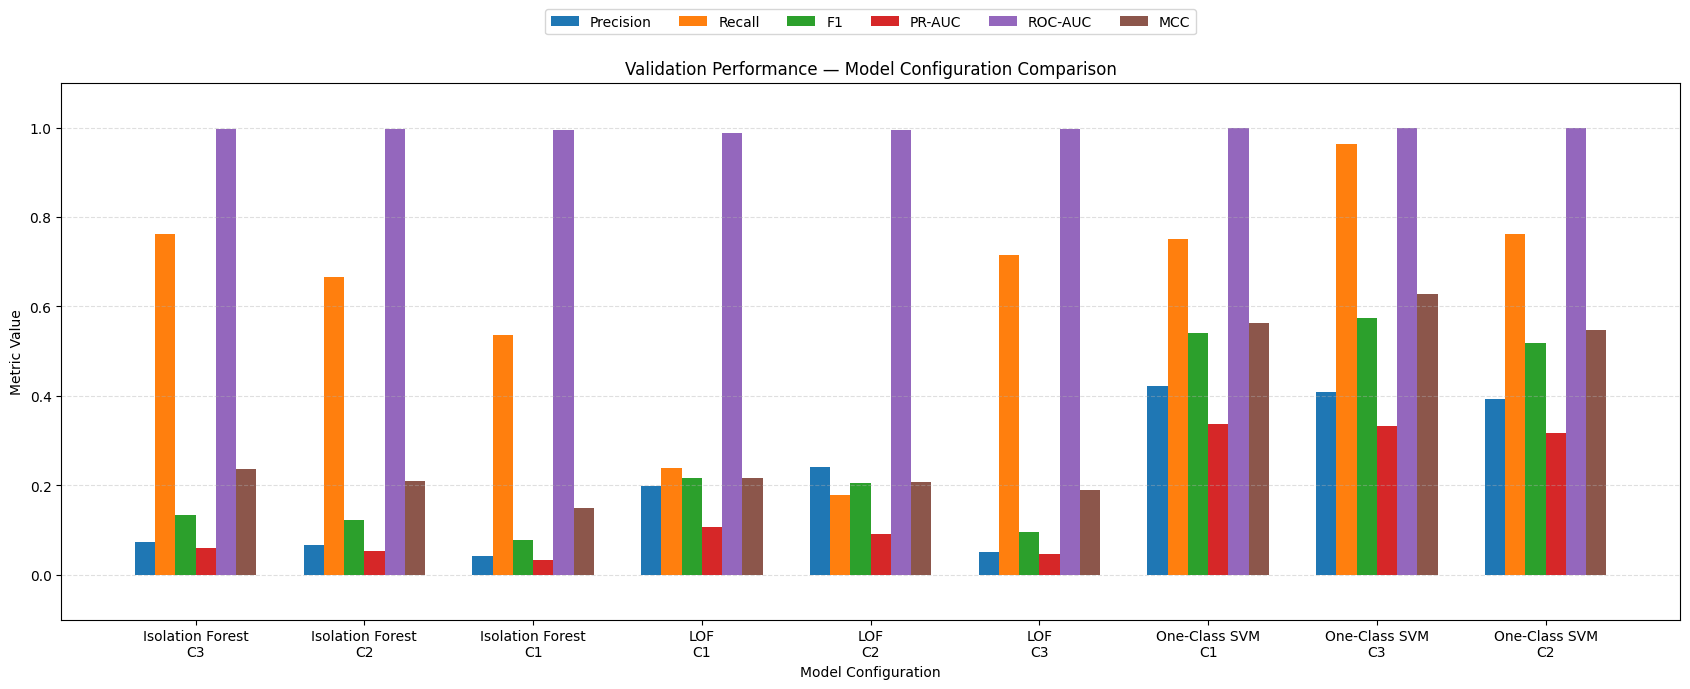

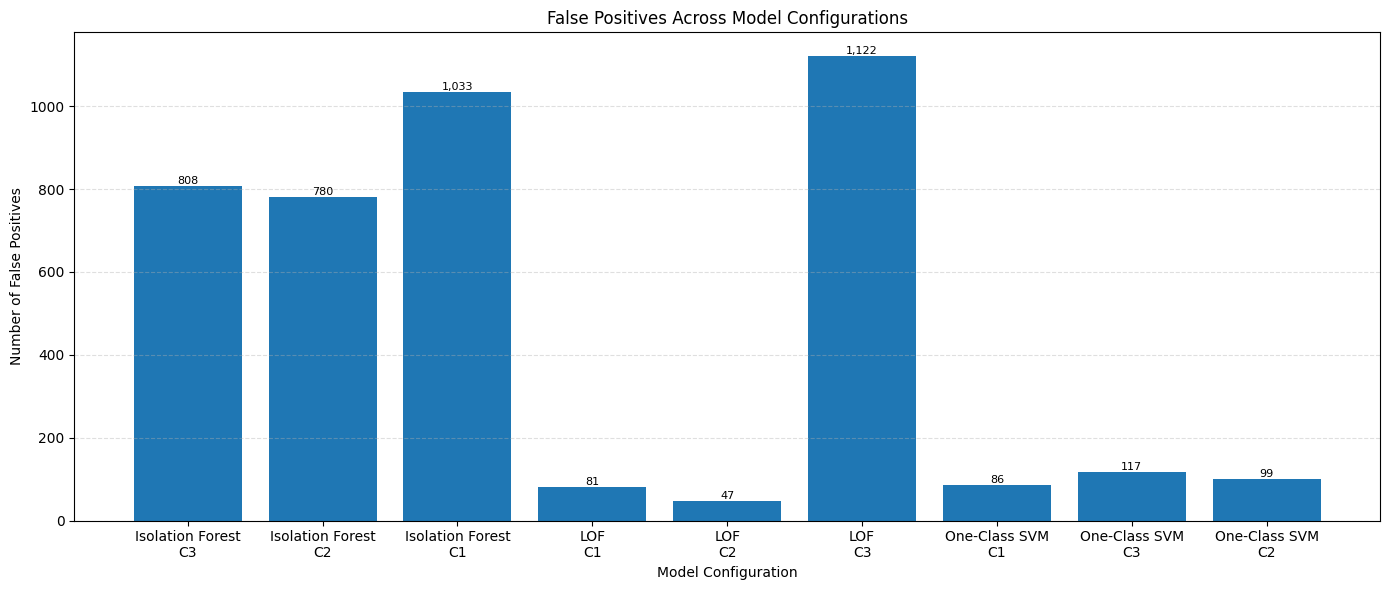

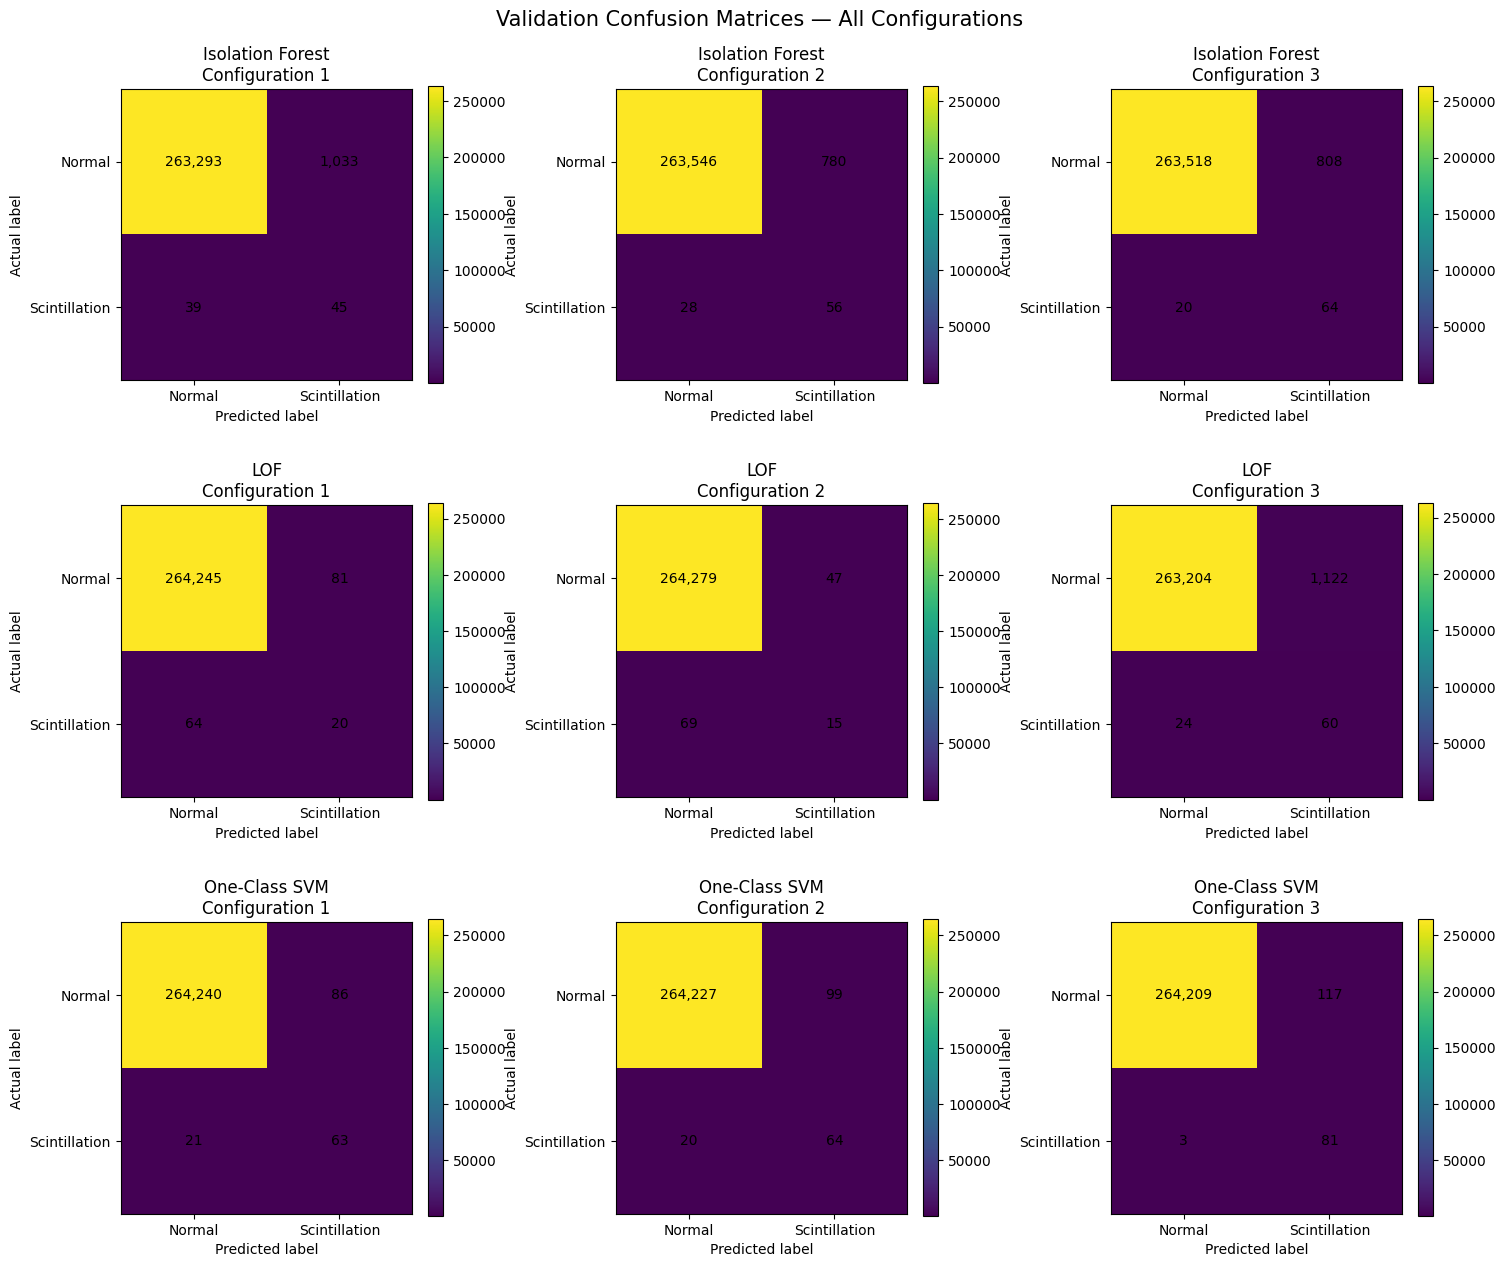

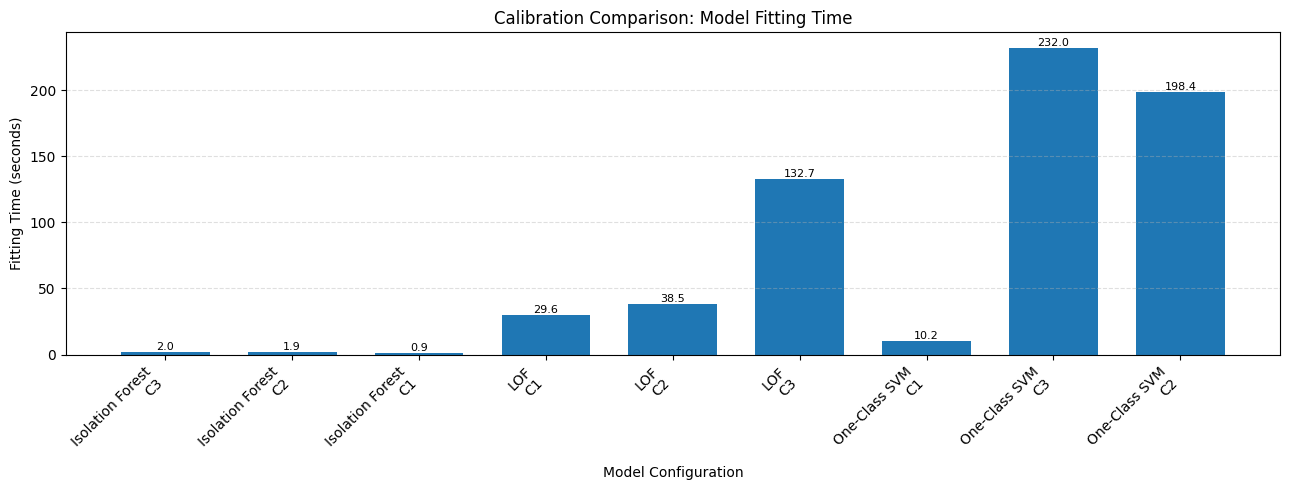

In [22]:
# ============================================================
# WORKFLOW 4 — CELL 5
# MODEL PARAMETER CALIBRATION
# ============================================================

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix
)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import json
import time


# ------------------------------------------------------------
# MODEL CALIBRATION CONFIGURATIONS
# ------------------------------------------------------------

calibration_configs = {

    "Isolation Forest": [

        {
            "n_estimators": 200,
            "max_samples": 256,
            "max_features": 1.0,
            "bootstrap": False,
            "contamination": "auto",
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        },

        {
            "n_estimators": 300,
            "max_samples": 512,
            "max_features": 1.0,
            "bootstrap": False,
            "contamination": "auto",
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        },

        {
            "n_estimators": 300,
            "max_samples": 1024,
            "max_features": 1.0,
            "bootstrap": False,
            "contamination": "auto",
            "random_state": RANDOM_STATE,
            "n_jobs": -1
        }
    ],

    "LOF": [

        {
            "n_neighbors": 10,
            "metric": "euclidean",
            "leaf_size": 30,
            "contamination": "auto",
            "novelty": True,
            "n_jobs": -1
        },

        {
            "n_neighbors": 20,
            "metric": "euclidean",
            "leaf_size": 30,
            "contamination": "auto",
            "novelty": True,
            "n_jobs": -1
        },

        {
            "n_neighbors": 35,
            "metric": "manhattan",
            "leaf_size": 30,
            "contamination": "auto",
            "novelty": True,
            "n_jobs": -1
        }
    ],

    "One-Class SVM": [

        {
            "kernel": "rbf",
            "nu": 0.005,
            "gamma": "scale",
            "tol": 0.001,
            "cache_size": 2000
        },

        {
            "kernel": "rbf",
            "nu": 0.01,
            "gamma": "scale",
            "tol": 0.001,
            "cache_size": 2000
        },

        {
            "kernel": "rbf",
            "nu": 0.02,
            "gamma": 0.01,
            "tol": 0.001,
            "cache_size": 2000
        }
    ]
}


# ------------------------------------------------------------
# BUILD MODEL
# ------------------------------------------------------------

def build_model(model_name, config):

    if model_name == "Isolation Forest":
        return IsolationForest(**config)

    elif model_name == "LOF":
        return LocalOutlierFactor(**config)

    elif model_name == "One-Class SVM":
        return OneClassSVM(**config)

    else:
        raise ValueError("Unknown model.")


# ------------------------------------------------------------
# GET MODEL INPUTS
# ------------------------------------------------------------

def get_model_inputs(model_name):

    if model_name == "Isolation Forest":

        return (
            X_train_if_sample,
            X_val_imputed,
            X_test_imputed
        )

    return (
        X_train_scaled_sample,
        X_val_scaled,
        X_test_scaled
    )


# ------------------------------------------------------------
# RUN CALIBRATION EXPERIMENTS
# ------------------------------------------------------------

calibration_rows = []
calibration_models = {}
calibration_confusion_matrices = {}

for model_name, configs in calibration_configs.items():

    print("\n" + "#" * 70)
    print("CALIBRATING:", model_name)
    print("#" * 70)

    X_fit, X_validation, X_testing = get_model_inputs(model_name)

    for config_number, config in enumerate(configs, start=1):

        print(f"\n{model_name} — Configuration {config_number}")
        print("Parameters:", json.dumps(config, indent=4, sort_keys=True))

        model = build_model(model_name, config)

        # ----------------------------------------------------
        # MODEL FITTING
        # ----------------------------------------------------

        start_time = time.time()

        model.fit(X_fit)

        fit_seconds = time.time() - start_time

        # ----------------------------------------------------
        # TRAINING SCORES
        # ----------------------------------------------------

        # Scores for normal-training diagnostics
        train_scores = score_in_batches(
            model,
            X_fit,
            model_name,
            PREDICTION_BATCH_SIZE
        )

        # ----------------------------------------------------
        # VALIDATION SCORES
        # ----------------------------------------------------

        val_scores = score_in_batches(
            model,
            X_validation,
            model_name,
            PREDICTION_BATCH_SIZE
        )

        # ----------------------------------------------------
        # VALIDATION METRICS
        # ----------------------------------------------------

        # Threshold-independent metrics
        validation_ap = average_precision_score(
            y_val,
            val_scores
        )

        validation_roc = roc_auc_score(
            y_val,
            val_scores
        )

        # Select threshold using validation data only
        validation_threshold = find_best_f1_threshold(
            y_val,
            val_scores
        )

        # Convert scores into binary predictions
        val_predictions = (
            val_scores >= validation_threshold
        ).astype(int)

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_val,
            val_predictions,
            labels=[0, 1]
        ).ravel()

        # Threshold-dependent metrics
        validation_precision = precision_score(
            y_val,
            val_predictions,
            zero_division=0
        )

        validation_recall = recall_score(
            y_val,
            val_predictions,
            zero_division=0
        )

        validation_f1 = f1_score(
            y_val,
            val_predictions,
            zero_division=0
        )

        validation_mcc = matthews_corrcoef(
            y_val,
            val_predictions
        )

        # Store confusion matrix for this configuration
        calibration_confusion_matrices[
            (model_name, config_number)
        ] = np.array([
            [tn, fp],
            [fn, tp]
        ])

        # ----------------------------------------------------
        # TRAINING SCORE SUMMARY
        # ----------------------------------------------------

        train_score_summary = {

            "Training_Score_Mean": np.mean(train_scores),

            "Training_Score_Median": np.median(train_scores),

            "Training_Score_Std": np.std(train_scores),

            "Training_Score_Min": np.min(train_scores),

            "Training_Score_Max": np.max(train_scores)
        }

        # ----------------------------------------------------
        # STORE CALIBRATION RESULTS
        # ----------------------------------------------------

        calibration_rows.append({

            "Model": model_name,

            "Configuration": config_number,

            "Parameters": json.dumps(config, sort_keys=True),

            "Training_Sample_Size": len(X_fit),

            "Fit_Seconds": fit_seconds,

            **train_score_summary,

            "Validation_Threshold": validation_threshold,

            "Validation_TP": tp,
            "Validation_FP": fp,
            "Validation_FN": fn,
            "Validation_TN": tn,

            "Validation_Precision": validation_precision,
            "Validation_Recall": validation_recall,
            "Validation_F1": validation_f1,

            "Validation_PR_AUC": validation_ap,
            "Validation_ROC_AUC": validation_roc,
            "Validation_MCC": validation_mcc
        })

        # ----------------------------------------------------
        # STORE FITTED MODELS AND SCORES
        # ----------------------------------------------------

        calibration_models[
            (model_name, config_number)
        ] = {

            "model": model,

            "config": config.copy(),

            "training_scores": train_scores,

            "validation_scores": val_scores,

            "validation_threshold": validation_threshold,

            "fit_seconds": fit_seconds
        }

        # ----------------------------------------------------
        # PRINT CONFIGURATION RESULTS
        # ----------------------------------------------------

        print("Fit time:", round(fit_seconds, 2), "seconds")
        print("Validation threshold:", round(validation_threshold, 6))

        print("\nVALIDATION PERFORMANCE")
        print("Precision:", round(validation_precision, 6))
        print("Recall:", round(validation_recall, 6))
        print("F1:", round(validation_f1, 6))
        print("Average Precision (PR-AUC):", round(validation_ap, 6))
        print("ROC-AUC:", round(validation_roc, 6))
        print("MCC:", round(validation_mcc, 6))

        print("\nVALIDATION CONFUSION MATRIX")
        print(f"True Positives (TP):  {tp:,}")
        print(f"False Positives (FP): {fp:,}")
        print(f"False Negatives (FN): {fn:,}")
        print(f"True Negatives (TN):  {tn:,}")


# ------------------------------------------------------------
# CALIBRATION RESULTS TABLE
# ------------------------------------------------------------

calibration_results = pd.DataFrame(calibration_rows)

# Sort configurations by model and Validation PR-AUC
calibration_results = calibration_results.sort_values(
    ["Model", "Validation_PR_AUC"],
    ascending=[True, False]
).reset_index(drop=True)

# Display readable parameter dictionaries in the table
calibration_table = calibration_results.copy()

calibration_table["Parameters"] = calibration_table["Parameters"].apply(
    lambda x: json.dumps(json.loads(x), sort_keys=True)
)

print("\n" + "=" * 100)
print("MODEL CALIBRATION RESULTS")
print("=" * 100)

display(
    calibration_table.round({

        "Fit_Seconds": 2,

        "Training_Score_Mean": 5,

        "Training_Score_Median": 5,

        "Training_Score_Std": 5,

        "Training_Score_Min": 5,

        "Training_Score_Max": 5,

        "Validation_Threshold": 6,

        "Validation_Precision": 6,
        "Validation_Recall": 6,
        "Validation_F1": 6,
        "Validation_PR_AUC": 6,
        "Validation_ROC_AUC": 6,
        "Validation_MCC": 6
    })
)

# Save complete results, including full parameter dictionaries
calibration_results.to_csv(
    f"{OUTPUT_FOLDER}/model_calibration_results.csv",
    index=False
)

print("\nCalibration results saved successfully.")


# ------------------------------------------------------------
# SELECT THE BEST CONFIGURATION FOR EACH MODEL
# ------------------------------------------------------------

best_configurations = {}

for model_name in calibration_configs:

    model_rows = calibration_results[
        calibration_results["Model"] == model_name
    ]

    # Best configuration selected using Validation PR-AUC
    best_row = model_rows.iloc[0]

    best_number = int(best_row["Configuration"])

    best_configurations[model_name] = calibration_models[
        (model_name, best_number)
    ]

    print("\nBest configuration:", model_name)

    print("Configuration number:", best_number)

    print(
        "Validation PR-AUC:",
        round(best_row["Validation_PR_AUC"], 6)
    )

    print(
        "Validation ROC-AUC:",
        round(best_row["Validation_ROC_AUC"], 6)
    )

    print(
        "Validation Recall:",
        round(best_row["Validation_Recall"], 6)
    )

    print(
        "Validation F1:",
        round(best_row["Validation_F1"], 6)
    )

    print(
        "Validation MCC:",
        round(best_row["Validation_MCC"], 6)
    )

    print("Fit time:", round(best_row["Fit_Seconds"], 2), "seconds")

    print("Parameters:")

    print(
        json.dumps(
            json.loads(best_row["Parameters"]),
            indent=4,
            sort_keys=True
        )
    )


# ------------------------------------------------------------
# CALIBRATION COMPARISON GRAPH
# ------------------------------------------------------------

# ------------------------------------------------------------
# PLOT 1 — VALIDATION PERFORMANCE COMPARISON
# ------------------------------------------------------------

plot_data = calibration_results.copy()

plot_data["Config_Label"] = (
    plot_data["Model"]
    + "\nC"
    + plot_data["Configuration"].astype(str)
)

metrics = {
    "Precision": "Validation_Precision",
    "Recall": "Validation_Recall",
    "F1": "Validation_F1",
    "PR-AUC": "Validation_PR_AUC",
    "ROC-AUC": "Validation_ROC_AUC",
    "MCC": "Validation_MCC"
}

x = np.arange(len(plot_data))
width = 0.12

fig, ax = plt.subplots(figsize=(17, 7))

for i, (label, column) in enumerate(metrics.items()):

    offset = (i - (len(metrics) - 1) / 2) * width

    ax.bar(
        x + offset,
        plot_data[column],
        width,
        label=label
    )

ax.set_title(
    "Validation Performance — Model Configuration Comparison"
)

ax.set_xlabel("Model Configuration")
ax.set_ylabel("Metric Value")

ax.set_xticks(x)
ax.set_xticklabels(plot_data["Config_Label"])

ax.set_ylim(-0.1, 1.1)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=6
)

ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PLOT 2 — VALIDATION FALSE POSITIVES
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 6))

bars = ax.bar(
    plot_data["Config_Label"],
    plot_data["Validation_FP"]
)

ax.set_title(
    "False Positives Across Model Configurations"
)

ax.set_xlabel("Model Configuration")
ax.set_ylabel("Number of False Positives")

ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar in bars:

    value = int(bar.get_height())

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# PLOT 3 — VALIDATION CONFUSION MATRICES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    3,
    3,
    figsize=(15, 13)
)

for ax, (key, cm) in zip(
    axes.flat,
    calibration_confusion_matrices.items()
):

    model_name, config_number = key

    image = ax.imshow(cm)

    ax.set_title(
        f"{model_name}\nConfiguration {config_number}"
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Normal", "Scintillation"])
    ax.set_yticklabels(["Normal", "Scintillation"])

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

    for row in range(2):
        for col in range(2):

            ax.text(
                col,
                row,
                f"{cm[row, col]:,}",
                ha="center",
                va="center"
            )

    fig.colorbar(image, ax=ax, fraction=0.046)

plt.suptitle(
    "Validation Confusion Matrices — All Configurations",
    fontsize=15
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# CALIBRATION COMPARISON GRAPH
# MODEL FITTING TIME
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

bars = plt.bar(
    x,
    plot_data["Fit_Seconds"],
    width=0.7
)

plt.xticks(
    x,
    plot_data["Config_Label"],
    rotation=45,
    ha="right"
)

plt.ylabel("Fitting Time (seconds)")

plt.xlabel("Model Configuration")

plt.title("Calibration Comparison: Model Fitting Time")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

for bar, value in zip(bars, plot_data["Fit_Seconds"]):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

plt.show()


**Threshold calibration: keeps those fitted models unchanged and tests different decision thresholds to determine when an anomaly score should be classified as scintillation.**


######################################################################
THRESHOLD CALIBRATION: Isolation Forest
######################################################################

Threshold method: Default
Threshold: 0.5

VALIDATION PERFORMANCE
Precision: 0.004501
Recall: 1.000000
F1: 0.008961
Average Precision (PR-AUC): 0.059581
False Positives: 18,580
True Positives: 84
False Negatives: 0
True Negatives: 245,746

TEST PERFORMANCE
Precision: 0.005293
Recall: 1.000000
F1: 0.010531
Average Precision (PR-AUC): 0.105377
False Positives: 22,363
True Positives: 119
False Negatives: 0
True Negatives: 250,260

Threshold method: Validation_F1
Threshold: 0.576022

VALIDATION PERFORMANCE
Precision: 0.073394
Recall: 0.761905
F1: 0.133891
Average Precision (PR-AUC): 0.059581
False Positives: 808
True Positives: 64
False Negatives: 20
True Negatives: 263,518

TEST PERFORMANCE
Precision: 0.069036
Recall: 0.848739
F1: 0.127686
Average Precision (PR-AUC): 0.105377
False Positives: 1,362
True Posit

,Model,Threshold_Method,Threshold,Validation_TP,Validation_FP,Validation_FN,Validation_TN,Validation_Detected_Anomalies,Validation_Precision,Validation_Recall,...,Test_FN,Test_TN,Test_Detected_Anomalies,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_ROC_AUC,Test_FPR,Test_Specificity
0,Isolation Forest,Default,0.500000,84,18580,0,245746,18664,0.004501,1.000000,...,0,250260,22482,0.005293,1.000000,0.010531,0.105377,0.996815,0.082029,0.917971
1,Isolation Forest,Validation_F1,0.576022,64,808,20,263518,872,0.073394,0.761905,...,18,271261,1463,0.069036,0.848739,0.127686,0.105377,0.996815,0.004996,0.995004
2,Isolation Forest,Target_FPR_0.1_percent,0.599787,10,265,74,264061,275,0.036364,0.119048,...,78,272138,526,0.077947,0.344538,0.127132,0.105377,0.996815,0.001779,0.998221
3,Isolation Forest,Target_FPR_0.5_percent,0.565551,74,1322,10,263004,1396,0.053009,0.880952,...,5,270577,2160,0.052778,0.957983,0.100044,0.105377,0.996815,0.007505,0.992495
4,Isolation Forest,Target_FPR_1_percent,0.549698,83,2644,1,261682,2727,0.030436,0.988095,...,2,268930,3810,0.030709,0.983193,0.059557,0.105377,0.996815,0.013546,0.986454
5,LOF,Default,1.500000,51,1140,33,263186,1191,0.042821,0.607143,...,47,271060,1635,0.044037,0.605042,0.082098,0.264802,0.982510,0.005733,0.994267
6,LOF,Validation_F1,2.053868,20,81,64,264245,101,0.198020,0.238095,...,89,272591,62,0.483871,0.252101,0.331492,0.264802,0.982510,0.000117,0.999883
7,LOF,Target_FPR_0.1_percent,1.786824,28,265,56,264061,293,0.095563,0.333333,...,73,272416,253,0.181818,0.386555,0.247312,0.264802,0.982510,0.000759,0.999241
8,LOF,Target_FPR_0.5_percent,1.479896,51,1322,33,263004,1373,0.037145,0.607143,...,45,270847,1850,0.040000,0.621849,0.075165,0.264802,0.982510,0.006514,0.993486
9,LOF,Target_FPR_1_percent,1.388799,62,2644,22,261682,2706,0.022912,0.738095,...,34,269307,3401,0.024993,0.714286,0.048295,0.264802,0.982510,0.012163,0.987837


,Model,Threshold_Method,Threshold,Validation_Precision,Validation_Recall,Validation_F1,Validation_Average_Precision,Validation_FP,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_FP
0,Isolation Forest,Default,0.500000,0.004501,1.000000,0.008961,0.059581,18580,0.005293,1.000000,0.010531,0.105377,22363
1,Isolation Forest,Validation_F1,0.576022,0.073394,0.761905,0.133891,0.059581,808,0.069036,0.848739,0.127686,0.105377,1362
2,Isolation Forest,Target_FPR_0.1_percent,0.599787,0.036364,0.119048,0.055710,0.059581,265,0.077947,0.344538,0.127132,0.105377,485
3,Isolation Forest,Target_FPR_0.5_percent,0.565551,0.053009,0.880952,0.100000,0.059581,1322,0.052778,0.957983,0.100044,0.105377,2046
4,Isolation Forest,Target_FPR_1_percent,0.549698,0.030436,0.988095,0.059054,0.059581,2644,0.030709,0.983193,0.059557,0.105377,3693
5,LOF,Default,1.500000,0.042821,0.607143,0.080000,0.107885,1140,0.044037,0.605042,0.082098,0.264802,1563
6,LOF,Validation_F1,2.053868,0.198020,0.238095,0.216216,0.107885,81,0.483871,0.252101,0.331492,0.264802,32
7,LOF,Target_FPR_0.1_percent,1.786824,0.095563,0.333333,0.148541,0.107885,265,0.181818,0.386555,0.247312,0.264802,207
8,LOF,Target_FPR_0.5_percent,1.479896,0.037145,0.607143,0.070007,0.107885,1322,0.040000,0.621849,0.075165,0.264802,1776
9,LOF,Target_FPR_1_percent,1.388799,0.022912,0.738095,0.044444,0.107885,2644,0.024993,0.714286,0.048295,0.264802,3316



Threshold comparison saved successfully.

SELECTED MODELS AND AVAILABLE THRESHOLDS

Model: Isolation Forest
Configuration parameters:
{
    "bootstrap": false,
    "contamination": "auto",
    "max_features": 1.0,
    "max_samples": 1024,
    "n_estimators": 300,
    "n_jobs": -1,
    "random_state": 42
}

Threshold options:
Default: 0.500000
Validation_F1: 0.576022
Target_FPR_0.1_percent: 0.599787
Target_FPR_0.5_percent: 0.565551
Target_FPR_1_percent: 0.549698

Model: LOF
Configuration parameters:
{
    "contamination": "auto",
    "leaf_size": 30,
    "metric": "euclidean",
    "n_jobs": -1,
    "n_neighbors": 10,
    "novelty": true
}

Threshold options:
Default: 1.500000
Validation_F1: 2.053868
Target_FPR_0.1_percent: 1.786824
Target_FPR_0.5_percent: 1.479896
Target_FPR_1_percent: 1.388799

Model: One-Class SVM
Configuration parameters:
{
    "cache_size": 2000,
    "gamma": "scale",
    "kernel": "rbf",
    "nu": 0.005,
    "tol": 0.001
}

Threshold options:
Default: 0.000000
Val

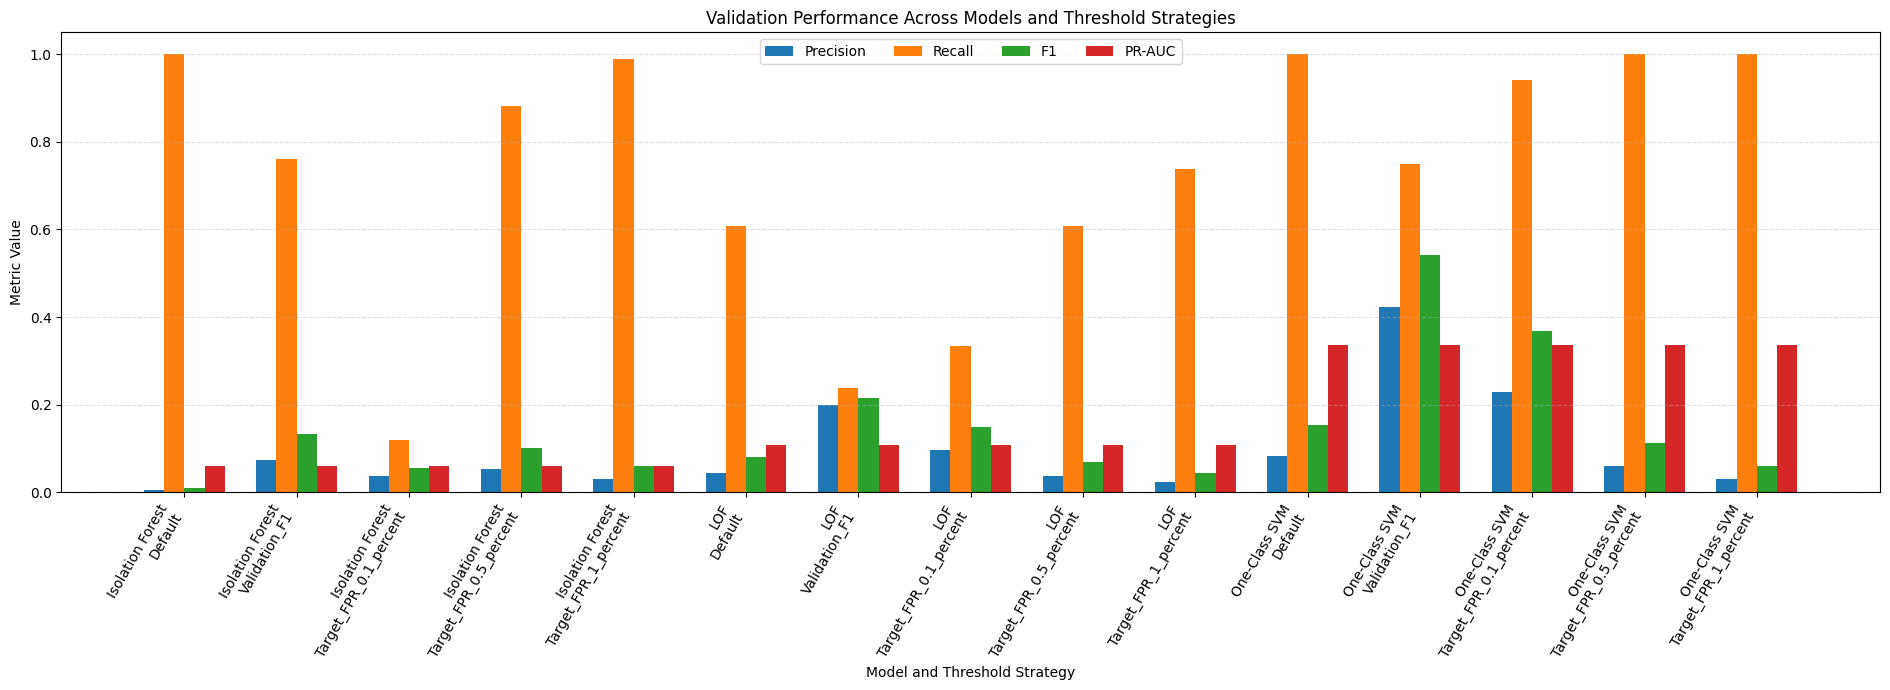

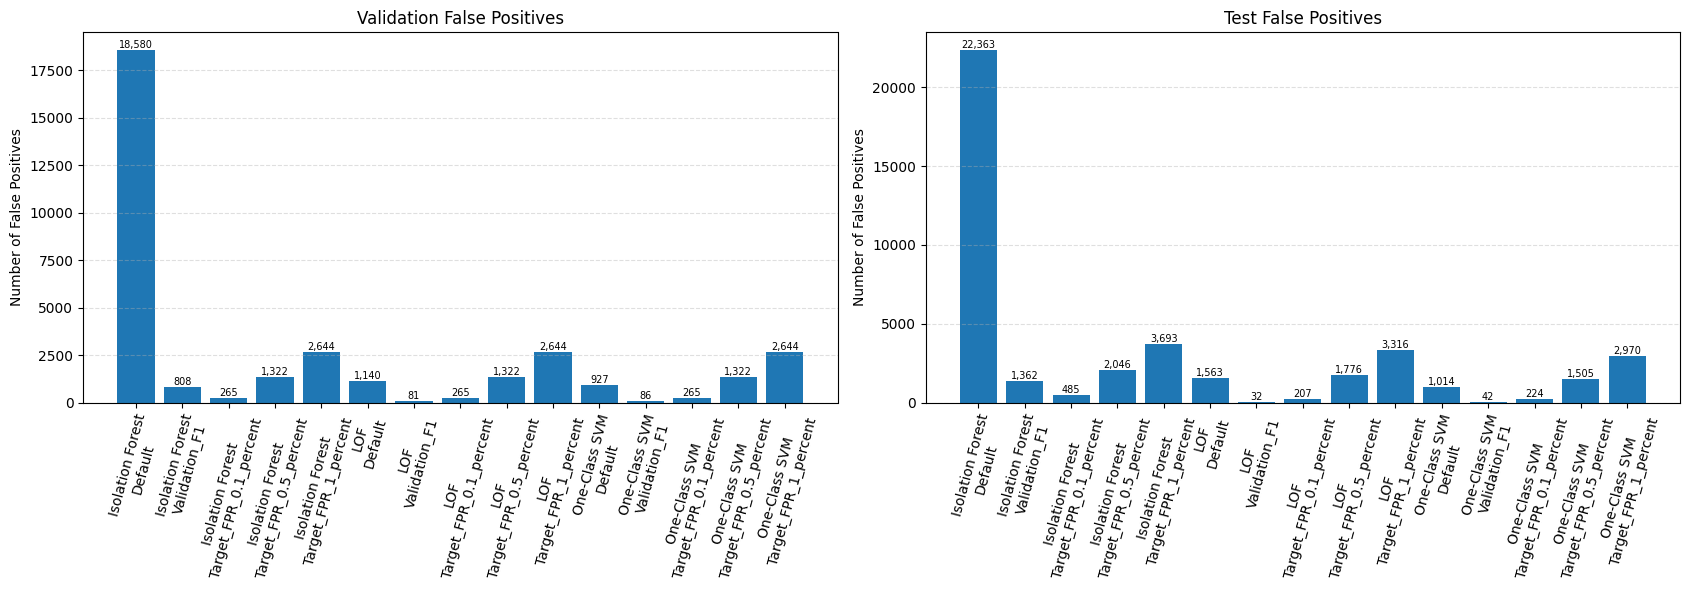

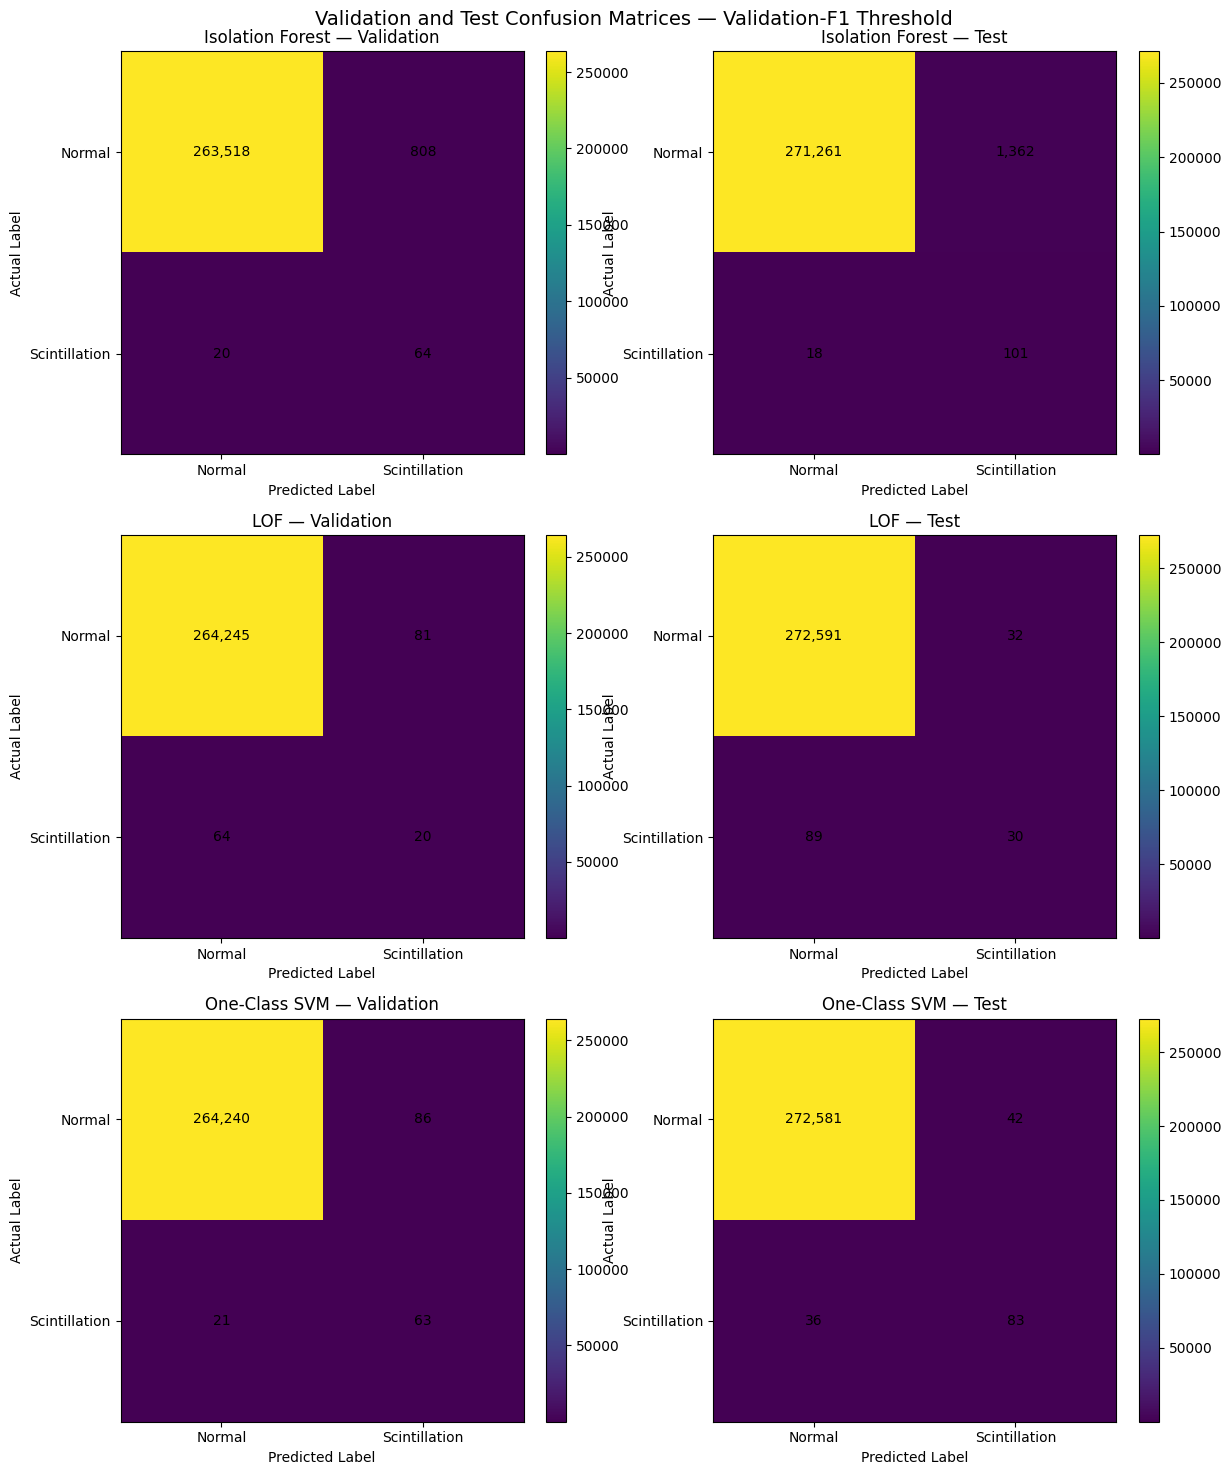

In [23]:
# ============================================================
# WORKFLOW 4 — CELL 6
# THRESHOLD CALIBRATION
# Compare different anomaly detection thresholds
# ============================================================


# ------------------------------------------------------------
# FUNCTION: THRESHOLD FOR TARGET FALSE POSITIVE RATE
# ------------------------------------------------------------

def threshold_for_target_fpr(
    y_true,
    anomaly_scores,
    target_fpr
):
    """
    Estimate an anomaly threshold using validation-negative scores.

    target_fpr=0.001 means a target false-positive rate of 0.1%.
    target_fpr=0.005 means a target false-positive rate of 0.5%.
    target_fpr=0.01 means a target false-positive rate of 1%.

    Higher scores indicate more anomalous observations.
    """

    y_true = np.asarray(y_true)
    anomaly_scores = np.asarray(anomaly_scores)

    negative_scores = anomaly_scores[y_true == 0]

    if len(negative_scores) == 0:
        raise ValueError(
            "No negative validation observations."
        )

    if not 0 < target_fpr < 1:
        raise ValueError(
            "target_fpr must be between 0 and 1."
        )

    return float(
        np.quantile(
            negative_scores,
            1 - target_fpr
        )
    )


# ------------------------------------------------------------
# USE THE BEST CONFIGURATIONS SELECTED IN CELL 5
# ------------------------------------------------------------

threshold_experiment_rows = []

best_models = {}
best_model_scores = {}
best_thresholds = {}

threshold_confusion_matrices = {}

for model_name, selected in best_configurations.items():

    print("\n" + "#" * 70)
    print("THRESHOLD CALIBRATION:", model_name)
    print("#" * 70)

    # --------------------------------------------------------
    # RETRIEVE ALREADY-FITTED MODEL
    # --------------------------------------------------------

    model = selected["model"]

    config = selected["config"]

    # Get the correct test input
    _, _, X_testing = get_model_inputs(model_name)

    # Reuse validation scores from Cell 5
    val_scores = selected["validation_scores"]

    # Score the independent test observations
    test_scores = score_in_batches(
        model,
        X_testing,
        model_name,
        PREDICTION_BATCH_SIZE
    )

    # --------------------------------------------------------
    # GENERATE THRESHOLD OPTIONS
    # --------------------------------------------------------

    default_threshold = get_default_anomaly_threshold(
        model,
        model_name
    )

    # F1-optimal threshold selected using validation data
    f1_threshold = find_best_f1_threshold(
        y_val,
        val_scores
    )

    # Thresholds based on target validation FPR
    fpr_thresholds = {

        "Target_FPR_0.1_percent": threshold_for_target_fpr(
            y_val,
            val_scores,
            0.001
        ),

        "Target_FPR_0.5_percent": threshold_for_target_fpr(
            y_val,
            val_scores,
            0.005
        ),

        "Target_FPR_1_percent": threshold_for_target_fpr(
            y_val,
            val_scores,
            0.01
        )
    }

    # All five threshold strategies
    all_thresholds = {

        "Default": default_threshold,

        "Validation_F1": f1_threshold,

        **fpr_thresholds
    }

    # --------------------------------------------------------
    # STORE MODEL AND SCORES
    # --------------------------------------------------------

    best_models[model_name] = model

    best_thresholds[model_name] = all_thresholds

    best_model_scores[model_name] = {

        "config": config,

        "validation_scores": val_scores,

        "test_scores": test_scores,

        "thresholds": all_thresholds
    }

    # --------------------------------------------------------
    # EVALUATE EACH THRESHOLD
    # --------------------------------------------------------

    for method, threshold in all_thresholds.items():

        # Validation predictions and metrics
        val_metrics = calculate_metrics(
            y_val,
            val_scores,
            threshold
        )

        # Test predictions and metrics
        test_metrics = calculate_metrics(
            y_test,
            test_scores,
            threshold
        )

        # Store threshold comparison results
        threshold_experiment_rows.append({

            "Model": model_name,

            "Threshold_Method": method,

            "Threshold": threshold,

            **{
                f"Validation_{k}": v
                for k, v in val_metrics.items()
                if k != "Threshold"
            },

            **{
                f"Test_{k}": v
                for k, v in test_metrics.items()
                if k != "Threshold"
            }
        })

        # ----------------------------------------------------
        # PRINT THRESHOLD RESULTS
        # ----------------------------------------------------

        print("\nThreshold method:", method)
        print("Threshold:", round(threshold, 6))

        print("\nVALIDATION PERFORMANCE")
        print(f"Precision: {val_metrics['Precision']:.6f}")
        print(f"Recall: {val_metrics['Recall']:.6f}")
        print(f"F1: {val_metrics['F1']:.6f}")
        print(f"Average Precision (PR-AUC): {val_metrics['Average_Precision']:.6f}")
        print(f"False Positives: {val_metrics['FP']:,}")
        print(f"True Positives: {val_metrics['TP']:,}")
        print(f"False Negatives: {val_metrics['FN']:,}")
        print(f"True Negatives: {val_metrics['TN']:,}")

        print("\nTEST PERFORMANCE")
        print(f"Precision: {test_metrics['Precision']:.6f}")
        print(f"Recall: {test_metrics['Recall']:.6f}")
        print(f"F1: {test_metrics['F1']:.6f}")
        print(f"Average Precision (PR-AUC): {test_metrics['Average_Precision']:.6f}")
        print(f"False Positives: {test_metrics['FP']:,}")
        print(f"True Positives: {test_metrics['TP']:,}")
        print(f"False Negatives: {test_metrics['FN']:,}")
        print(f"True Negatives: {test_metrics['TN']:,}")

        # Store confusion matrices for later visualisation
        threshold_confusion_matrices[
            (model_name, method)
        ] = {
            "Validation": np.array([
                [val_metrics["TN"], val_metrics["FP"]],
                [val_metrics["FN"], val_metrics["TP"]]
            ]),
            "Test": np.array([
                [test_metrics["TN"], test_metrics["FP"]],
                [test_metrics["FN"], test_metrics["TP"]]
            ])
        }

# ------------------------------------------------------------
# THRESHOLD COMPARISON RESULTS TABLE
# ------------------------------------------------------------

threshold_results = pd.DataFrame(
    threshold_experiment_rows
)

print("\n" + "=" * 100)
print("THRESHOLD COMPARISON — VALIDATION AND TEST SETS")
print("=" * 100)

display(
    threshold_results.round(6)
)
# ------------------------------------------------------------
# FOCUSED THRESHOLD PERFORMANCE REPORT
# ------------------------------------------------------------

report_columns = [
    "Model",
    "Threshold_Method",
    "Threshold",
    "Validation_Precision",
    "Validation_Recall",
    "Validation_F1",
    "Validation_Average_Precision",
    "Validation_FP",
    "Test_Precision",
    "Test_Recall",
    "Test_F1",
    "Test_Average_Precision",
    "Test_FP"
]

display(
    threshold_results[report_columns].round(6)
)

# Save complete threshold comparison results
threshold_results.to_csv(
    f"{OUTPUT_FOLDER}/threshold_comparison.csv",
    index=False
)

print("\nThreshold comparison saved successfully.")


# ------------------------------------------------------------
# DISPLAY BEST CONFIGURATION AND THRESHOLD OPTIONS
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("SELECTED MODELS AND AVAILABLE THRESHOLDS")
print("=" * 100)

for model_name, thresholds in best_thresholds.items():

    print("\nModel:", model_name)

    print("Configuration parameters:")

    print(
        json.dumps(
            best_model_scores[model_name]["config"],
            indent=4,
            sort_keys=True
        )
    )

    print("\nThreshold options:")

    for method, threshold in thresholds.items():

        print(
            f"{method}: {threshold:.6f}"
        )


# ------------------------------------------------------------
# VISUALISATION 1 — PERFORMANCE METRICS
# ------------------------------------------------------------

plot_metrics = {
    "Precision": "Validation_Precision",
    "Recall": "Validation_Recall",
    "F1": "Validation_F1",
    "PR-AUC": "Validation_Average_Precision"
}

plot_data = threshold_results.copy()

plot_data["Label"] = (
    plot_data["Model"]
    + "\n"
    + plot_data["Threshold_Method"]
)

x = np.arange(len(plot_data))
width = 0.18

fig, ax = plt.subplots(figsize=(19, 7))

for i, (metric_name, column) in enumerate(plot_metrics.items()):

    offset = (i - 1.5) * width

    ax.bar(
        x + offset,
        plot_data[column],
        width,
        label=metric_name
    )

ax.set_title(
    "Validation Performance Across Models and Threshold Strategies"
)

ax.set_xlabel("Model and Threshold Strategy")
ax.set_ylabel("Metric Value")

ax.set_xticks(x)
ax.set_xticklabels(
    plot_data["Label"],
    rotation=60,
    ha="right"
)

ax.set_ylim(0, 1.05)

ax.legend(ncol=4)
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# VISUALISATION 2 — FALSE POSITIVE COMPARISON
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6)
)

for ax, column, title in [
    (axes[0], "Validation_FP", "Validation False Positives"),
    (axes[1], "Test_FP", "Test False Positives")
]:

    labels = (
        threshold_results["Model"]
        + "\n"
        + threshold_results["Threshold_Method"]
    )

    bars = ax.bar(
        labels,
        threshold_results[column]
    )

    ax.set_title(title)
    ax.set_ylabel("Number of False Positives")
    ax.tick_params(axis="x", rotation=75)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    for bar in bars:

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{int(bar.get_height()):,}",
            ha="center",
            va="bottom",
            fontsize=7
        )

plt.tight_layout()
plt.show()

 # ------------------------------------------------------------
# VISUALISATION 3 — CONFUSION MATRICES
# VALIDATION-F1 THRESHOLD
# ------------------------------------------------------------

selected_method = "Validation_F1"

fig, axes = plt.subplots(
    3, 2,
    figsize=(12, 15)
)

for row, model_name in enumerate(best_thresholds):

    for col, dataset_name in enumerate(
        ["Validation", "Test"]
    ):

        cm = threshold_confusion_matrices[
            (model_name, selected_method)
        ][dataset_name]

        ax = axes[row, col]

        image = ax.imshow(cm)

        ax.set_title(
            f"{model_name} — {dataset_name}"
        )

        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])

        ax.set_xticklabels(["Normal", "Scintillation"])
        ax.set_yticklabels(["Normal", "Scintillation"])

        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")

        for i in range(2):
            for j in range(2):

                ax.text(
                    j, i,
                    f"{cm[i, j]:,}",
                    ha="center",
                    va="center"
                )

        fig.colorbar(image, ax=ax, fraction=0.046)

plt.suptitle(
    "Validation and Test Confusion Matrices — Validation-F1 Threshold",
    fontsize=14
)

plt.tight_layout()
plt.show()

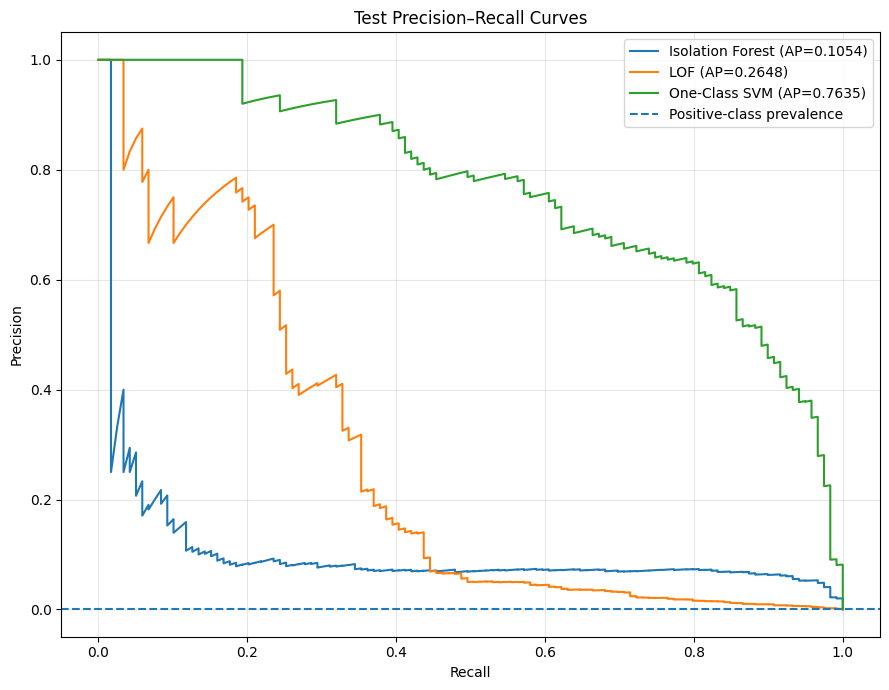

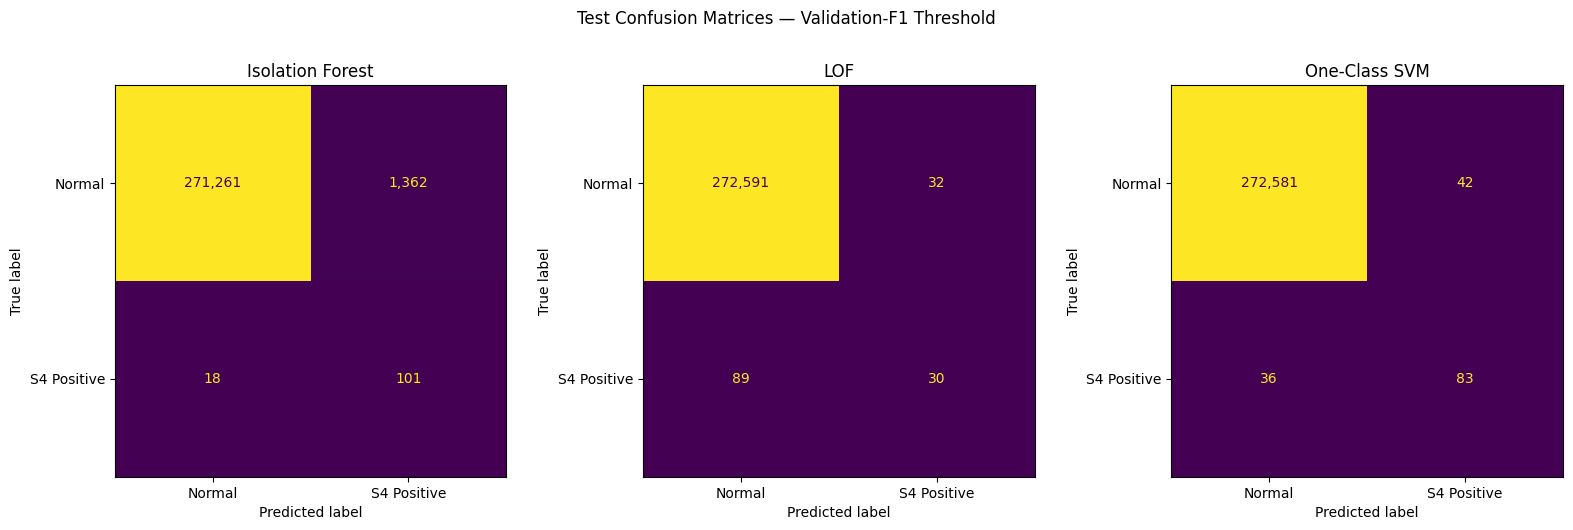

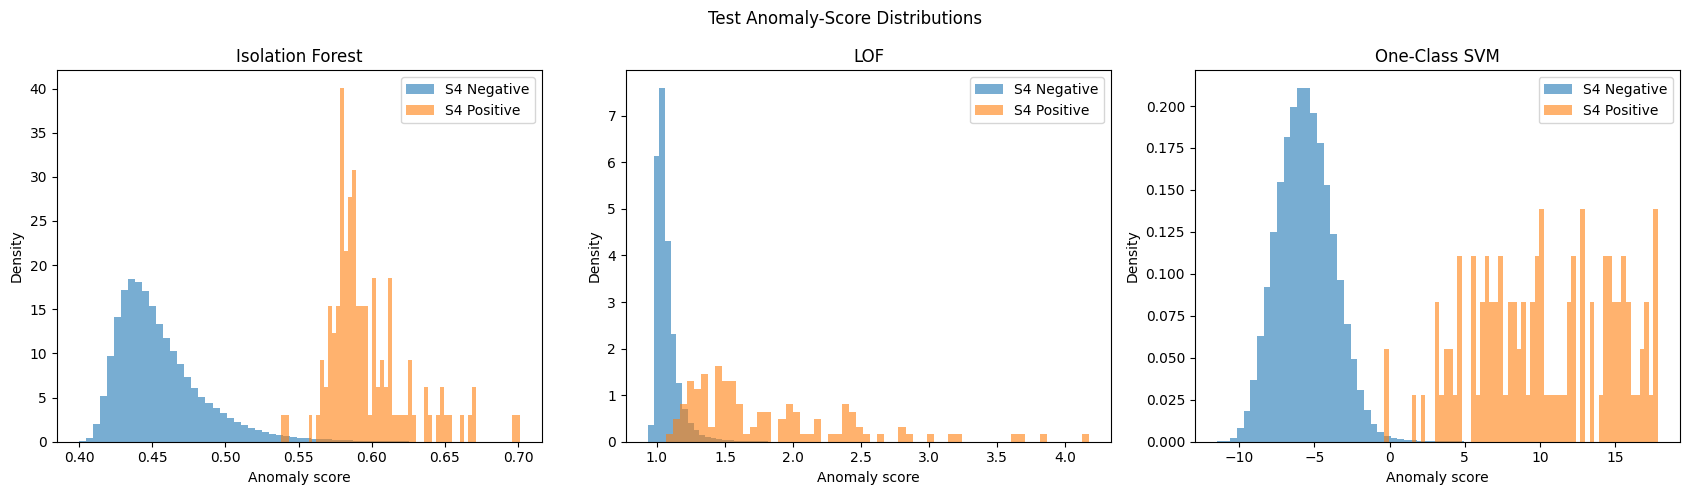

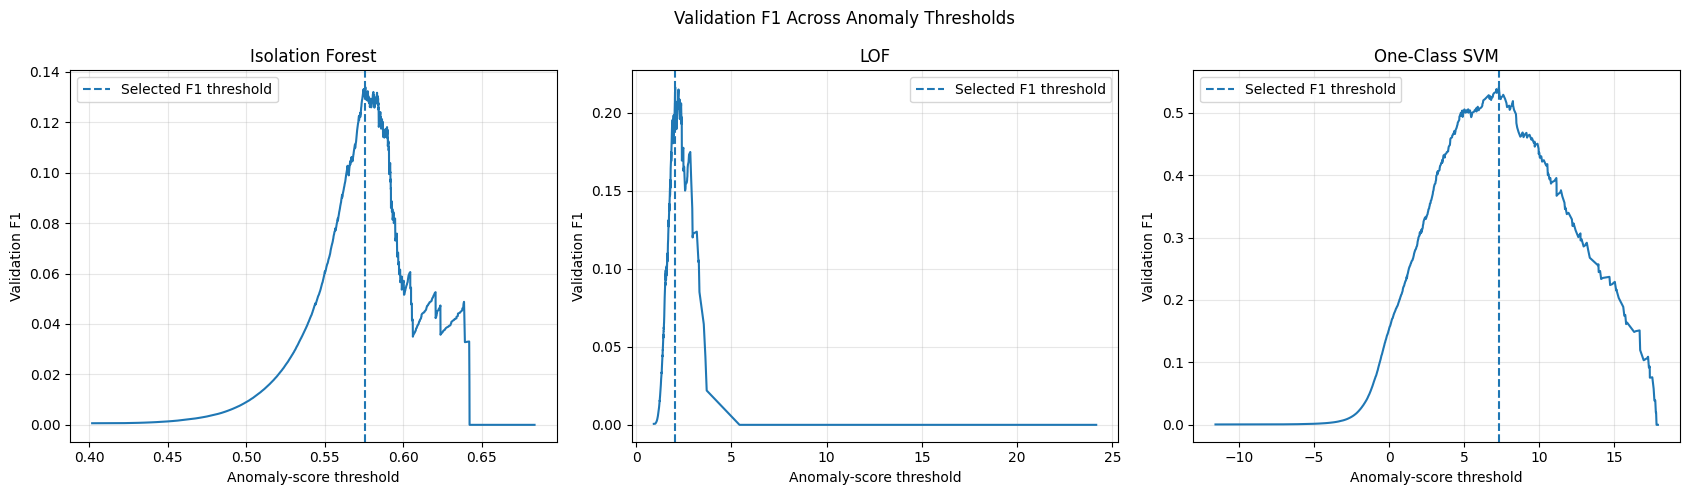

In [24]:
# ============================================================
# WORKFLOW 4 — CELL 7
# MODEL COMPARISON GRAPHS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix,
    precision_recall_curve,
    average_precision_score
)

# ------------------------------------------------------------
# 1. PRECISION-RECALL CURVES
# ------------------------------------------------------------

plt.figure(figsize=(9, 7))

for model_name, result in best_model_scores.items():

    precision, recall, _ = precision_recall_curve(
        y_test,
        result["test_scores"]
    )

    ap = average_precision_score(
        y_test,
        result["test_scores"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (AP={ap:.4f})"
    )

positive_prevalence = np.mean(y_test)

plt.axhline(
    positive_prevalence,
    linestyle="--",
    label="Positive-class prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Test Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/test_precision_recall_curves.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 2. CONFUSION MATRICES
# Use the validation-F1 threshold selected earlier.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5)
)

for ax, (model_name, result) in zip(
    axes,
    best_model_scores.items()
):

    threshold = result["thresholds"]["Validation_F1"]

    predictions = (
        result["test_scores"] >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "S4 Positive"]
    ).plot(
        ax=ax,
        colorbar=False,
        values_format=","
    )

    ax.set_title(model_name)

plt.suptitle(
    "Test Confusion Matrices — Validation-F1 Threshold",
    y=1.03
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/test_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 3. ANOMALY-SCORE DISTRIBUTIONS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, (model_name, result) in zip(
    axes,
    best_model_scores.items()
):

    scores = result["test_scores"]

    normal_scores = scores[np.asarray(y_test) == 0]
    positive_scores = scores[np.asarray(y_test) == 1]

    ax.hist(
        normal_scores,
        bins=60,
        density=True,
        alpha=0.6,
        label="S4 Negative"
    )

    ax.hist(
        positive_scores,
        bins=60,
        density=True,
        alpha=0.6,
        label="S4 Positive"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Anomaly score")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("Test Anomaly-Score Distributions")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/test_score_distributions.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# 4. VALIDATION F1 AGAINST THRESHOLD
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5)
)

for ax, (model_name, result) in zip(
    axes,
    best_model_scores.items()
):

    scores = result["validation_scores"]

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        scores
    )

    precision = precision[:-1]
    recall = recall[:-1]

    f1_values = (
        2 * precision * recall /
        (precision + recall + 1e-12)
    )

    ax.plot(
        thresholds,
        f1_values
    )

    ax.axvline(
        result["thresholds"]["Validation_F1"],
        linestyle="--",
        label="Selected F1 threshold"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Anomaly-score threshold")
    ax.set_ylabel("Validation F1")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Validation F1 Across Anomaly Thresholds")
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/validation_f1_threshold_curves.png",
    dpi=300
)

plt.show()


 Isolation Forest
--------------------------------------------------
False positives: 1362
False negatives: 18

 LOF
--------------------------------------------------
False positives: 32
False negatives: 89

 One-Class SVM
--------------------------------------------------
False positives: 42
False negatives: 36

PRN ERROR-RATE RESULTS


,Model,PRN,Observations,S4_Positive,Predicted_Anomalies,TP,FP,FN,Positive_Event_Percentage,FPR,FNR,Precision,Recall
0,Isolation Forest,1,8607,30,147,27,120,3,25.2101,0.0140,0.1000,0.1837,0.9000
1,Isolation Forest,2,10781,0,12,0,12,0,0.0000,0.0011,NaN,0.0000,NaN
2,Isolation Forest,3,7931,0,8,0,8,0,0.0000,0.0010,NaN,0.0000,NaN
3,Isolation Forest,5,10226,6,61,4,57,2,5.0420,0.0056,0.3333,0.0656,0.6667
4,Isolation Forest,6,10549,4,146,4,142,0,3.3613,0.0135,0.0000,0.0274,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
85,One-Class SVM,28,10433,1,1,1,0,0,0.8403,0.0000,0.0000,1.0000,1.0000
86,One-Class SVM,29,8040,0,1,0,1,0,0.0000,0.0001,NaN,0.0000,NaN
87,One-Class SVM,30,7624,1,0,0,0,1,0.8403,0.0000,1.0000,NaN,0.0000
88,One-Class SVM,31,9994,4,6,2,4,2,3.3613,0.0004,0.5000,0.3333,0.5000



ELEVATION ERROR-RATE RESULTS


,Model,Elevation_Band,Observations,S4_Positive,Predicted_Anomalies,TP,FP,FN,FPR,FNR,Precision,Recall
0,Isolation Forest,"[25.0, 35.0)",90437,118,1390,101,1289,17,0.0143,0.1441,0.0727,0.8559
1,Isolation Forest,"[35.0, 45.0)",65890,1,40,0,40,1,0.0006,1.0000,0.0000,0.0000
2,Isolation Forest,"[45.0, 55.0)",57336,0,9,0,9,0,0.0002,NaN,0.0000,NaN
3,Isolation Forest,"[55.0, 65.0)",40094,0,13,0,13,0,0.0003,NaN,0.0000,NaN
4,Isolation Forest,"[65.0, 75.0)",18985,0,11,0,11,0,0.0006,NaN,0.0000,NaN
5,Isolation Forest,"[75.0, 90.0)",0,0,0,0,0,0,NaN,NaN,NaN,NaN
6,LOF,"[25.0, 35.0)",90437,118,53,29,24,89,0.0003,0.7542,0.5472,0.2458
7,LOF,"[35.0, 45.0)",65890,1,2,1,1,0,0.0000,0.0000,0.5000,1.0000
8,LOF,"[45.0, 55.0)",57336,0,0,0,0,0,0.0000,NaN,NaN,NaN
9,LOF,"[55.0, 65.0)",40094,0,2,0,2,0,0.0000,NaN,0.0000,NaN


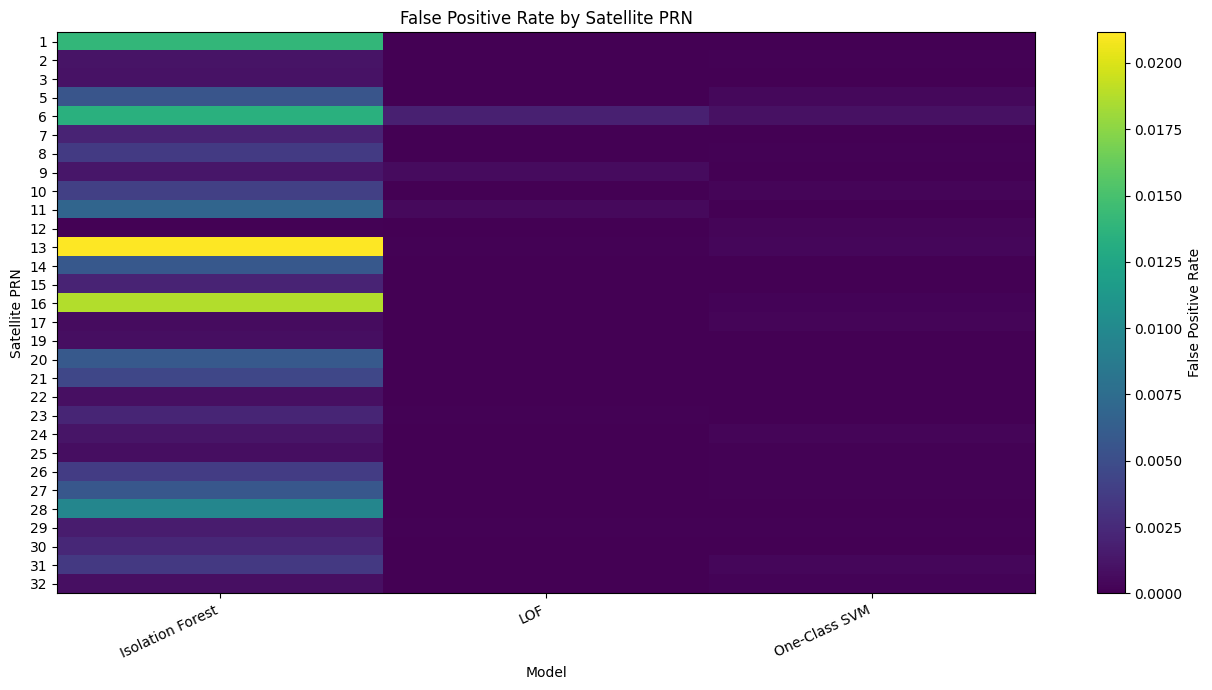

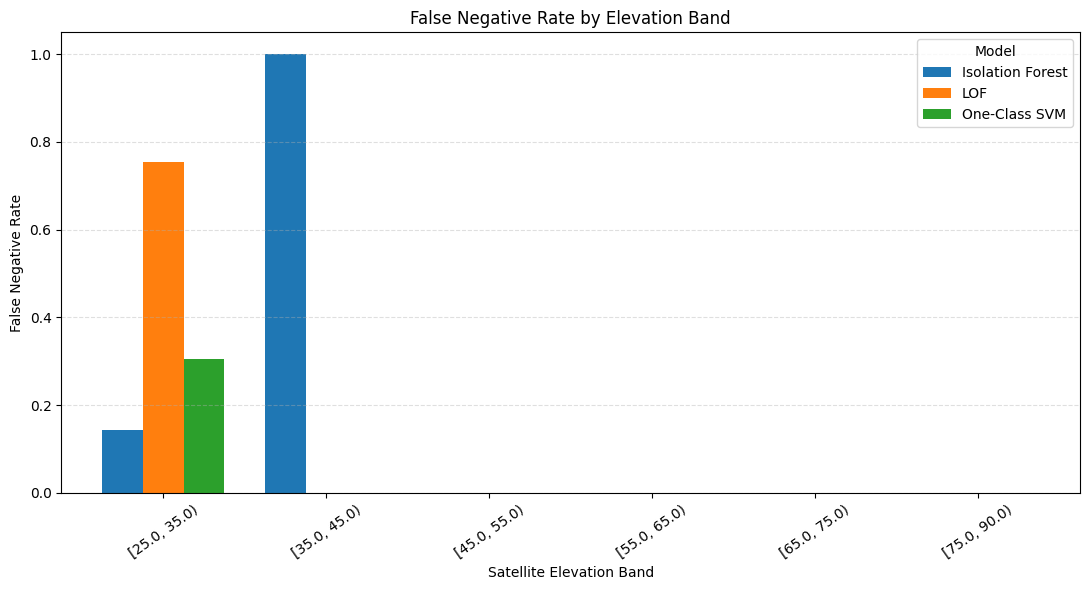


MODEL AGREEMENT TABLE


,S4 Negative,S4 Positive
Number of Models Flagging,,
0,271247,5
1,1323,36
2,46,56
3,7,22


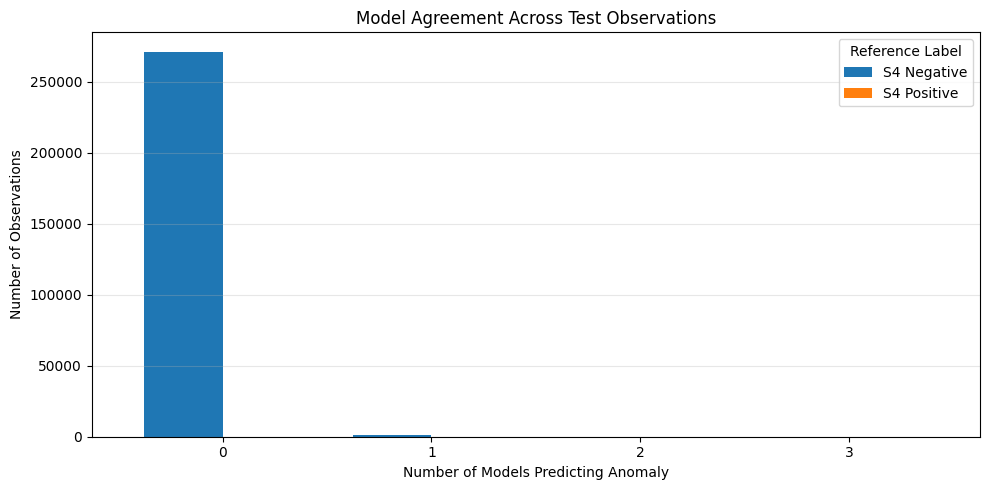

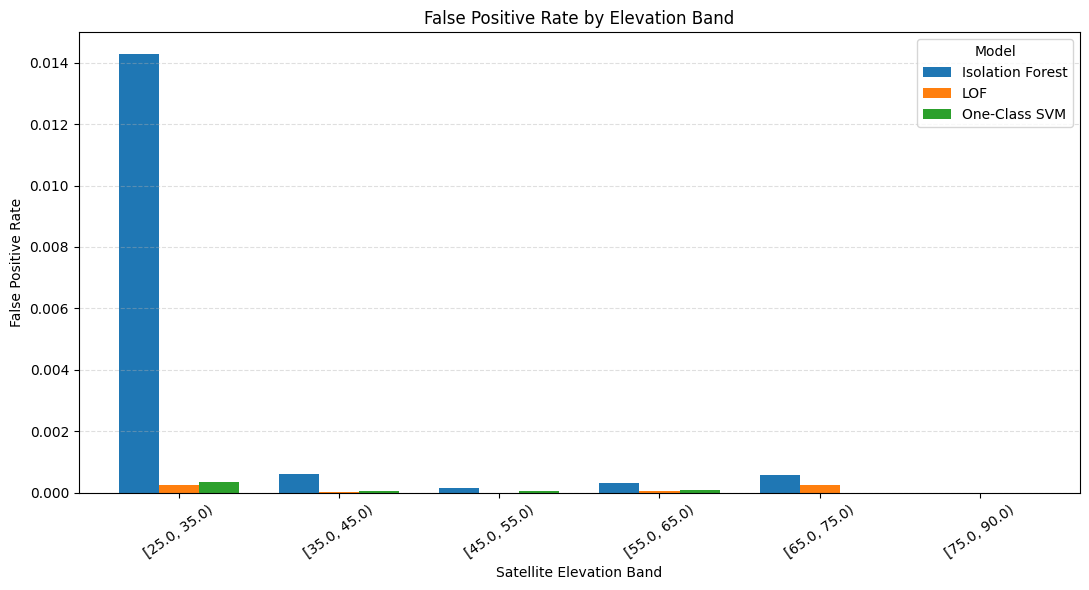


ERROR INVESTIGATION FILES SAVED.

Models analysed: 3
Test observations analysed: 272742
Unique satellite PRNs: 30
Elevation bands: 5

Saved files:
- all_test_observation_predictions.csv
- errors_by_prn.csv
- errors_by_elevation.csv
- isolation_forest_false_positives.csv
- isolation_forest_false_negatives.csv
- lof_false_positives.csv
- lof_false_negatives.csv
- one_class_svm_false_positives.csv
- one_class_svm_false_negatives.csv


In [25]:

# ============================================================
# WORKFLOW 4 — CELL 8
# OBSERVATION-LEVEL RESULTS AND ERROR INVESTIGATION
# ============================================================

# ------------------------------------------------------------
# 1. PRESERVE ORIGINAL TEST OBSERVATION IDENTIFIERS
# ------------------------------------------------------------

test_output = df_clean.loc[
    test_df.index,
    ["_DATE", "Second", "PRN", "Elevation", S4_COLUMN, TARGET]
].copy()

test_output = test_output.reset_index(drop=False)

test_output = test_output.rename(
    columns={"index": "Original_Row_Index"}
)

# Confirm observation alignment
assert len(test_output) == len(y_test), (
    "Test observations and y_test have different lengths."
)

for model_name, result in best_model_scores.items():
    assert len(result["test_scores"]) == len(test_output), (
        f"{model_name}: test scores do not match test observations."
    )


# ------------------------------------------------------------
# 2. ADD MODEL SCORES AND PREDICTIONS
# ------------------------------------------------------------

for model_name, result in best_model_scores.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    scores = np.asarray(result["test_scores"])

    threshold = result["thresholds"]["Validation_F1"]

    predictions = (
        scores >= threshold
    ).astype(int)

    test_output[f"{safe_name}_score"] = scores

    test_output[f"{safe_name}_prediction"] = predictions

    test_output[f"{safe_name}_threshold"] = threshold


# ------------------------------------------------------------
# 3. MODEL AGREEMENT
# ------------------------------------------------------------

prediction_columns = [
    f"{model_name.lower().replace(' ', '_').replace('-', '_')}_prediction"
    for model_name in best_model_scores
]

assert len(prediction_columns) > 0, "No model predictions found."

assert all(
    column in test_output.columns
    for column in prediction_columns
), "One or more model prediction columns are missing."

test_output["Models_Flagging"] = (
    test_output[prediction_columns].sum(axis=1)
)

test_output["All_Models_Agree_Anomaly"] = (
    test_output["Models_Flagging"] == len(prediction_columns)
)

test_output["At_Least_One_Model_Flags"] = (
    test_output["Models_Flagging"] >= 1
)


# ------------------------------------------------------------
# 4. IDENTIFY FALSE POSITIVES AND FALSE NEGATIVES
# ------------------------------------------------------------

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    test_output[f"{safe_name}_error_type"] = np.select(
        [
            (
                (test_output[TARGET] == 0) &
                (test_output[prediction_column] == 1)
            ),

            (
                (test_output[TARGET] == 1) &
                (test_output[prediction_column] == 0)
            )
        ],

        [
            "False Positive",
            "False Negative"
        ],

        default="Correct"
    )


# ------------------------------------------------------------
# 5. SAVE COMPLETE TEST PREDICTIONS
# ------------------------------------------------------------

test_output.to_csv(
    f"{OUTPUT_FOLDER}/all_test_observation_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# 6. SAVE FALSE POSITIVES AND FALSE NEGATIVES PER MODEL
# ------------------------------------------------------------

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    error_column = f"{safe_name}_error_type"

    false_positives = test_output[
        test_output[error_column] == "False Positive"
    ].copy()

    false_negatives = test_output[
        test_output[error_column] == "False Negative"
    ].copy()

    false_positives.to_csv(
        f"{OUTPUT_FOLDER}/{safe_name}_false_positives.csv",
        index=False
    )

    false_negatives.to_csv(
        f"{OUTPUT_FOLDER}/{safe_name}_false_negatives.csv",
        index=False
    )

    print("\n", model_name)
    print("-" * 50)

    print("False positives:", len(false_positives))
    print("False negatives:", len(false_negatives))


# ------------------------------------------------------------
# 7. ERROR DISTRIBUTION BY PRN
# ------------------------------------------------------------

prn_error_tables = []

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    for prn, group in test_output.groupby("PRN"):

        positive_count = int(group[TARGET].sum())

        predicted_count = int(group[prediction_column].sum())

        true_positive_count = int(
            (
                (group[TARGET] == 1) &
                (group[prediction_column] == 1)
            ).sum()
        )

        false_positive_count = int(
            (
                (group[TARGET] == 0) &
                (group[prediction_column] == 1)
            ).sum()
        )

        false_negative_count = int(
            (
                (group[TARGET] == 1) &
                (group[prediction_column] == 0)
            ).sum()
        )

        prn_error_tables.append({
            "Model": model_name,
            "PRN": prn,
            "Observations": len(group),
            "S4_Positive": positive_count,
            "Predicted_Anomalies": predicted_count,
            "TP": true_positive_count,
            "FP": false_positive_count,
            "FN": false_negative_count
        })


prn_error_results = pd.DataFrame(prn_error_tables)

# Percentage of all positive observations contributed by each PRN
prn_error_results["Positive_Event_Percentage"] = (
    100 * prn_error_results["S4_Positive"] /
    prn_error_results.groupby("Model")["S4_Positive"].transform("sum")
)

# Calculate PRN-level diagnostic metrics
prn_error_results["FPR"] = (
    prn_error_results["FP"] /
    (
        prn_error_results["Observations"]
        - prn_error_results["S4_Positive"]
    ).replace(0, np.nan)
)

prn_error_results["FNR"] = (
    prn_error_results["FN"] /
    prn_error_results["S4_Positive"].replace(0, np.nan)
)

prn_error_results["Precision"] = (
    prn_error_results["TP"] /
    prn_error_results["Predicted_Anomalies"].replace(0, np.nan)
)

prn_error_results["Recall"] = (
    prn_error_results["TP"] /
    prn_error_results["S4_Positive"].replace(0, np.nan)
)

prn_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_prn.csv",
    index=False
)


# ------------------------------------------------------------
# 8. ERROR DISTRIBUTION BY ELEVATION BAND
# ------------------------------------------------------------

elevation_bins = [25, 35, 45, 55, 65, 75, 90.000001]

test_output["Elevation_Band"] = pd.cut(
    test_output["Elevation"],
    bins=elevation_bins,
    right=False,
    include_lowest=True
)

elevation_error_tables = []

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    for band, group in test_output.groupby(
        "Elevation_Band",
        observed=False
    ):

        elevation_error_tables.append({
            "Model": model_name,
            "Elevation_Band": str(band),
            "Observations": len(group),
            "S4_Positive": int(group[TARGET].sum()),
            "Predicted_Anomalies": int(
                group[prediction_column].sum()
            ),
            "TP": int(
                (
                    (group[TARGET] == 1) &
                    (group[prediction_column] == 1)
                ).sum()
            ),
            "FP": int(
                (
                    (group[TARGET] == 0) &
                    (group[prediction_column] == 1)
                ).sum()
            ),
            "FN": int(
                (
                    (group[TARGET] == 1) &
                    (group[prediction_column] == 0)
                ).sum()
            )
        })


elevation_error_results = pd.DataFrame(
    elevation_error_tables
)

# Calculate elevation-level diagnostic metrics
elevation_error_results["FPR"] = (
    elevation_error_results["FP"] /
    (
        elevation_error_results["Observations"]
        - elevation_error_results["S4_Positive"]
    ).replace(0, np.nan)
)

elevation_error_results["FNR"] = (
    elevation_error_results["FN"] /
    elevation_error_results["S4_Positive"].replace(0, np.nan)
)

elevation_error_results["Precision"] = (
    elevation_error_results["TP"] /
    elevation_error_results["Predicted_Anomalies"].replace(0, np.nan)
)

elevation_error_results["Recall"] = (
    elevation_error_results["TP"] /
    elevation_error_results["S4_Positive"].replace(0, np.nan)
)

elevation_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_elevation.csv",
    index=False
)


# ------------------------------------------------------------
# 9. DISPLAY DIAGNOSTIC TABLES
# ------------------------------------------------------------

print("\nPRN ERROR-RATE RESULTS")

display(
    prn_error_results.round(4)
)

print("\nELEVATION ERROR-RATE RESULTS")

display(
    elevation_error_results.round(4)
)


# ============================================================
# 10. DIAGNOSTIC VISUALISATIONS
# ============================================================

# ------------------------------------------------------------
# GRAPH 1 — FALSE POSITIVE RATE BY PRN
# ------------------------------------------------------------

prn_pivot = prn_error_results.pivot(
    index="PRN",
    columns="Model",
    values="FPR"
)

fig, ax = plt.subplots(figsize=(13, 7))

im = ax.imshow(
    prn_pivot.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(prn_pivot.columns))
)

ax.set_xticklabels(
    prn_pivot.columns,
    rotation=25,
    ha="right"
)

ax.set_yticks(
    np.arange(len(prn_pivot.index))
)

ax.set_yticklabels(
    prn_pivot.index
)

ax.set_title("False Positive Rate by Satellite PRN")
ax.set_xlabel("Model")
ax.set_ylabel("Satellite PRN")

fig.colorbar(
    im,
    ax=ax,
    label="False Positive Rate"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 2 — FALSE NEGATIVE RATE BY ELEVATION BAND
# ------------------------------------------------------------

elevation_pivot = elevation_error_results.pivot(
    index="Elevation_Band",
    columns="Model",
    values="FNR"
)

fig, ax = plt.subplots(figsize=(11, 6))

elevation_pivot.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("False Negative Rate by Elevation Band")
ax.set_xlabel("Satellite Elevation Band")
ax.set_ylabel("False Negative Rate")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.tick_params(axis="x", rotation=35)

ax.legend(title="Model")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 3 — MODEL AGREEMENT
# ------------------------------------------------------------

agreement_table = pd.crosstab(
    test_output["Models_Flagging"],
    test_output[TARGET]
).reindex(
    index=range(len(prediction_columns) + 1),
    columns=[0, 1],
    fill_value=0
)

agreement_table.columns = [
    "S4 Negative",
    "S4 Positive"
]

agreement_table.index.name = "Number of Models Flagging"

print("\nMODEL AGREEMENT TABLE")

display(agreement_table)

ax = agreement_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Model Agreement Across Test Observations")
ax.set_xlabel("Number of Models Predicting Anomaly")
ax.set_ylabel("Number of Observations")

ax.grid(
    axis="y",
    alpha=0.3
)

ax.tick_params(axis="x", rotation=0)

ax.legend(title="Reference Label")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 4 — FALSE POSITIVE RATE BY ELEVATION BAND
# ------------------------------------------------------------

elevation_fpr_pivot = elevation_error_results.pivot(
    index="Elevation_Band",
    columns="Model",
    values="FPR"
)

ax = elevation_fpr_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("False Positive Rate by Elevation Band")
ax.set_xlabel("Satellite Elevation Band")
ax.set_ylabel("False Positive Rate")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.tick_params(axis="x", rotation=35)

ax.legend(title="Model")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. COMPLETION REPORT
# ------------------------------------------------------------

print("\nERROR INVESTIGATION FILES SAVED.")

print("\nModels analysed:", len(best_model_scores))
print("Test observations analysed:", len(test_output))
print("Unique satellite PRNs:", test_output["PRN"].nunique())
print("Elevation bands:", test_output["Elevation_Band"].nunique())

print("\nSaved files:")
print("- all_test_observation_predictions.csv")
print("- errors_by_prn.csv")
print("- errors_by_elevation.csv")

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    print(f"- {safe_name}_false_positives.csv")
    print(f"- {safe_name}_false_negatives.csv")



 Isolation Forest
--------------------------------------------------
False positives: 1362
False negatives: 18

 LOF
--------------------------------------------------
False positives: 32
False negatives: 89

 One-Class SVM
--------------------------------------------------
False positives: 42
False negatives: 36

PRN ERROR-RATE RESULTS


,Model,PRN,Observations,S4_Positive,Predicted_Anomalies,TP,FP,FN,FPR,FNR,Precision,Recall
0,Isolation Forest,1,8607,30,147,27,120,3,0.0140,0.1000,0.1837,0.9000
1,Isolation Forest,2,10781,0,12,0,12,0,0.0011,NaN,0.0000,NaN
2,Isolation Forest,3,7931,0,8,0,8,0,0.0010,NaN,0.0000,NaN
3,Isolation Forest,5,10226,6,61,4,57,2,0.0056,0.3333,0.0656,0.6667
4,Isolation Forest,6,10549,4,146,4,142,0,0.0135,0.0000,0.0274,1.0000
...,...,...,...,...,...,...,...,...,...,...,...,...
85,One-Class SVM,28,10433,1,1,1,0,0,0.0000,0.0000,1.0000,1.0000
86,One-Class SVM,29,8040,0,1,0,1,0,0.0001,NaN,0.0000,NaN
87,One-Class SVM,30,7624,1,0,0,0,1,0.0000,1.0000,NaN,0.0000
88,One-Class SVM,31,9994,4,6,2,4,2,0.0004,0.5000,0.3333,0.5000



ELEVATION ERROR-RATE RESULTS


,Model,Elevation_Band,Observations,S4_Positive,Predicted_Anomalies,TP,FP,FN,FPR,FNR,Precision,Recall
0,Isolation Forest,"[25.0, 35.0)",90437,118,1390,101,1289,17,0.0143,0.1441,0.0727,0.8559
1,Isolation Forest,"[35.0, 45.0)",65890,1,40,0,40,1,0.0006,1.0000,0.0000,0.0000
2,Isolation Forest,"[45.0, 55.0)",57336,0,9,0,9,0,0.0002,NaN,0.0000,NaN
3,Isolation Forest,"[55.0, 65.0)",40094,0,13,0,13,0,0.0003,NaN,0.0000,NaN
4,Isolation Forest,"[65.0, 75.0)",18985,0,11,0,11,0,0.0006,NaN,0.0000,NaN
5,Isolation Forest,"[75.0, 90.0)",0,0,0,0,0,0,NaN,NaN,NaN,NaN
6,LOF,"[25.0, 35.0)",90437,118,53,29,24,89,0.0003,0.7542,0.5472,0.2458
7,LOF,"[35.0, 45.0)",65890,1,2,1,1,0,0.0000,0.0000,0.5000,1.0000
8,LOF,"[45.0, 55.0)",57336,0,0,0,0,0,0.0000,NaN,NaN,NaN
9,LOF,"[55.0, 65.0)",40094,0,2,0,2,0,0.0000,NaN,0.0000,NaN


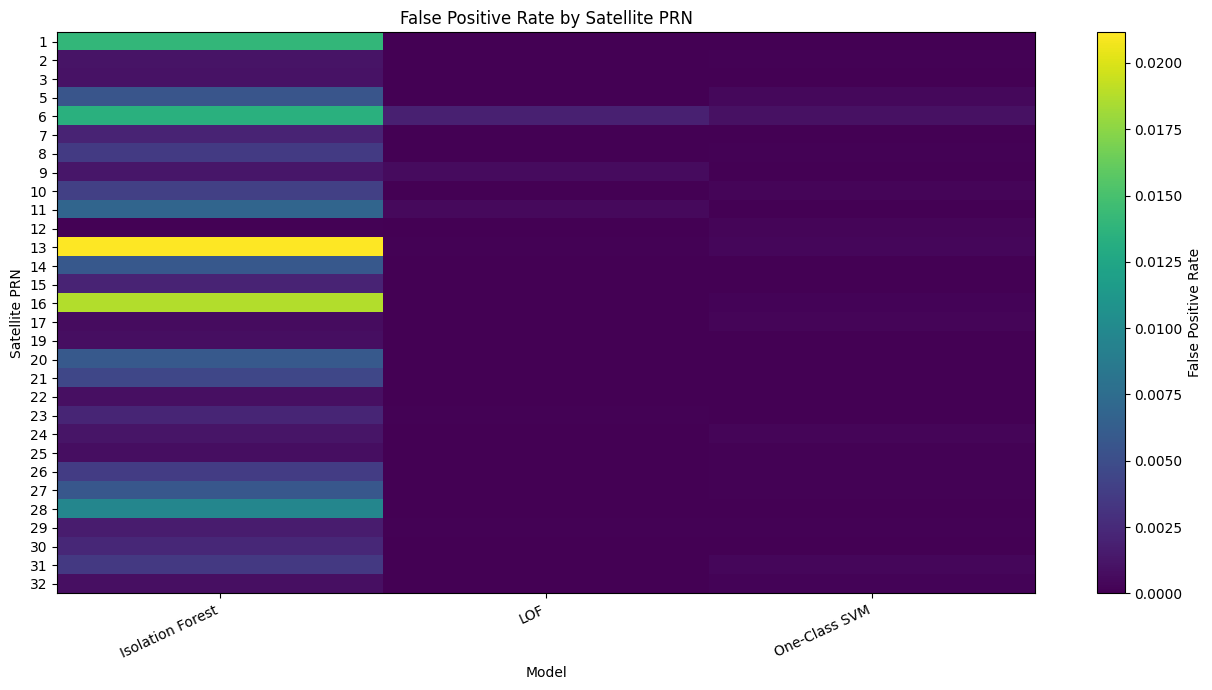

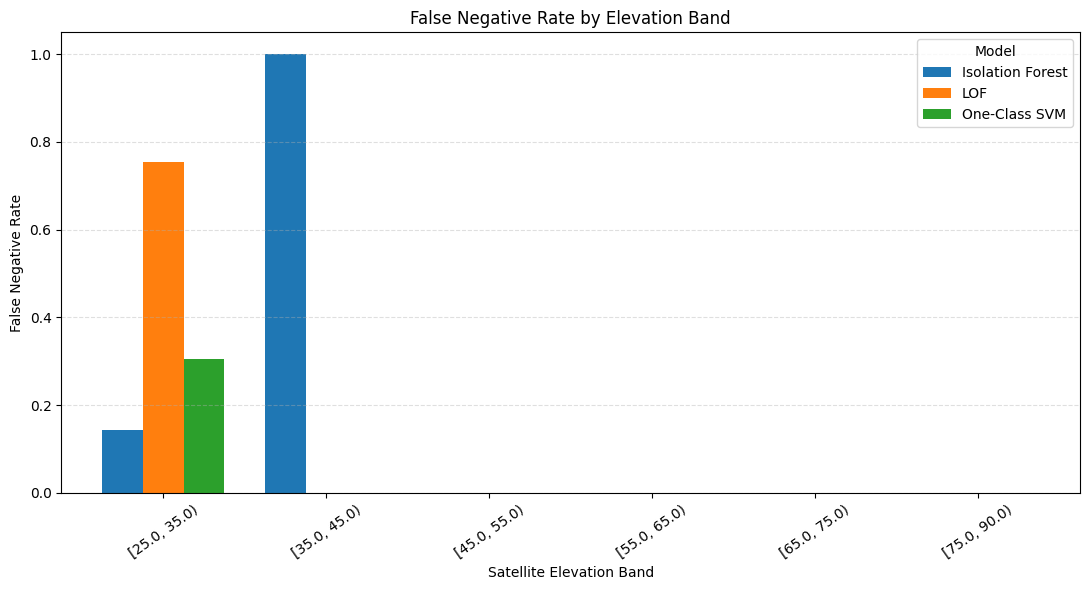


MODEL AGREEMENT TABLE


,S4 Negative,S4 Positive
Number of Models Flagging,,
0,271247,5
1,1323,36
2,46,56
3,7,22


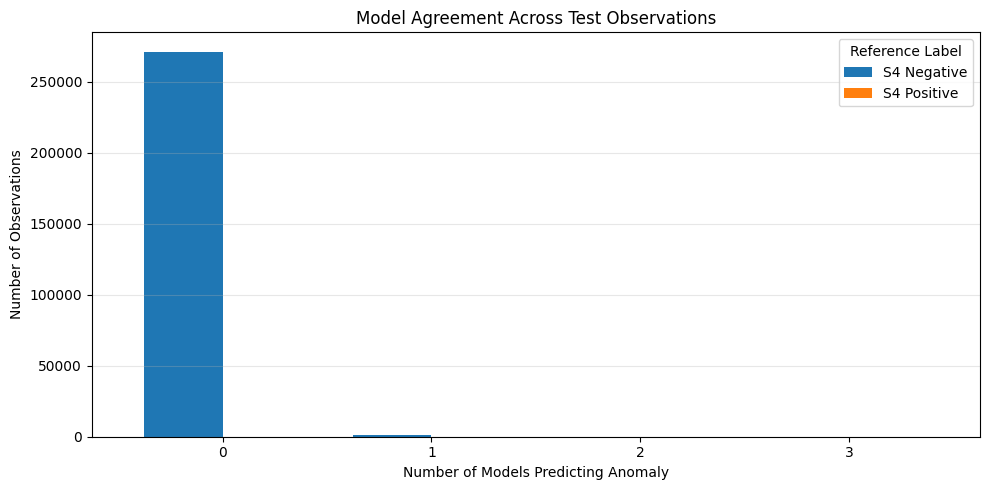

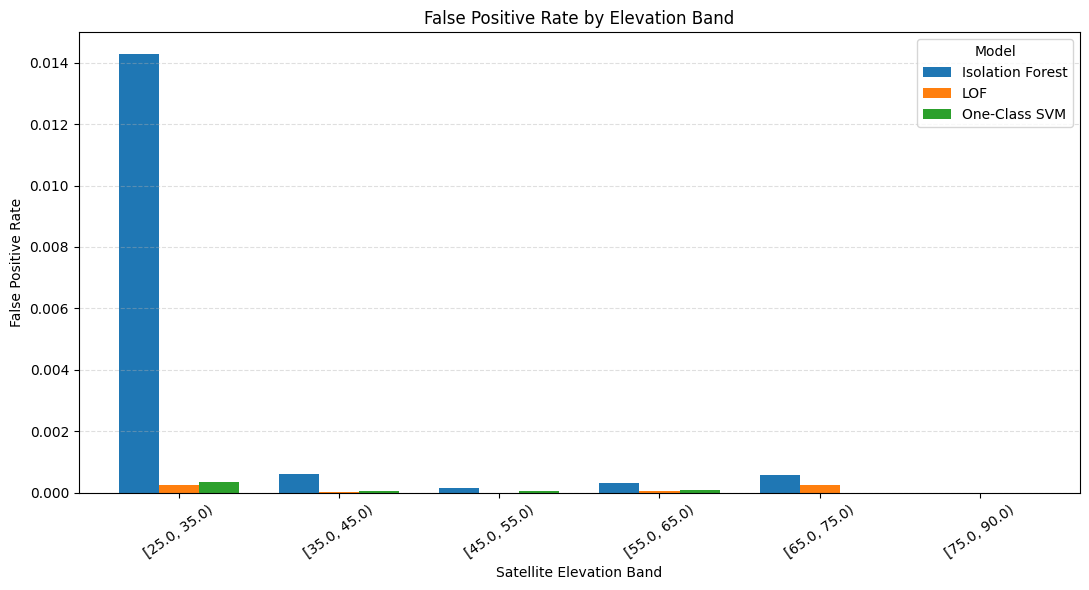


ERROR INVESTIGATION FILES SAVED.


In [26]:
# ============================================================
# WORKFLOW 4 — CELL 8
# OBSERVATION-LEVEL RESULTS AND ERROR INVESTIGATION
# ============================================================

# ------------------------------------------------------------
# PRESERVE ORIGINAL TEST OBSERVATION IDENTIFIERS
# ------------------------------------------------------------

test_output = df_clean.loc[
    test_df.index,
    ["_DATE", "Second", "PRN", "Elevation", S4_COLUMN, TARGET]
].copy()

test_output = test_output.reset_index(drop=False)

test_output = test_output.rename(
    columns={"index": "Original_Row_Index"}
)

assert len(test_output) == len(y_test)

for model_name, result in best_model_scores.items():
    assert len(result["test_scores"]) == len(test_output)

# ------------------------------------------------------------
# ADD MODEL SCORES AND PREDICTIONS
# ------------------------------------------------------------

for model_name, result in best_model_scores.items():

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    scores = result["test_scores"]

    threshold = result["thresholds"]["Validation_F1"]

    predictions = (
        scores >= threshold
    ).astype(int)

    test_output[f"{safe_name}_score"] = scores

    test_output[f"{safe_name}_prediction"] = predictions

    test_output[f"{safe_name}_threshold"] = threshold


# ------------------------------------------------------------
# MODEL AGREEMENT
# ------------------------------------------------------------

prediction_columns = [
    "isolation_forest_prediction",
    "lof_prediction",
    "one_class_svm_prediction"
]

test_output["Models_Flagging"] = (
    test_output[prediction_columns].sum(axis=1)
)

test_output["All_Models_Agree_Anomaly"] = (
    test_output["Models_Flagging"] == 3
)

test_output["At_Least_One_Model_Flags"] = (
    test_output["Models_Flagging"] >= 1
)


# ------------------------------------------------------------
# FALSE POSITIVES AND FALSE NEGATIVES
# ------------------------------------------------------------

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    test_output[f"{safe_name}_error_type"] = np.select(
        [
            (
                (test_output[TARGET] == 0) &
                (test_output[prediction_column] == 1)
            ),

            (
                (test_output[TARGET] == 1) &
                (test_output[prediction_column] == 0)
            )
        ],

        [
            "False Positive",
            "False Negative"
        ],

        default="Correct"
    )


# ------------------------------------------------------------
# SAVE COMPLETE TEST PREDICTIONS
# ------------------------------------------------------------

test_output.to_csv(
    f"{OUTPUT_FOLDER}/all_test_observation_predictions.csv",
    index=False
)


# ------------------------------------------------------------
# SAVE FALSE POSITIVES AND FALSE NEGATIVES PER MODEL
# ------------------------------------------------------------

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    error_column = f"{safe_name}_error_type"

    false_positives = test_output[
        test_output[error_column] == "False Positive"
    ].copy()

    false_negatives = test_output[
        test_output[error_column] == "False Negative"
    ].copy()

    false_positives.to_csv(
        f"{OUTPUT_FOLDER}/{safe_name}_false_positives.csv",
        index=False
    )

    false_negatives.to_csv(
        f"{OUTPUT_FOLDER}/{safe_name}_false_negatives.csv",
        index=False
    )

    print("\n", model_name)
    print("-" * 50)

    print("False positives:", len(false_positives))
    print("False negatives:", len(false_negatives))


# ------------------------------------------------------------
# ERROR DISTRIBUTION BY PRN
# ------------------------------------------------------------

prn_error_tables = []

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    for prn, group in test_output.groupby("PRN"):

        positive_count = int(group[TARGET].sum())

        predicted_count = int(group[prediction_column].sum())

        true_positive_count = int(
            (
                (group[TARGET] == 1) &
                (group[prediction_column] == 1)
            ).sum()
        )

        false_positive_count = int(
            (
                (group[TARGET] == 0) &
                (group[prediction_column] == 1)
            ).sum()
        )

        false_negative_count = int(
            (
                (group[TARGET] == 1) &
                (group[prediction_column] == 0)
            ).sum()
        )

        prn_error_tables.append({
            "Model": model_name,
            "PRN": prn,
            "Observations": len(group),
            "S4_Positive": positive_count,
            "Predicted_Anomalies": predicted_count,
            "TP": true_positive_count,
            "FP": false_positive_count,
            "FN": false_negative_count
        })


prn_error_results = pd.DataFrame(prn_error_tables)

prn_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_prn.csv",
    index=False
)


# ------------------------------------------------------------
# ERROR DISTRIBUTION BY ELEVATION BAND
# ------------------------------------------------------------

elevation_bins = [25, 35, 45, 55, 65, 75, 90.000001]

test_output["Elevation_Band"] = pd.cut(
    test_output["Elevation"],
    bins=elevation_bins,
    right=False,
    include_lowest=True
)

elevation_error_tables = []

for model_name in best_model_scores:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_column = f"{safe_name}_prediction"

    for band, group in test_output.groupby(
        "Elevation_Band",
        observed=False
    ):

        elevation_error_tables.append({
            "Model": model_name,
            "Elevation_Band": str(band),
            "Observations": len(group),
            "S4_Positive": int(group[TARGET].sum()),
            "Predicted_Anomalies": int(
                group[prediction_column].sum()
            ),
            "TP": int(
                (
                    (group[TARGET] == 1) &
                    (group[prediction_column] == 1)
                ).sum()
            ),
            "FP": int(
                (
                    (group[TARGET] == 0) &
                    (group[prediction_column] == 1)
                ).sum()
            ),
            "FN": int(
                (
                    (group[TARGET] == 1) &
                    (group[prediction_column] == 0)
                ).sum()
            )
        })


elevation_error_results = pd.DataFrame(
    elevation_error_tables
)

elevation_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_elevation.csv",
    index=False
)


# ============================================================
# CELL 8 — ADDITIONAL DIAGNOSTIC METRICS
# ============================================================

# ------------------------------------------------------------
# 1. ERROR RATES BY PRN
# ------------------------------------------------------------

prn_error_results["FPR"] = (
    prn_error_results["FP"] /
    prn_error_results["Observations"].sub(
        prn_error_results["S4_Positive"]
    ).replace(0, np.nan)
)

prn_error_results["FNR"] = (
    prn_error_results["FN"] /
    prn_error_results["S4_Positive"].replace(0, np.nan)
)

prn_error_results["Precision"] = (
    prn_error_results["TP"] /
    prn_error_results["Predicted_Anomalies"].replace(0, np.nan)
)

prn_error_results["Recall"] = (
    prn_error_results["TP"] /
    prn_error_results["S4_Positive"].replace(0, np.nan)
)

prn_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_prn.csv",
    index=False
)


# ------------------------------------------------------------
# 2. ERROR RATES BY ELEVATION BAND
# ------------------------------------------------------------

elevation_error_results["FPR"] = (
    elevation_error_results["FP"] /
    (
        elevation_error_results["Observations"]
        - elevation_error_results["S4_Positive"]
    ).replace(0, np.nan)
)

elevation_error_results["FNR"] = (
    elevation_error_results["FN"] /
    elevation_error_results["S4_Positive"].replace(0, np.nan)
)

elevation_error_results["Precision"] = (
    elevation_error_results["TP"] /
    elevation_error_results["Predicted_Anomalies"].replace(0, np.nan)
)

elevation_error_results["Recall"] = (
    elevation_error_results["TP"] /
    elevation_error_results["S4_Positive"].replace(0, np.nan)
)

elevation_error_results.to_csv(
    f"{OUTPUT_FOLDER}/errors_by_elevation.csv",
    index=False
)


# ------------------------------------------------------------
# 3. SAVE UPDATED DIAGNOSTIC TABLES
# ------------------------------------------------------------

print("\nPRN ERROR-RATE RESULTS")

display(
    prn_error_results.round(4)
)

print("\nELEVATION ERROR-RATE RESULTS")

display(
    elevation_error_results.round(4)
)


# ============================================================
# CELL 8 — DIAGNOSTIC VISUALISATIONS
# ============================================================


# ------------------------------------------------------------
# GRAPH 2 — FALSE POSITIVE RATE BY PRN
# ------------------------------------------------------------

prn_pivot = prn_error_results.pivot(
    index="PRN",
    columns="Model",
    values="FPR"
)

fig, ax = plt.subplots(figsize=(13, 7))

im = ax.imshow(
    prn_pivot.values,
    aspect="auto",
    interpolation="nearest"
)

ax.set_xticks(
    np.arange(len(prn_pivot.columns))
)

ax.set_xticklabels(
    prn_pivot.columns,
    rotation=25,
    ha="right"
)

ax.set_yticks(
    np.arange(len(prn_pivot.index))
)

ax.set_yticklabels(
    prn_pivot.index
)

ax.set_title("False Positive Rate by Satellite PRN")
ax.set_xlabel("Model")
ax.set_ylabel("Satellite PRN")

fig.colorbar(
    im,
    ax=ax,
    label="False Positive Rate"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 3 — FALSE NEGATIVE RATE BY ELEVATION BAND
# ------------------------------------------------------------

elevation_pivot = elevation_error_results.pivot(
    index="Elevation_Band",
    columns="Model",
    values="FNR"
)

fig, ax = plt.subplots(figsize=(11, 6))

elevation_pivot.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("False Negative Rate by Elevation Band")
ax.set_xlabel("Satellite Elevation Band")
ax.set_ylabel("False Negative Rate")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.tick_params(axis="x", rotation=35)

ax.legend(title="Model")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 4 — MODEL AGREEMENT
# ------------------------------------------------------------

agreement_table = pd.crosstab(
    test_output["Models_Flagging"],
    test_output[TARGET]
).reindex(
    index=[0, 1, 2, 3],
    columns=[0, 1],
    fill_value=0
)

agreement_table.columns = [
    "S4 Negative",
    "S4 Positive"
]

agreement_table.index.name = "Number of Models Flagging"

print("\nMODEL AGREEMENT TABLE")

display(agreement_table)

ax = agreement_table.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75
)

ax.set_title("Model Agreement Across Test Observations")
ax.set_xlabel("Number of Models Predicting Anomaly")
ax.set_ylabel("Number of Observations")

ax.grid(
    axis="y",
    alpha=0.3
)

ax.tick_params(axis="x", rotation=0)

ax.legend(title="Reference Label")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# GRAPH 5 — FALSE POSITIVE RATE BY ELEVATION BAND
# ------------------------------------------------------------

elevation_fpr_pivot = elevation_error_results.pivot(
    index="Elevation_Band",
    columns="Model",
    values="FPR"
)

ax = elevation_fpr_pivot.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title("False Positive Rate by Elevation Band")
ax.set_xlabel("Satellite Elevation Band")
ax.set_ylabel("False Positive Rate")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

ax.tick_params(axis="x", rotation=35)

ax.legend(title="Model")

plt.tight_layout()
plt.show()


print("\nERROR INVESTIGATION FILES SAVED.")

In [27]:

# ============================================================
# WORKFLOW 4 — CELL 9
# S4 REFERENCE THRESHOLD SENSITIVITY
# ============================================================

S4_SENSITIVITY_THRESHOLD = 0.30

# Confirm that the reference variable is corrected S4.
if S4_COLUMN != "Corrected_S4":
    raise ValueError(
        "S4_COLUMN must refer to Corrected_S4 for this analysis."
    )


# ------------------------------------------------------------
# 1. CREATE ALTERNATIVE REFERENCE LABELS
# ------------------------------------------------------------

y_val_030 = (
    val_df[S4_COLUMN] >= S4_SENSITIVITY_THRESHOLD
).astype(int)

y_test_030 = (
    test_df[S4_COLUMN] >= S4_SENSITIVITY_THRESHOLD
).astype(int)


print("S4 REFERENCE THRESHOLD SENSITIVITY")
print("-" * 60)

print("Main S4 threshold: 0.20")
print("Alternative S4 threshold:", S4_SENSITIVITY_THRESHOLD)

print("\nValidation observations:", len(y_val_030))
print("Validation positives:", int(y_val_030.sum()))

print("\nTest observations:", len(y_test_030))
print("Test positives:", int(y_test_030.sum()))

print(
    "Validation positive prevalence:",
    round(y_val_030.mean(), 6)
)

print(
    "Test positive prevalence:",
    round(y_test_030.mean(), 6)
)


# ------------------------------------------------------------
# 2. RUN TWO THRESHOLD EXPERIMENTS
# ------------------------------------------------------------

s4_sensitivity_rows = []

for model_name, result in best_model_scores.items():

    val_scores = result["validation_scores"]
    test_scores = result["test_scores"]

    # --------------------------------------------------------
    # EXPERIMENT A:
    # KEEP THE ANOMALY THRESHOLD SELECTED AT S4 >= 0.20
    # --------------------------------------------------------

    fixed_threshold = result["thresholds"]["Validation_F1"]

    fixed_val_metrics = calculate_metrics(
        y_val_030,
        val_scores,
        fixed_threshold
    )

    fixed_test_metrics = calculate_metrics(
        y_test_030,
        test_scores,
        fixed_threshold
    )

    s4_sensitivity_rows.append({

        "Model": model_name,

        "Experiment": "Fixed_0.20_Anomaly_Threshold",

        "S4_Reference_Threshold": S4_SENSITIVITY_THRESHOLD,

        "Anomaly_Threshold": fixed_threshold,

        **{
            f"Validation_{k}": v
            for k, v in fixed_val_metrics.items()
            if k != "Threshold"
        },

        **{
            f"Test_{k}": v
            for k, v in fixed_test_metrics.items()
            if k != "Threshold"
        }
    })


    # --------------------------------------------------------
    # EXPERIMENT B:
    # RECALIBRATE ANOMALY THRESHOLD USING 0.30 LABELS
    # --------------------------------------------------------

    recalibrated_threshold = find_best_f1_threshold(
        y_val_030,
        val_scores
    )

    recalibrated_val_metrics = calculate_metrics(
        y_val_030,
        val_scores,
        recalibrated_threshold
    )

    recalibrated_test_metrics = calculate_metrics(
        y_test_030,
        test_scores,
        recalibrated_threshold
    )

    s4_sensitivity_rows.append({

        "Model": model_name,

        "Experiment": "Recalibrated_0.30_Anomaly_Threshold",

        "S4_Reference_Threshold": S4_SENSITIVITY_THRESHOLD,

        "Anomaly_Threshold": recalibrated_threshold,

        **{
            f"Validation_{k}": v
            for k, v in recalibrated_val_metrics.items()
            if k != "Threshold"
        },

        **{
            f"Test_{k}": v
            for k, v in recalibrated_test_metrics.items()
            if k != "Threshold"
        }
    })


    # --------------------------------------------------------
    # PRINT RESULTS
    # --------------------------------------------------------

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    print("\nExperiment A — Fixed anomaly threshold")

    print("Threshold:", round(fixed_threshold, 6))

    print(
        "Test Recall:",
        round(fixed_test_metrics["Recall"], 6)
    )

    print(
        "Test F1:",
        round(fixed_test_metrics["F1"], 6)
    )

    print(
        "Test FPR:",
        round(fixed_test_metrics["FPR"], 6)
    )

    print("\nExperiment B — Recalibrated anomaly threshold")

    print("Threshold:", round(recalibrated_threshold, 6))

    print(
        "Test Recall:",
        round(recalibrated_test_metrics["Recall"], 6)
    )

    print(
        "Test F1:",
        round(recalibrated_test_metrics["F1"], 6)
    )

    print(
        "Test FPR:",
        round(recalibrated_test_metrics["FPR"], 6)
    )


# ------------------------------------------------------------
# 3. CREATE SENSITIVITY RESULTS TABLE
# ------------------------------------------------------------

s4_sensitivity_results = pd.DataFrame(
    s4_sensitivity_rows
)

print("\nS4 THRESHOLD SENSITIVITY RESULTS")

display(
    s4_sensitivity_results.round(6)
)

s4_sensitivity_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_threshold_sensitivity.csv",
    index=False
)


# ------------------------------------------------------------
# 4. SEPARATE FIXED AND RECALIBRATED RESULTS
# ------------------------------------------------------------

s4_fixed_results = s4_sensitivity_results[
    s4_sensitivity_results["Experiment"]
    == "Fixed_0.20_Anomaly_Threshold"
].copy()

s4_recalibrated_results = s4_sensitivity_results[
    s4_sensitivity_results["Experiment"]
    == "Recalibrated_0.30_Anomaly_Threshold"
].copy()


# ------------------------------------------------------------
# 5. COMPARE FIVE PERFORMANCE METRICS
# ------------------------------------------------------------

metrics = {

    "Recall": "Recall",

    "F1": "F1",

    "ROC-AUC": "ROC_AUC",

    "PR-AUC": "Average_Precision",

    "MCC": "MCC"
}


# ------------------------------------------------------------
# 6. FIXED-THRESHOLD COMPARISON GRAPHS
# ------------------------------------------------------------

for split in ["Validation", "Test"]:

    plot_model_comparison(
        s4_fixed_results,

        title=(
            f"S4 >= 0.30 — {split} Performance "
            "(Fixed Anomaly Threshold)"
        ),

        model_col="Model",

        metrics={
            label: f"{split}_{column}"
            for label, column in metrics.items()
        }
    )


# ------------------------------------------------------------
# 7. RECALIBRATED-THRESHOLD COMPARISON GRAPHS
# ------------------------------------------------------------

for split in ["Validation", "Test"]:

    plot_model_comparison(
        s4_recalibrated_results,

        title=(
            f"S4 >= 0.30 — {split} Performance "
            "(Recalibrated Anomaly Threshold)"
        ),

        model_col="Model",

        metrics={
            label: f"{split}_{column}"
            for label, column in metrics.items()
        }
    )


# ------------------------------------------------------------
# 8. SAVE SEPARATE EXPERIMENT TABLES
# ------------------------------------------------------------

s4_fixed_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_fixed_threshold_results.csv",
    index=False
)

s4_recalibrated_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_recalibrated_threshold_results.csv",
    index=False
)

print("\nS4 SENSITIVITY ANALYSIS COMPLETED.")
print("Combined, fixed-threshold and recalibrated results saved.")


S4 REFERENCE THRESHOLD SENSITIVITY
------------------------------------------------------------
Main S4 threshold: 0.20
Alternative S4 threshold: 0.3

Validation observations: 264410
Validation positives: 6

Test observations: 272742
Test positives: 7
Validation positive prevalence: 2.3e-05
Test positive prevalence: 2.6e-05

MODEL: Isolation Forest

Experiment A — Fixed anomaly threshold
Threshold: 0.576022
Test Recall: 0.714286
Test F1: 0.006803
Test FPR: 0.005346

Experiment B — Recalibrated anomaly threshold
Threshold: 0.581114
Test Recall: 0.714286
Test F1: 0.008285
Test FPR: 0.004382

MODEL: LOF

Experiment A — Fixed anomaly threshold
Threshold: 2.053868
Test Recall: 1.0
Test F1: 0.202899
Test FPR: 0.000202

Experiment B — Recalibrated anomaly threshold
Threshold: 3.187928
Test Recall: 0.714286
Test F1: 0.769231
Test FPR: 4e-06

MODEL: One-Class SVM

Experiment A — Fixed anomaly threshold
Threshold: 7.313786
Test Recall: 1.0
Test F1: 0.106061
Test FPR: 0.000433

Experiment B — Rec

,Model,Experiment,S4_Reference_Threshold,Anomaly_Threshold,Validation_TP,Validation_FP,Validation_FN,Validation_TN,Validation_Detected_Anomalies,Validation_Precision,...,Test_FN,Test_TN,Test_Detected_Anomalies,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_ROC_AUC,Test_FPR,Test_Specificity
0,Isolation Forest,Fixed_0.20_Anomaly_Threshold,0.3,0.576022,4,868,2,263536,872,0.004587,...,2,271277,1463,0.003418,0.714286,0.006803,0.004038,0.996259,0.005346,0.994654
1,Isolation Forest,Recalibrated_0.30_Anomaly_Threshold,0.3,0.581114,4,715,2,263689,719,0.005563,...,2,271540,1200,0.004167,0.714286,0.008285,0.004038,0.996259,0.004382,0.995618
2,LOF,Fixed_0.20_Anomaly_Threshold,0.3,2.053868,6,95,0,264309,101,0.059406,...,0,272680,62,0.112903,1.000000,0.202899,0.912925,0.999997,0.000202,0.999798
3,LOF,Recalibrated_0.30_Anomaly_Threshold,0.3,3.187928,6,7,0,264397,13,0.461538,...,2,272734,6,0.833333,0.714286,0.769231,0.912925,0.999997,0.000004,0.999996
4,One-Class SVM,Fixed_0.20_Anomaly_Threshold,0.3,7.313786,6,143,0,264261,149,0.040268,...,0,272617,125,0.056000,1.000000,0.106061,0.968254,0.999999,0.000433,0.999567
5,One-Class SVM,Recalibrated_0.30_Anomaly_Threshold,0.3,17.247865,6,20,0,264384,26,0.230769,...,1,272735,6,1.000000,0.857143,0.923077,0.968254,0.999999,0.000000,1.000000


ValueError: Missing columns for comparison plot: ['Validation_MCC']
Available columns: ['Model', 'Experiment', 'S4_Reference_Threshold', 'Anomaly_Threshold', 'Validation_TP', 'Validation_FP', 'Validation_FN', 'Validation_TN', 'Validation_Detected_Anomalies', 'Validation_Precision', 'Validation_Recall', 'Validation_F1', 'Validation_Average_Precision', 'Validation_ROC_AUC', 'Validation_FPR', 'Validation_Specificity', 'Test_TP', 'Test_FP', 'Test_FN', 'Test_TN', 'Test_Detected_Anomalies', 'Test_Precision', 'Test_Recall', 'Test_F1', 'Test_Average_Precision', 'Test_ROC_AUC', 'Test_FPR', 'Test_Specificity']

S4 REFERENCE THRESHOLD SENSITIVITY
------------------------------------------------------------
Main S4 threshold: 0.20
Alternative S4 threshold: 0.3

VALIDATION
Observations: 264410
S4 positives: 6
S4 negatives: 264404
Positive prevalence: 2.3e-05

TEST
Observations: 272742
S4 positives: 7
S4 negatives: 272735
Positive prevalence: 2.6e-05

MODEL: Isolation Forest

Experiment: Fixed_0.20_Anomaly_Threshold
Anomaly threshold: 0.576022

VALIDATION PERFORMANCE
Precision: 0.004587
Recall: 0.666667
F1: 0.009112
Average Precision (PR-AUC): 0.004452
False Positives: 868

TEST PERFORMANCE
Precision: 0.003418
Recall: 0.714286
F1: 0.006803
Average Precision (PR-AUC): 0.004038
False Positives: 1458

Experiment: Recalibrated_0.30_Anomaly_Threshold
Anomaly threshold: 0.581114

VALIDATION PERFORMANCE
Precision: 0.005563
Recall: 0.666667
F1: 0.011034
Average Precision (PR-AUC): 0.004452
False Positives: 715

TEST PERFORMANCE
Precision: 0.004167
Recall: 0.714286
F1: 0.008285
Average Precision (PR-AUC):

,Model,Experiment,Anomaly_Threshold,Validation_Precision,Validation_Recall,Validation_F1,Validation_Average_Precision,Validation_FP,Test_Precision,Test_Recall,Test_F1,Test_Average_Precision,Test_FP
0,Isolation Forest,Fixed_0.20_Anomaly_Threshold,0.576022,0.004587,0.666667,0.009112,0.004452,868,0.003418,0.714286,0.006803,0.004038,1458
1,Isolation Forest,Recalibrated_0.30_Anomaly_Threshold,0.581114,0.005563,0.666667,0.011034,0.004452,715,0.004167,0.714286,0.008285,0.004038,1195
2,LOF,Fixed_0.20_Anomaly_Threshold,2.053868,0.059406,1.000000,0.112150,0.340379,95,0.112903,1.000000,0.202899,0.912925,55
3,LOF,Recalibrated_0.30_Anomaly_Threshold,3.187928,0.461538,1.000000,0.631579,0.340379,7,0.833333,0.714286,0.769231,0.912925,1
4,One-Class SVM,Fixed_0.20_Anomaly_Threshold,7.313786,0.040268,1.000000,0.077419,0.160375,143,0.056000,1.000000,0.106061,0.968254,118
5,One-Class SVM,Recalibrated_0.30_Anomaly_Threshold,17.247865,0.230769,1.000000,0.375000,0.160375,20,1.000000,0.857143,0.923077,0.968254,0


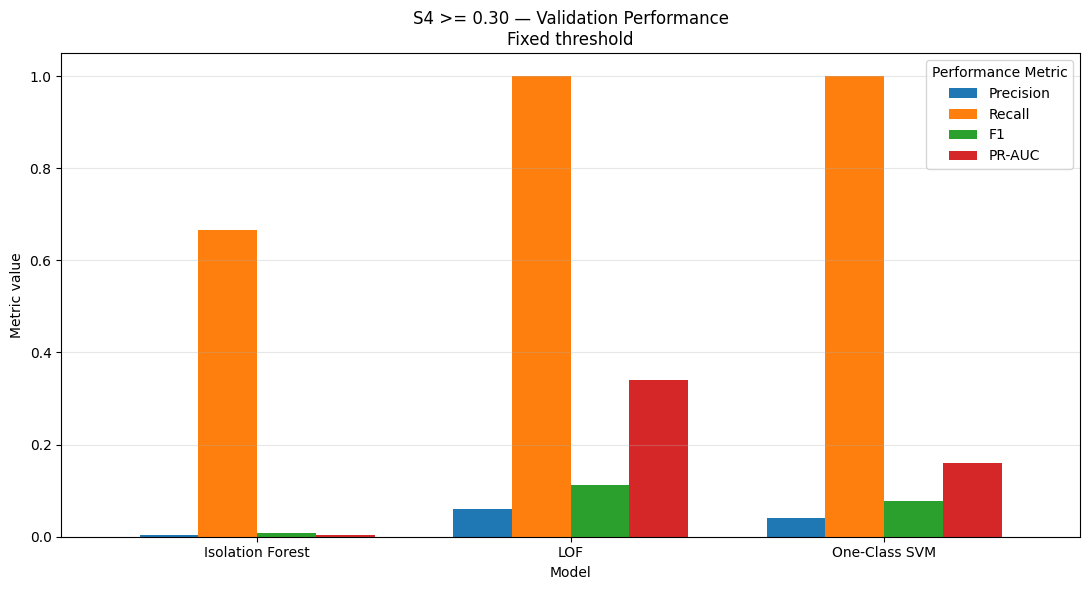

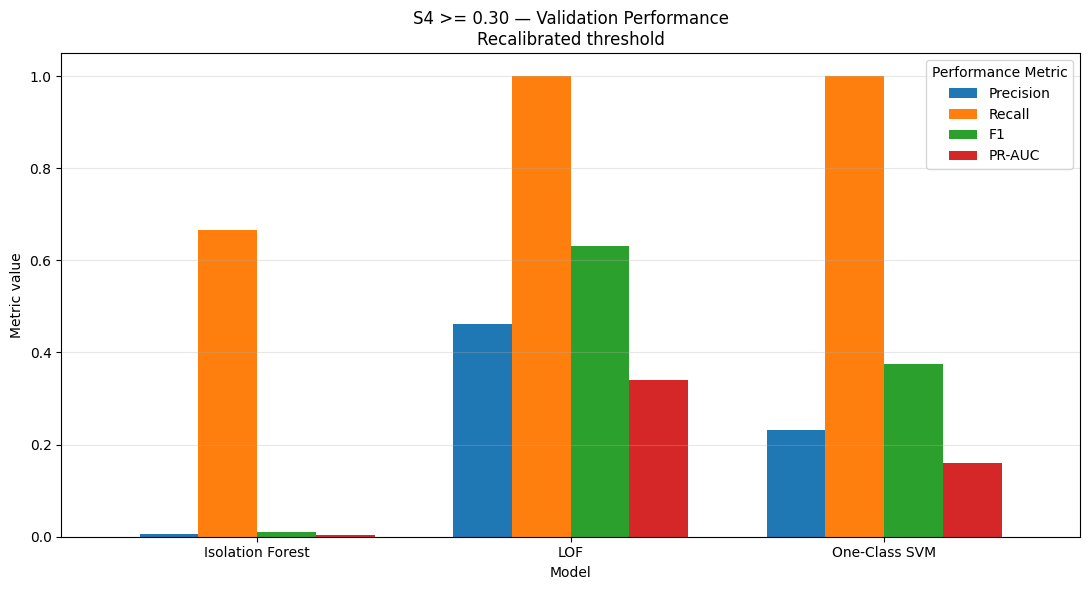

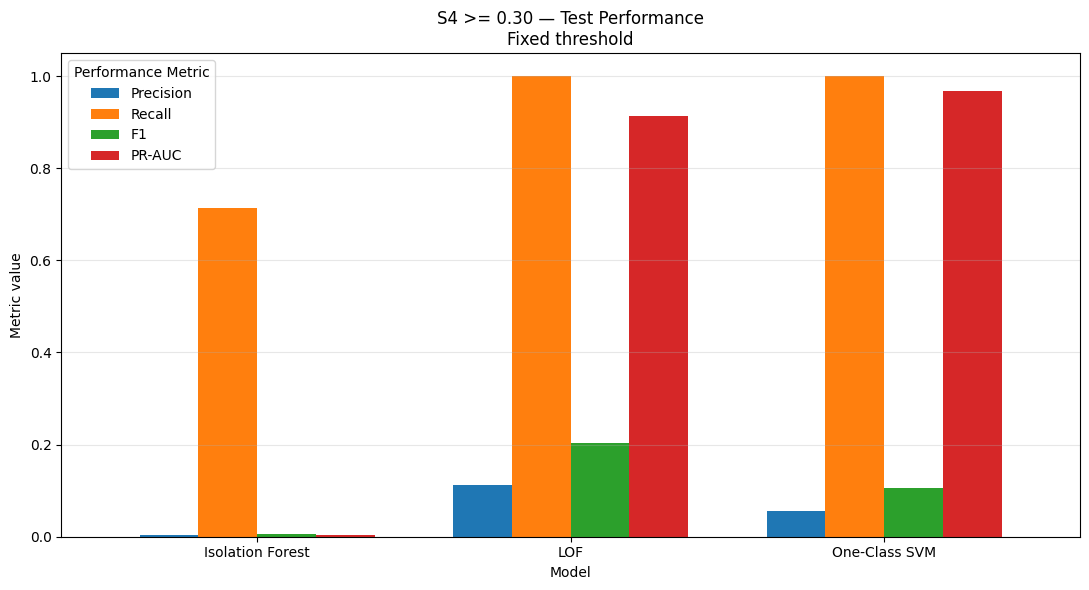

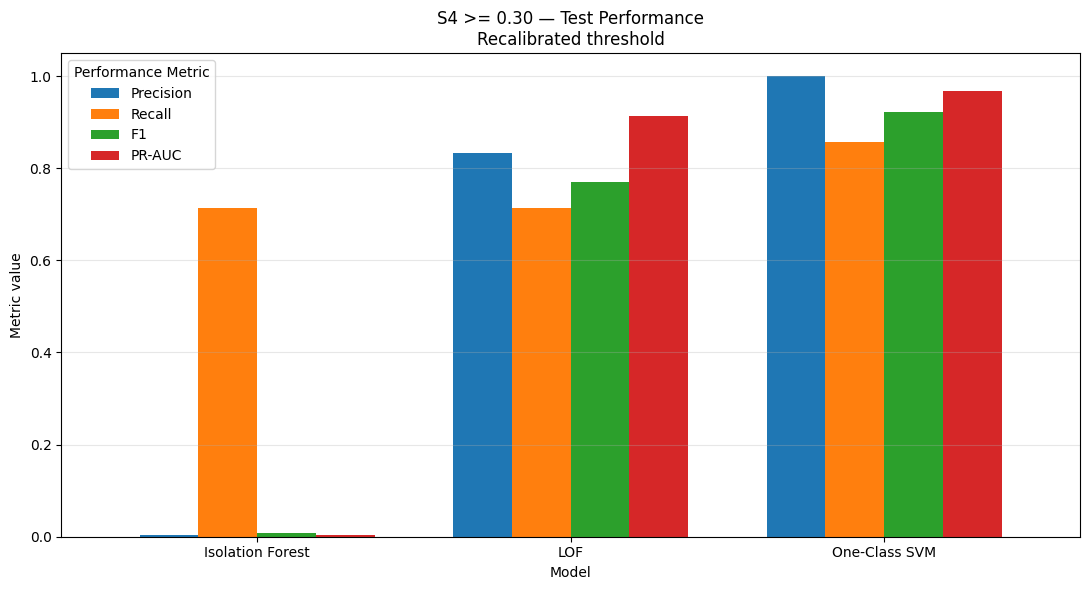

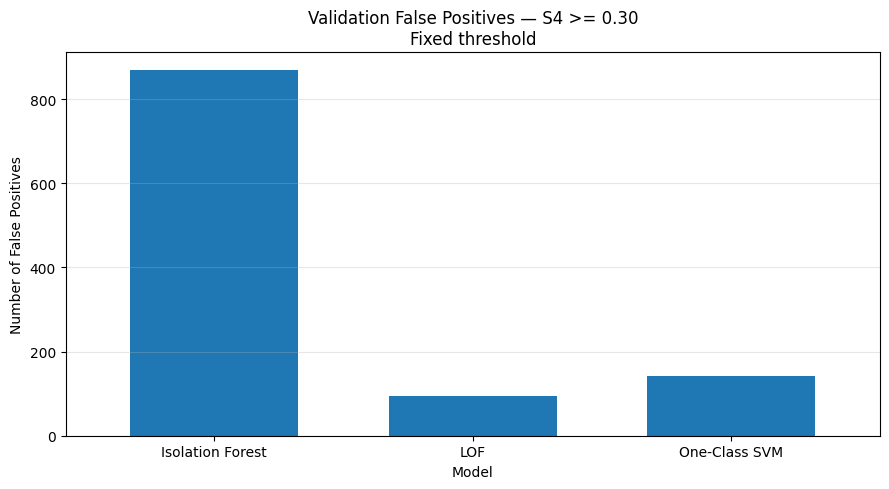

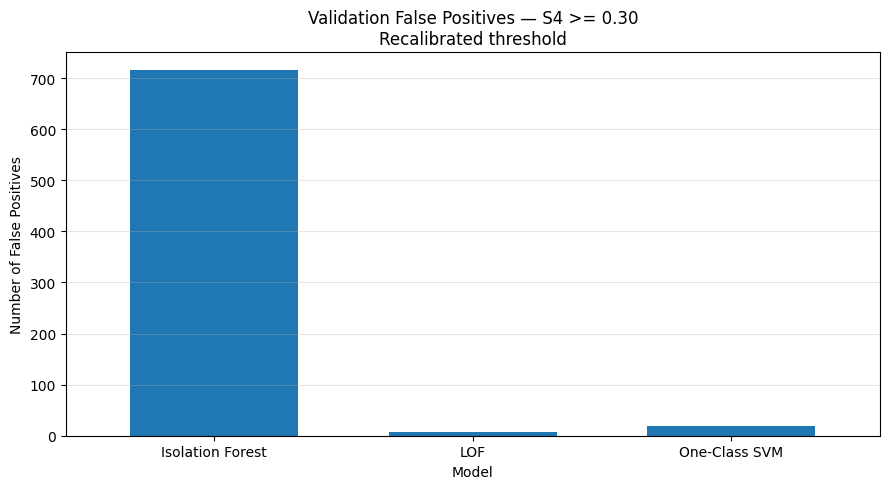

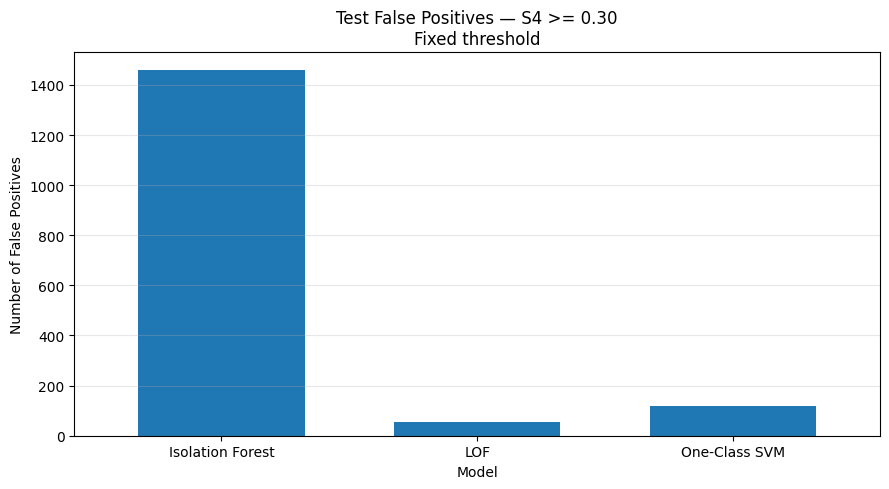

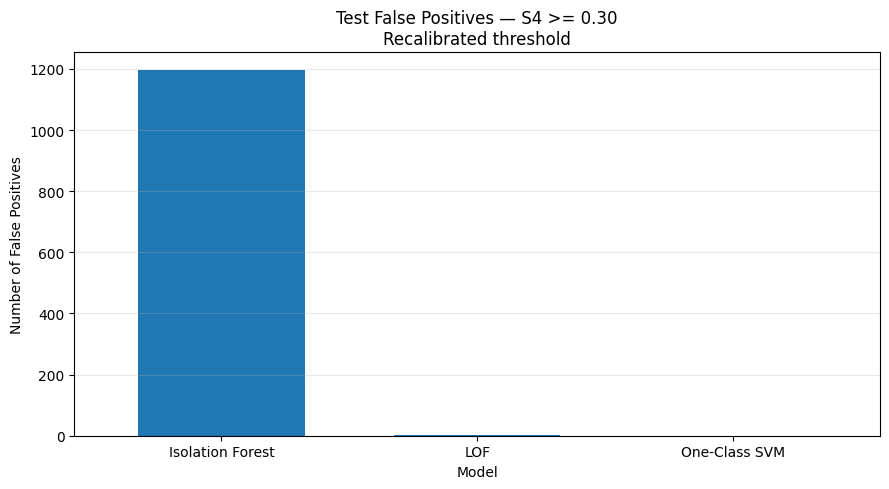

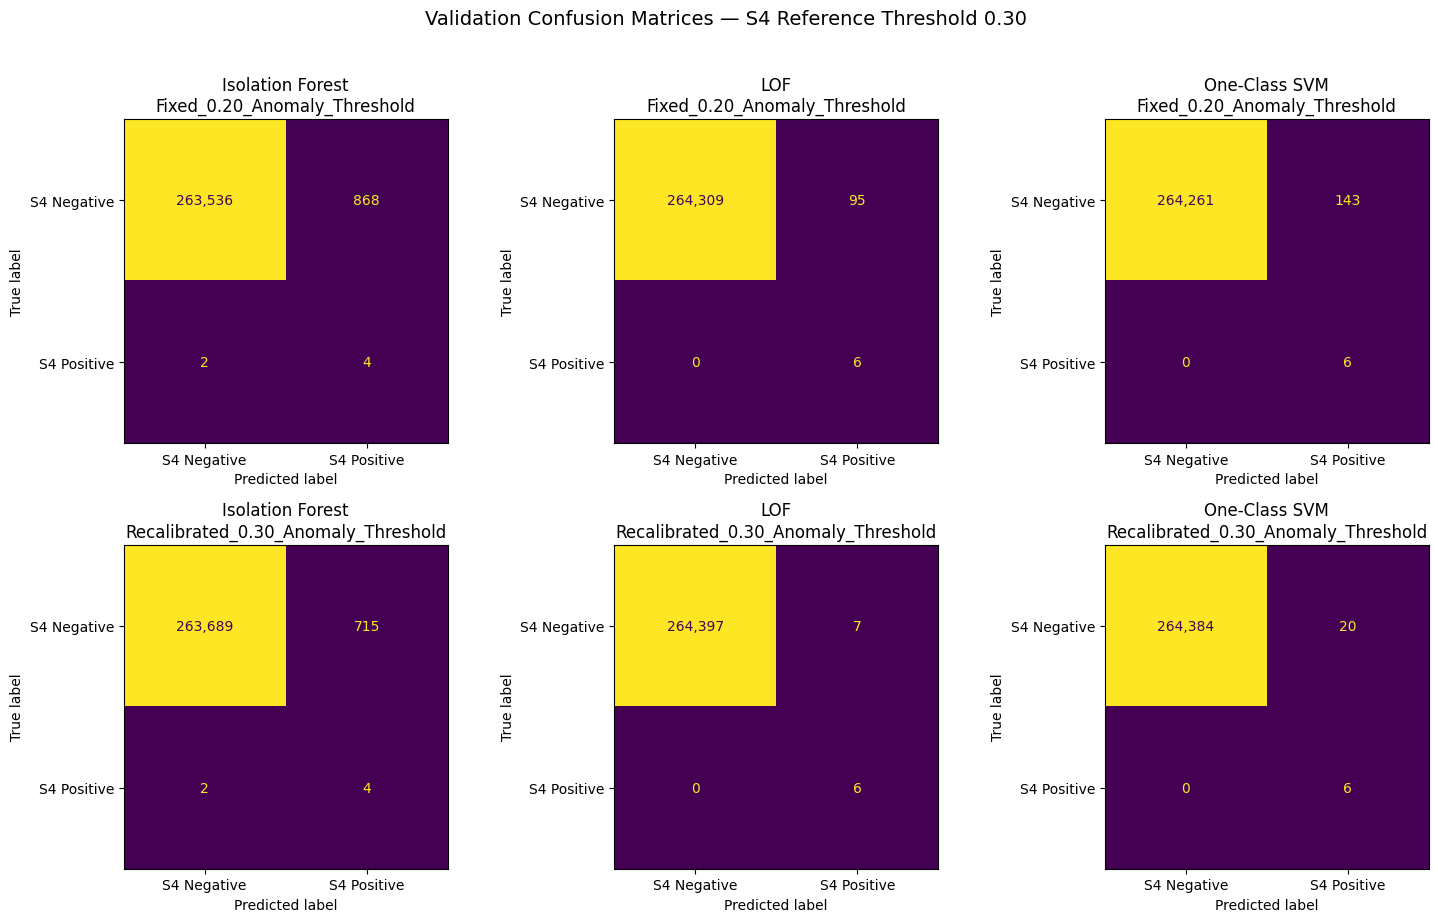

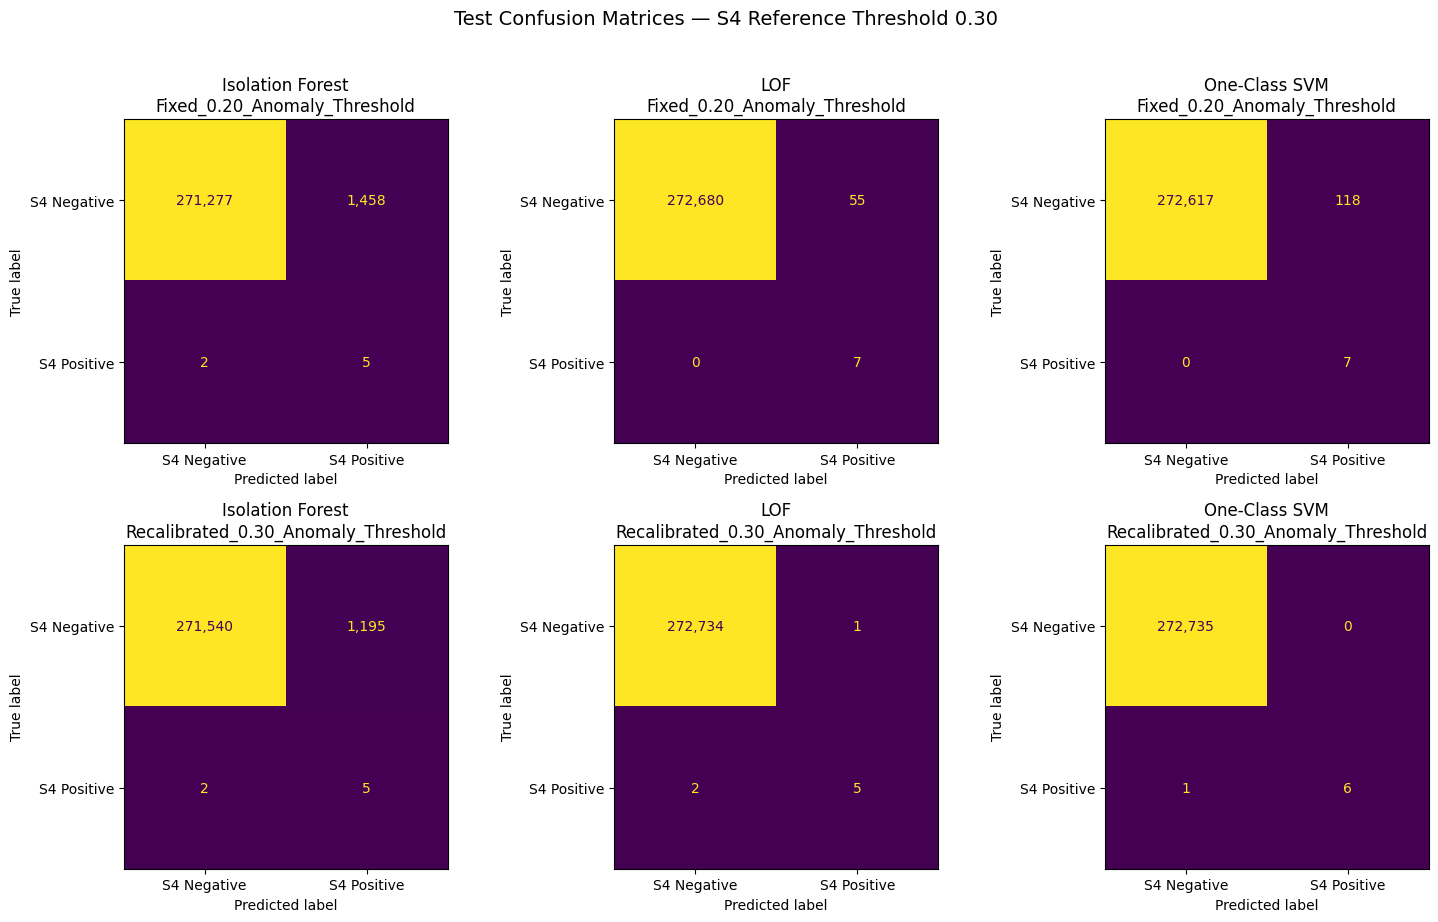


S4 SENSITIVITY ANALYSIS COMPLETED.
------------------------------------------------------------
Alternative S4 reference threshold: 0.3
Models evaluated: 3
Experiments per model: 2

Saved result files:
- s4_threshold_sensitivity.csv
- s4_fixed_threshold_results.csv
- s4_recalibrated_threshold_results.csv

Saved graph files:
- Validation and test performance comparisons
- Validation and test false-positive comparisons
- Validation and test confusion matrices


In [28]:
#NEW ONE
# ============================================================
# WORKFLOW 4 — CELL 9
# S4 REFERENCE THRESHOLD SENSITIVITY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


S4_SENSITIVITY_THRESHOLD = 0.30


# ------------------------------------------------------------
# 1. VALIDATE REFERENCE DATA
# ------------------------------------------------------------

if S4_COLUMN != "Corrected_S4":
    raise ValueError(
        "S4_COLUMN must refer to Corrected_S4 for this analysis."
    )

assert len(val_df) == len(y_val), (
    "Validation observations and y_val have different lengths."
)

assert len(test_df) == len(y_test), (
    "Test observations and y_test have different lengths."
)


# ------------------------------------------------------------
# 2. CREATE ALTERNATIVE REFERENCE LABELS
# ------------------------------------------------------------

y_val_030 = (
    val_df[S4_COLUMN] >= S4_SENSITIVITY_THRESHOLD
).astype(int).to_numpy()

y_test_030 = (
    test_df[S4_COLUMN] >= S4_SENSITIVITY_THRESHOLD
).astype(int).to_numpy()


print("S4 REFERENCE THRESHOLD SENSITIVITY")
print("-" * 60)

print("Main S4 threshold: 0.20")
print("Alternative S4 threshold:", S4_SENSITIVITY_THRESHOLD)

print("\nVALIDATION")
print("Observations:", len(y_val_030))
print("S4 positives:", int(y_val_030.sum()))
print("S4 negatives:", int((y_val_030 == 0).sum()))
print("Positive prevalence:", round(y_val_030.mean(), 6))

print("\nTEST")
print("Observations:", len(y_test_030))
print("S4 positives:", int(y_test_030.sum()))
print("S4 negatives:", int((y_test_030 == 0).sum()))
print("Positive prevalence:", round(y_test_030.mean(), 6))


# ------------------------------------------------------------
# 3. RUN FIXED AND RECALIBRATED THRESHOLD EXPERIMENTS
# ------------------------------------------------------------

s4_sensitivity_rows = []

s4_confusion_matrices = {}

experiment_names = [
    "Fixed_0.20_Anomaly_Threshold",
    "Recalibrated_0.30_Anomaly_Threshold"
]

for model_name, result in best_model_scores.items():

    val_scores = np.asarray(result["validation_scores"])
    test_scores = np.asarray(result["test_scores"])

    assert len(val_scores) == len(y_val_030), (
        f"{model_name}: validation score alignment error."
    )

    assert len(test_scores) == len(y_test_030), (
        f"{model_name}: test score alignment error."
    )

    # --------------------------------------------------------
    # EXPERIMENT A:
    # KEEP THE ANOMALY THRESHOLD SELECTED USING S4 >= 0.20
    # --------------------------------------------------------

    fixed_threshold = result["thresholds"]["Validation_F1"]

    # --------------------------------------------------------
    # EXPERIMENT B:
    # SELECT A NEW THRESHOLD USING VALIDATION S4 >= 0.30
    # --------------------------------------------------------

    recalibrated_threshold = find_best_f1_threshold(
        y_val_030,
        val_scores
    )

    experiment_thresholds = {
        "Fixed_0.20_Anomaly_Threshold": fixed_threshold,
        "Recalibrated_0.30_Anomaly_Threshold": recalibrated_threshold
    }

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    for experiment_name, threshold in experiment_thresholds.items():

        # Validation metrics
        val_metrics = calculate_metrics(
            y_val_030,
            val_scores,
            threshold
        )

        # Test metrics
        test_metrics = calculate_metrics(
            y_test_030,
            test_scores,
            threshold
        )

        # Predictions
        val_predictions = (
            val_scores >= threshold
        ).astype(int)

        test_predictions = (
            test_scores >= threshold
        ).astype(int)

        # Confusion matrices
        val_cm = confusion_matrix(
            y_val_030,
            val_predictions,
            labels=[0, 1]
        )

        test_cm = confusion_matrix(
            y_test_030,
            test_predictions,
            labels=[0, 1]
        )

        # Store confusion matrices
        s4_confusion_matrices[
            (model_name, experiment_name)
        ] = {
            "Validation": val_cm,
            "Test": test_cm
        }

        # Store results
        s4_sensitivity_rows.append({

            "Model": model_name,

            "Experiment": experiment_name,

            "S4_Reference_Threshold": S4_SENSITIVITY_THRESHOLD,

            "Anomaly_Threshold": threshold,

            "Validation_Precision": val_metrics["Precision"],
            "Validation_Recall": val_metrics["Recall"],
            "Validation_F1": val_metrics["F1"],
            "Validation_Average_Precision": val_metrics["Average_Precision"],
            "Validation_FP": int(val_cm[0, 1]),
            "Validation_TP": int(val_cm[1, 1]),
            "Validation_FN": int(val_cm[1, 0]),
            "Validation_TN": int(val_cm[0, 0]),

            "Test_Precision": test_metrics["Precision"],
            "Test_Recall": test_metrics["Recall"],
            "Test_F1": test_metrics["F1"],
            "Test_Average_Precision": test_metrics["Average_Precision"],
            "Test_FP": int(test_cm[0, 1]),
            "Test_TP": int(test_cm[1, 1]),
            "Test_FN": int(test_cm[1, 0]),
            "Test_TN": int(test_cm[0, 0])
        })

        # Print results
        print("\nExperiment:", experiment_name)
        print("Anomaly threshold:", round(threshold, 6))

        print("\nVALIDATION PERFORMANCE")
        print("Precision:", round(val_metrics["Precision"], 6))
        print("Recall:", round(val_metrics["Recall"], 6))
        print("F1:", round(val_metrics["F1"], 6))
        print(
            "Average Precision (PR-AUC):",
            round(val_metrics["Average_Precision"], 6)
        )
        print("False Positives:", int(val_cm[0, 1]))

        print("\nTEST PERFORMANCE")
        print("Precision:", round(test_metrics["Precision"], 6))
        print("Recall:", round(test_metrics["Recall"], 6))
        print("F1:", round(test_metrics["F1"], 6))
        print(
            "Average Precision (PR-AUC):",
            round(test_metrics["Average_Precision"], 6)
        )
        print("False Positives:", int(test_cm[0, 1]))


# ------------------------------------------------------------
# 4. CREATE SENSITIVITY RESULTS TABLE
# ------------------------------------------------------------

s4_sensitivity_results = pd.DataFrame(
    s4_sensitivity_rows
)

print("\nCOMPLETE S4 THRESHOLD SENSITIVITY RESULTS")

report_columns = [
    "Model",
    "Experiment",
    "Anomaly_Threshold",
    "Validation_Precision",
    "Validation_Recall",
    "Validation_F1",
    "Validation_Average_Precision",
    "Validation_FP",
    "Test_Precision",
    "Test_Recall",
    "Test_F1",
    "Test_Average_Precision",
    "Test_FP"
]

display(
    s4_sensitivity_results[report_columns].round(6)
)

s4_sensitivity_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_threshold_sensitivity.csv",
    index=False
)


# ------------------------------------------------------------
# 5. SEPARATE FIXED AND RECALIBRATED RESULTS
# ------------------------------------------------------------

s4_fixed_results = s4_sensitivity_results[
    s4_sensitivity_results["Experiment"]
    == "Fixed_0.20_Anomaly_Threshold"
].copy()

s4_recalibrated_results = s4_sensitivity_results[
    s4_sensitivity_results["Experiment"]
    == "Recalibrated_0.30_Anomaly_Threshold"
].copy()


s4_fixed_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_fixed_threshold_results.csv",
    index=False
)

s4_recalibrated_results.to_csv(
    f"{OUTPUT_FOLDER}/s4_recalibrated_threshold_results.csv",
    index=False
)


# ============================================================
# 6. PERFORMANCE COMPARISON GRAPHS
# ============================================================

comparison_metrics = {
    "Precision": "Precision",
    "Recall": "Recall",
    "F1": "F1",
    "PR-AUC": "Average_Precision"
}


for split in ["Validation", "Test"]:

    for experiment_name, experiment_results in [
        ("Fixed threshold", s4_fixed_results),
        ("Recalibrated threshold", s4_recalibrated_results)
    ]:

        plot_data = experiment_results.set_index("Model")[
            [
                f"{split}_{column}"
                for column in comparison_metrics.values()
            ]
        ].copy()

        plot_data.columns = list(comparison_metrics.keys())

        ax = plot_data.plot(
            kind="bar",
            figsize=(11, 6),
            width=0.75
        )

        ax.set_title(
            f"S4 >= 0.30 — {split} Performance\n{experiment_name}"
        )

        ax.set_xlabel("Model")
        ax.set_ylabel("Metric value")
        ax.set_ylim(0, 1.05)

        ax.grid(
            axis="y",
            alpha=0.3
        )

        ax.tick_params(
            axis="x",
            rotation=0
        )

        ax.legend(
            title="Performance Metric"
        )

        plt.tight_layout()

        safe_experiment = experiment_name.replace(" ", "_")

        plt.savefig(
            f"{OUTPUT_FOLDER}/s4_{split.lower()}_"
            f"{safe_experiment}_performance.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


# ============================================================
# 7. FALSE POSITIVE COMPARISON GRAPHS
# ============================================================

for split in ["Validation", "Test"]:

    for experiment_name, experiment_results in [
        ("Fixed threshold", s4_fixed_results),
        ("Recalibrated threshold", s4_recalibrated_results)
    ]:

        ax = experiment_results.set_index("Model")[
            [f"{split}_FP"]
        ].plot(
            kind="bar",
            figsize=(9, 5),
            width=0.65,
            legend=False
        )

        ax.set_title(
            f"{split} False Positives — S4 >= 0.30\n"
            f"{experiment_name}"
        )

        ax.set_xlabel("Model")
        ax.set_ylabel("Number of False Positives")

        ax.grid(
            axis="y",
            alpha=0.3
        )

        ax.tick_params(
            axis="x",
            rotation=0
        )

        plt.tight_layout()

        safe_experiment = experiment_name.replace(" ", "_")

        plt.savefig(
            f"{OUTPUT_FOLDER}/s4_{split.lower()}_"
            f"{safe_experiment}_false_positives.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()


# ============================================================
# 8. CONFUSION MATRIX GRAPHS
# ============================================================

for split in ["Validation", "Test"]:

    fig, axes = plt.subplots(
        2,
        len(best_model_scores),
        figsize=(5 * len(best_model_scores), 9),
        squeeze=False
    )

    for column, model_name in enumerate(best_model_scores):

        for row, experiment_name in enumerate(experiment_names):

            cm = s4_confusion_matrices[
                (model_name, experiment_name)
            ][split]

            ConfusionMatrixDisplay(
                confusion_matrix=cm,
                display_labels=["S4 Negative", "S4 Positive"]
            ).plot(
                ax=axes[row, column],
                colorbar=False,
                values_format=","
            )

            axes[row, column].set_title(
                f"{model_name}\n{experiment_name}"
            )

    fig.suptitle(
        f"{split} Confusion Matrices — S4 Reference Threshold 0.30",
        fontsize=14,
        y=1.02
    )

    plt.tight_layout()

    plt.savefig(
        f"{OUTPUT_FOLDER}/s4_{split.lower()}_confusion_matrices.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\nS4 SENSITIVITY ANALYSIS COMPLETED.")
print("-" * 60)

print("Alternative S4 reference threshold:", S4_SENSITIVITY_THRESHOLD)
print("Models evaluated:", len(best_model_scores))
print("Experiments per model:", len(experiment_names))

print("\nSaved result files:")
print("- s4_threshold_sensitivity.csv")
print("- s4_fixed_threshold_results.csv")
print("- s4_recalibrated_threshold_results.csv")

print("\nSaved graph files:")
print("- Validation and test performance comparisons")
print("- Validation and test false-positive comparisons")
print("- Validation and test confusion matrices")


If I remove one feature and train the model again, does its ability to detect scintillation improve or become worse?

In [ ]:
# # ============================================================
# # OPTIONAL — FEATURE ABLATION TEST
# # REMOVE ONE FEATURE AT A TIME
# # ============================================================

# feature_ablation_rows = []

# for model_name, selected in best_configurations.items():

#     config = selected["config"]

#     for removed_feature in [None] + FEATURES:

#         if removed_feature is None:
#             current_features = FEATURES.copy()
#             experiment_name = "All features"
#         else:
#             current_features = [
#                 f for f in FEATURES
#                 if f != removed_feature
#             ]
#             experiment_name = f"Without {removed_feature}"

#         if model_name == "Isolation Forest":

#             X_fit = X_train_if_sample[current_features]
#             X_validation = X_val_imputed[current_features]

#         else:

#             X_fit = X_train_scaled_sample[current_features]
#             X_validation = X_val_scaled[current_features]

#         model = build_model(model_name, config)

#         start_time = time.time()

#         model.fit(X_fit)

#         fit_seconds = time.time() - start_time

#         scores = score_in_batches(
#             model,
#             X_validation,
#             model_name,
#             PREDICTION_BATCH_SIZE
#         )

#         ap = average_precision_score(
#             y_val,
#             scores
#         )

#         roc = roc_auc_score(
#             y_val,
#             scores
#         )

#         feature_ablation_rows.append({
#             "Model": model_name,
#             "Experiment": experiment_name,
#             "Number_of_Features": len(current_features),
#             "Validation_AP": ap,
#             "Validation_ROC_AUC": roc,
#             "Fit_Seconds": fit_seconds
#         })

#         print(
#             model_name,
#             "|",
#             experiment_name,
#             "| AP:",
#             round(ap, 5)
#         )


# feature_ablation_results = pd.DataFrame(
#     feature_ablation_rows
# )

# feature_ablation_results = feature_ablation_results.sort_values(
#     ["Model", "Validation_AP"],
#     ascending=[True, False]
# )

# display(feature_ablation_results.round(5))

# feature_ablation_results.to_csv(
#     f"{OUTPUT_FOLDER}/feature_ablation_results.csv",
#     index=False
# )

In [ ]:

# ============================================================
# OPTIONAL — FEATURE ABLATION TEST
# REMOVE ONE FEATURE AT A TIME
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# ------------------------------------------------------------
# 1. INITIALISE RESULTS
# ------------------------------------------------------------

feature_ablation_rows = []
feature_ablation_confusion_matrices = {}

y_val_array = np.asarray(y_val)


# ------------------------------------------------------------
# 2. TRAIN AND EVALUATE EACH ABLATION EXPERIMENT
# ------------------------------------------------------------

for model_name, selected in best_configurations.items():

    config = selected["config"]

    print("\n" + "=" * 70)
    print("FEATURE ABLATION:", model_name)
    print("=" * 70)

    for removed_feature in [None] + FEATURES:

        # Select features
        if removed_feature is None:

            current_features = FEATURES.copy()
            experiment_name = "All features"

        else:

            current_features = [
                feature for feature in FEATURES
                if feature != removed_feature
            ]

            experiment_name = f"Without {removed_feature}"

        if len(current_features) == 0:
            continue

        # Select the appropriate training and validation matrices
        if model_name == "Isolation Forest":

            X_fit = X_train_if_sample[current_features]
            X_validation = X_val_imputed[current_features]

        else:

            X_fit = X_train_scaled_sample[current_features]
            X_validation = X_val_scaled[current_features]

        # Build and fit model
        model = build_model(model_name, config)

        start_time = time.time()

        model.fit(X_fit)

        fit_seconds = time.time() - start_time

        # Obtain validation anomaly scores
        scores = score_in_batches(
            model,
            X_validation,
            model_name,
            PREDICTION_BATCH_SIZE
        )

        scores = np.asarray(scores)

        # ----------------------------------------------------
        # SELECT THRESHOLD USING VALIDATION F1
        # ----------------------------------------------------

        threshold = find_best_f1_threshold(
            y_val_array,
            scores
        )

        predictions = (
            scores >= threshold
        ).astype(int)

        # ----------------------------------------------------
        # CALCULATE VALIDATION METRICS
        # ----------------------------------------------------

        metrics = calculate_metrics(
            y_val_array,
            scores,
            threshold
        )

        # Calculate confusion matrix
        cm = confusion_matrix(
            y_val_array,
            predictions,
            labels=[0, 1]
        )

        tn, fp, fn, tp = cm.ravel()

        # Store confusion matrix
        feature_ablation_confusion_matrices[
            (model_name, experiment_name)
        ] = cm

        # ----------------------------------------------------
        # STORE RESULTS
        # ----------------------------------------------------

        feature_ablation_rows.append({

            "Model": model_name,

            "Experiment": experiment_name,

            "Removed_Feature": (
                "None" if removed_feature is None
                else removed_feature
            ),

            "Number_of_Features": len(current_features),

            "Anomaly_Threshold": threshold,

            "Precision": metrics["Precision"],

            "Recall": metrics["Recall"],

            "F1": metrics["F1"],

            "Average_Precision": metrics["Average_Precision"],

            "ROC_AUC": metrics["ROC_AUC"],

            "FP": int(fp),

            "TP": int(tp),

            "FN": int(fn),

            "TN": int(tn),

            "Fit_Seconds": fit_seconds
        })

        # ----------------------------------------------------
        # PRINT RESULTS
        # ----------------------------------------------------

        print("\nExperiment:", experiment_name)
        print("Features:", len(current_features))
        print("Threshold:", round(threshold, 6))

        print("Precision:", round(metrics["Precision"], 6))
        print("Recall:", round(metrics["Recall"], 6))
        print("F1:", round(metrics["F1"], 6))

        print(
            "Average Precision (PR-AUC):",
            round(metrics["Average_Precision"], 6)
        )

        print("ROC-AUC:", round(metrics["ROC_AUC"], 6))

        print("False Positives:", int(fp))
        print("True Positives:", int(tp))
        print("False Negatives:", int(fn))
        print("True Negatives:", int(tn))

        print("Fit time:", round(fit_seconds, 2), "seconds")


# ------------------------------------------------------------
# 3. CREATE FEATURE ABLATION RESULTS TABLE
# ------------------------------------------------------------

feature_ablation_results = pd.DataFrame(
    feature_ablation_rows
)

feature_ablation_results = feature_ablation_results.sort_values(
    ["Model", "Average_Precision"],
    ascending=[True, False]
).reset_index(drop=True)

print("\nFEATURE ABLATION RESULTS")

display(
    feature_ablation_results.round(6)
)

feature_ablation_results.to_csv(
    f"{OUTPUT_FOLDER}/feature_ablation_results.csv",
    index=False
)


# ------------------------------------------------------------
# 4. DISPLAY CONFUSION MATRIX RESULTS
# ------------------------------------------------------------

confusion_rows = []

for (model_name, experiment_name), cm in (
    feature_ablation_confusion_matrices.items()
):

    tn, fp, fn, tp = cm.ravel()

    confusion_rows.append({

        "Model": model_name,

        "Experiment": experiment_name,

        "TN": int(tn),

        "FP": int(fp),

        "FN": int(fn),

        "TP": int(tp)
    })


feature_ablation_confusion_results = pd.DataFrame(
    confusion_rows
)

print("\nFEATURE ABLATION CONFUSION MATRIX RESULTS")

display(
    feature_ablation_confusion_results
)

feature_ablation_confusion_results.to_csv(
    f"{OUTPUT_FOLDER}/feature_ablation_confusion_matrices.csv",
    index=False
)


# ============================================================
# 5. PERFORMANCE COMPARISON GRAPHS
# ============================================================

performance_metrics = [
    "Precision",
    "Recall",
    "F1",
    "Average_Precision"
]

for model_name in feature_ablation_results["Model"].unique():

    model_results = feature_ablation_results[
        feature_ablation_results["Model"] == model_name
    ].copy()

    plot_data = model_results.set_index("Experiment")[
        performance_metrics
    ].copy()

    plot_data = plot_data.rename(
        columns={
            "Average_Precision": "PR-AUC"
        }
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(15, 6),
        width=0.8
    )

    ax.set_title(
        f"{model_name} — Feature Ablation Performance"
    )

    ax.set_xlabel("Feature Ablation Experiment")
    ax.set_ylabel("Validation Metric")

    ax.set_ylim(0, 1.05)

    ax.grid(
        axis="y",
        alpha=0.3
    )

    ax.tick_params(
        axis="x",
        rotation=75
    )

    ax.legend(
        title="Performance Metric"
    )

    plt.tight_layout()

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        f"{OUTPUT_FOLDER}/{safe_name}_feature_ablation_performance.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 6. AVERAGE PRECISION COMPARISON
# ============================================================

for model_name in feature_ablation_results["Model"].unique():

    model_results = feature_ablation_results[
        feature_ablation_results["Model"] == model_name
    ].copy()

    model_results = model_results.sort_values(
        "Average_Precision",
        ascending=False
    )

    ax = model_results.set_index("Experiment")[
        "Average_Precision"
    ].plot(
        kind="bar",
        figsize=(14, 5),
        width=0.75
    )

    ax.set_title(
        f"{model_name} — Average Precision by Feature Set"
    )

    ax.set_xlabel("Feature Ablation Experiment")
    ax.set_ylabel("Average Precision (PR-AUC)")

    ax.grid(
        axis="y",
        alpha=0.3
    )

    ax.tick_params(
        axis="x",
        rotation=75
    )

    plt.tight_layout()

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        f"{OUTPUT_FOLDER}/{safe_name}_feature_ablation_pr_auc.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 7. FALSE POSITIVE COMPARISON
# ============================================================

for model_name in feature_ablation_results["Model"].unique():

    model_results = feature_ablation_results[
        feature_ablation_results["Model"] == model_name
    ].copy()

    ax = model_results.set_index("Experiment")[
        "FP"
    ].plot(
        kind="bar",
        figsize=(14, 5),
        width=0.75
    )

    ax.set_title(
        f"{model_name} — False Positives by Feature Set"
    )

    ax.set_xlabel("Feature Ablation Experiment")
    ax.set_ylabel("Number of False Positives")

    ax.grid(
        axis="y",
        alpha=0.3
    )

    ax.tick_params(
        axis="x",
        rotation=75
    )

    plt.tight_layout()

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        f"{OUTPUT_FOLDER}/{safe_name}_feature_ablation_false_positives.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 8. CONFUSION MATRIX VISUALISATION
# ============================================================

for model_name in feature_ablation_results["Model"].unique():

    model_experiments = [
        experiment_name
        for current_model, experiment_name
        in feature_ablation_confusion_matrices
        if current_model == model_name
    ]

    n_experiments = len(model_experiments)

    n_columns = 3

    n_rows = int(np.ceil(n_experiments / n_columns))

    fig, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(5 * n_columns, 4.5 * n_rows),
        squeeze=False
    )

    for index, experiment_name in enumerate(model_experiments):

        row = index // n_columns
        column = index % n_columns

        cm = feature_ablation_confusion_matrices[
            (model_name, experiment_name)
        ]

        ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["S4 Negative", "S4 Positive"]
        ).plot(
            ax=axes[row, column],
            colorbar=False,
            values_format=","
        )

        axes[row, column].set_title(experiment_name)

    # Hide unused subplot positions
    for index in range(n_experiments, n_rows * n_columns):

        row = index // n_columns
        column = index % n_columns

        axes[row, column].axis("off")

    fig.suptitle(
        f"{model_name} — Feature Ablation Confusion Matrices",
        fontsize=14
    )

    plt.tight_layout()

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    plt.savefig(
        f"{OUTPUT_FOLDER}/{safe_name}_feature_ablation_confusion_matrices.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\nFEATURE ABLATION ANALYSIS COMPLETED.")
print("-" * 60)

print("Models evaluated:", feature_ablation_results["Model"].nunique())

print(
    "Experiments per model:",
    feature_ablation_results.groupby("Model").size().to_dict()
)

print("\nSaved files:")
print("- feature_ablation_results.csv")
print("- feature_ablation_confusion_matrices.csv")
print("- Model-specific performance graphs")
print("- Model-specific PR-AUC graphs")
print("- Model-specific false-positive graphs")
print("- Model-specific confusion matrix graphs")


In [12]:
# Download all reports
import shutil
from google.colab import files

shutil.make_archive(
    "workflow4_results",
    "zip",
    OUTPUT_FOLDER
)

files.download("workflow4_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 5. Anomaly Output

[Reference](https://chatgpt.com/s/t_6af05f0de8e48191b12be8ce67caa920)

This cell freezes your final model and anomaly-detection threshold before you proceed with the final evaluation.

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 1
# FINAL MODEL AND THRESHOLD SELECTION
# ============================================================

FINAL_MODEL_NAME = "Isolation Forest"

FINAL_THRESHOLD_METHOD = "Validation_F1"

# True = output all three models for comparison.
# False = output only the selected primary model.
INCLUDE_ALL_MODELS = True

S4_REFERENCE_THRESHOLD = 0.20

# ------------------------------------------------------------
# CHECK WORKFLOW 4 OUTPUTS
# ------------------------------------------------------------

required_objects = [
    "best_models",
    "best_model_scores",
    "FEATURES",
    "df_clean"
]

for obj in required_objects:
    if obj not in globals():
        raise NameError(
            f"{obj} is missing. Run Workflow 4 first."
        )

if FINAL_MODEL_NAME not in best_models:
    raise ValueError("Selected model is unavailable.")

if FINAL_MODEL_NAME not in best_model_scores:
    raise ValueError("Selected model scores are unavailable.")

if FINAL_THRESHOLD_METHOD not in best_model_scores[
    FINAL_MODEL_NAME
]["thresholds"]:
    raise ValueError("Selected threshold method is unavailable.")


# ------------------------------------------------------------
# SELECT MODELS
# ------------------------------------------------------------

if INCLUDE_ALL_MODELS:
    selected_model_names = list(best_models.keys())
else:
    selected_model_names = [FINAL_MODEL_NAME]



# ------------------------------------------------------------
# FREEZE FINAL THRESHOLDS
# ------------------------------------------------------------

final_thresholds = {
    name: best_model_scores[name]["thresholds"][
        FINAL_THRESHOLD_METHOD
    ]
    for name in selected_model_names
}


# ------------------------------------------------------------
# FREEZE FINAL MODEL CONFIGURATIONS
# ------------------------------------------------------------

final_configurations = {
    name: best_model_scores[name]["config"].copy()
    for name in selected_model_names
}


# ------------------------------------------------------------
# CREATE FINAL SETTINGS TABLE
# ------------------------------------------------------------

final_settings = pd.DataFrame([
    {
        "Model": name,
        "Primary_Model": name == FINAL_MODEL_NAME,
        "Threshold_Method": FINAL_THRESHOLD_METHOD,
        "Anomaly_Threshold": final_thresholds[name],
        "S4_Reference_Threshold": S4_REFERENCE_THRESHOLD,
        "Parameters": json.dumps(
            final_configurations[name],
            sort_keys=True
        )
    }
    for name in selected_model_names
])

display(final_settings)

final_settings.to_csv(
    f"{OUTPUT_FOLDER}/final_model_settings.csv",
    index=False
)

final_settings.to_csv(
    f"{OUTPUT_FOLDER}/final_model_settings.csv",
    index=False
)


This cell generates anomaly scores and anomaly predictions for every observation in your training, validation, and test datasets using your selected final models.

In simple terms, it applies the models you selected in Cell 1 to your data and creates a complete record showing which observations each model considers anomalous.

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 2
# GENERATE ANOMALY SCORES AND PREDICTIONS
# ============================================================

# ------------------------------------------------------------
# PREPARE THE THREE SPLITS
# ------------------------------------------------------------

split_data = {

    "train": {
        "df": train_df,
        "IF": X_train_imputed,
        "scaled": X_train_scaled
    },

    "validation": {
        "df": val_df,
        "IF": X_val_imputed,
        "scaled": X_val_scaled
    },

    "test": {
        "df": test_df,
        "IF": X_test_imputed,
        "scaled": X_test_scaled
    }
}


# ------------------------------------------------------------
# SCORE EACH SPLIT
# ------------------------------------------------------------

output_parts = []

for split_name, split in split_data.items():

    source_df = split["df"]

    # Start with the original cleaned observations.
    output = df_clean.loc[source_df.index].copy()

    output["Data_Split"] = split_name

    for model_name in selected_model_names:

        model = best_models[model_name]

        # Select correct input scaling.
        if model_name == "Isolation Forest":
            X_current = split["IF"]
        else:
            X_current = split["scaled"]

        # Check that features and observations align.
        if not X_current.index.equals(source_df.index):
            raise ValueError(
                f"Index mismatch: {model_name}, {split_name}"
            )

        # Higher score always means more anomalous.
        scores = score_in_batches(
            model,
            X_current,
            model_name,
            PREDICTION_BATCH_SIZE
        )

        if len(scores) != len(output):
            raise ValueError(
                f"Score length mismatch: {model_name}, {split_name}"
            )

        safe_name = (
            model_name.lower()
            .replace(" ", "_")
            .replace("-", "_")
        )

        threshold = final_thresholds[model_name]

        predictions = (
            scores >= threshold
        ).astype(int)

        output[f"{safe_name}_score"] = scores

        output[f"{safe_name}_prediction"] = predictions

        output[f"{safe_name}_threshold"] = threshold

    output_parts.append(output)


# ------------------------------------------------------------
# COMBINE THE OUTPUTS
# ------------------------------------------------------------

anomaly_output = pd.concat(
    output_parts,
    axis=0
).sort_values(
    ["_DATE", "Second", "PRN"]
).copy()

anomaly_output.index.name = "Original_Row_Index"

anomaly_output = anomaly_output.reset_index()


# ------------------------------------------------------------
# CREATE DATASET TIMESTAMP
# ------------------------------------------------------------

anomaly_output["Timestamp"] = (
    pd.to_datetime(anomaly_output["_DATE"]) +
    pd.to_timedelta(
        anomaly_output["Second"],
        unit="s"
    )
)


# ------------------------------------------------------------
# MODEL AGREEMENT
# ------------------------------------------------------------

prediction_columns = []

for model_name in selected_model_names:

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("-", "_")
    )

    prediction_columns.append(
        f"{safe_name}_prediction"
    )


anomaly_output["Models_Flagging"] = (
    anomaly_output[prediction_columns].sum(axis=1)
)

anomaly_output["Number_of_Models"] = len(
    selected_model_names
)


anomaly_output["Model_Agreement"] = np.select(
    [
        anomaly_output["Models_Flagging"] == 0,

        anomaly_output["Models_Flagging"] ==
        len(selected_model_names)
    ],

    [
        "No model flagged",
        "All models flagged"
    ],

    default="Partial agreement"
)


# ------------------------------------------------------------
# SAVE COMPLETE OBSERVATION-LEVEL OUTPUT
# ------------------------------------------------------------

anomaly_output.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_all_observations.csv",
    index=False
)


print("ANOMALY OUTPUT GENERATED")
print("-" * 55)

print("Total output observations:", len(anomaly_output))

print("\nObservations by split:")
print(anomaly_output["Data_Split"].value_counts())

print("\nModel agreement:")
print(anomaly_output["Model_Agreement"].value_counts())

print("\nSaved: workflow5_all_observations.csv")

This cell extracts and saves the anomalous GNSS observations identified by your selected models in Cell 2.

Cell 2 generated anomaly scores and predictions for every observation. Cell 3 filters those results to produce smaller datasets containing only the observations flagged as anomalous.

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 3
# EXTRACT ANOMALOUS OBSERVATIONS
# ============================================================

primary_safe_name = (
    FINAL_MODEL_NAME.lower()
    .replace(" ", "_")
    .replace("-", "_")
)

primary_prediction = (
    f"{primary_safe_name}_prediction"
)


# ------------------------------------------------------------
# PRIMARY MODEL ANOMALIES
# ------------------------------------------------------------

primary_anomalies = anomaly_output[
    anomaly_output[primary_prediction] == 1
].copy()


# ------------------------------------------------------------
# ALL-MODEL AGREEMENT
# ------------------------------------------------------------

all_model_anomalies = anomaly_output[
    anomaly_output["Models_Flagging"] ==
    len(selected_model_names)
].copy()


# ------------------------------------------------------------
# PRIMARY MODEL TEST ANOMALIES
# ------------------------------------------------------------

test_primary_anomalies = primary_anomalies[
    primary_anomalies["Data_Split"] == "test"
].copy()


# ------------------------------------------------------------
# SAVE OUTPUTS
# ------------------------------------------------------------

primary_anomalies.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_primary_model_anomalies.csv",
    index=False
)

all_model_anomalies.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_all_models_agree.csv",
    index=False
)

test_primary_anomalies.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_test_anomalies.csv",
    index=False
)


# ------------------------------------------------------------
# DISPLAY SUMMARY
# ------------------------------------------------------------

print("ANOMALY EXTRACTION")
print("-" * 55)

print("Primary model:", FINAL_MODEL_NAME)

print("Primary model anomalies:", len(primary_anomalies))

print("All-model agreement:", len(all_model_anomalies))

print("Test anomalies:", len(test_primary_anomalies))

print(
    "S4-positive observations among test anomalies:",
    int(test_primary_anomalies[TARGET].sum())
)

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 4
# IDENTIFY CONSECUTIVE ANOMALY RUNS
# ============================================================

run_data = primary_anomalies.copy()

run_data = run_data.sort_values(
    ["Data_Split", "PRN", "Timestamp"]
).copy()


# ------------------------------------------------------------
# CALCULATE TIME GAP
# ------------------------------------------------------------

group_columns = ["Data_Split", "PRN"]

run_data["Previous_Timestamp"] = (
    run_data.groupby(group_columns)["Timestamp"].shift(1)
)

run_data["Time_Gap_Seconds"] = (
    run_data["Timestamp"] -
    run_data["Previous_Timestamp"]
).dt.total_seconds()


# ------------------------------------------------------------
# IDENTIFY START OF NEW RUN
# ------------------------------------------------------------

run_data["New_Run"] = (
    run_data["Time_Gap_Seconds"] != 60
).astype(int)


# ------------------------------------------------------------
# CREATE UNIQUE RUN IDENTIFIERS
# ------------------------------------------------------------

run_data["Run_Number"] = (
    run_data.groupby(group_columns)["New_Run"].cumsum()
)

run_data["Candidate_Run_ID"] = (
    run_data["Data_Split"].astype(str)
    + "_PRN"
    + run_data["PRN"].astype(str)
    + "_RUN"
    + run_data["Run_Number"].astype(str)
)


# ------------------------------------------------------------
# SUMMARISE EACH RUN
# ------------------------------------------------------------

score_column = f"{primary_safe_name}_score"

candidate_runs = (
    run_data
    .groupby(
        [
            "Data_Split",
            "PRN",
            "Candidate_Run_ID"
        ],
        as_index=False
    )
    .agg(
        Start_Time=("Timestamp", "min"),

        End_Time=("Timestamp", "max"),

        Number_of_Observations=("Timestamp", "size"),

        Mean_Anomaly_Score=(score_column, "mean"),

        Maximum_Anomaly_Score=(score_column, "max"),

        Mean_Corrected_S4=(S4_COLUMN, "mean"),

        Maximum_Corrected_S4=(S4_COLUMN, "max"),

        S4_Positive_Observations=(TARGET, "sum"),

        Mean_Elevation=("Elevation", "mean")
    )
)


# ------------------------------------------------------------
# CALCULATE ELAPSED DURATION
# ------------------------------------------------------------

candidate_runs["Duration_Minutes"] = (
    candidate_runs["End_Time"] -
    candidate_runs["Start_Time"]
).dt.total_seconds() / 60


candidate_runs["Run_Type"] = np.where(
    candidate_runs["Number_of_Observations"] == 1,
    "Single-observation anomaly",
    "Consecutive anomaly run"
)


candidate_runs = candidate_runs.sort_values(
    ["Data_Split", "Start_Time", "PRN"]
)


# ------------------------------------------------------------
# SAVE RUN OUTPUTS
# ------------------------------------------------------------

run_data.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_anomalies_with_run_ids.csv",
    index=False
)

candidate_runs.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_candidate_anomaly_runs.csv",
    index=False
)


# ------------------------------------------------------------
# DISPLAY LONGEST RUNS
# ------------------------------------------------------------

print("CANDIDATE ANOMALY RUNS")
print("-" * 55)

print("Total candidate runs:", len(candidate_runs))

print(
    "Single-observation runs:",
    int((candidate_runs["Number_of_Observations"] == 1).sum())
)

print(
    "Consecutive runs:",
    int((candidate_runs["Number_of_Observations"] > 1).sum())
)

display(
    candidate_runs.sort_values(
        "Duration_Minutes",
        ascending=False
    ).head(20)
)

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 5
# CANDIDATE ANOMALY RUN SUMMARY
# ============================================================

run_summary = (
    candidate_runs
    .groupby("Data_Split")
    .agg(
        Total_Candidate_Runs=(
            "Candidate_Run_ID",
            "count"
        ),

        Single_Observation_Runs=(
            "Number_of_Observations",
            lambda x: int((x == 1).sum())
        ),

        Consecutive_Runs=(
            "Number_of_Observations",
            lambda x: int((x > 1).sum())
        ),

        Total_Anomalous_Observations=(
            "Number_of_Observations",
            "sum"
        ),

        Mean_Run_Duration_Minutes=(
            "Duration_Minutes",
            "mean"
        ),

        Median_Run_Duration_Minutes=(
            "Duration_Minutes",
            "median"
        ),

        Maximum_Run_Duration_Minutes=(
            "Duration_Minutes",
            "max"
        )
    )
    .reset_index()
)


# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

run_summary.to_csv(
    f"{OUTPUT_FOLDER}/workflow5_candidate_run_summary.csv",
    index=False
)


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("CANDIDATE RUN SUMMARY")
print("-" * 55)

display(run_summary.round(3))


# ------------------------------------------------------------
# FINAL TEST-PERIOD RUNS
# ------------------------------------------------------------

test_run_summary = run_summary[
    run_summary["Data_Split"] == "test"
].copy()

print("\nFINAL TEST-PERIOD RUN SUMMARY")

display(test_run_summary.round(3))

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 6
# ANOMALY OUTPUT VISUALISATION
# ============================================================

test_output = anomaly_output[
    anomaly_output["Data_Split"] == "test"
].copy()

test_output = test_output.sort_values("Timestamp")

prediction_column = f"{primary_safe_name}_prediction"

score_column = f"{primary_safe_name}_score"


# ------------------------------------------------------------
# GRAPH 1 — CORRECTED S4 AND ANOMALY SCORES OVER TIME
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    1,
    figsize=(15, 9),
    sharex=True
)


axes[0].plot(
    test_output["Timestamp"],
    test_output[S4_COLUMN],
    linewidth=0.5
)

axes[0].axhline(
    S4_REFERENCE_THRESHOLD,
    linestyle="--",
    label="S4 reference threshold"
)

axes[0].set_ylabel("Corrected S4")
axes[0].set_title("Corrected S4 Across Test Period")
axes[0].legend()
axes[0].grid(alpha=0.3)


axes[1].scatter(
    test_output["Timestamp"],
    test_output[score_column],
    c=test_output[prediction_column],
    s=5
)

axes[1].axhline(
    final_thresholds[FINAL_MODEL_NAME],
    linestyle="--",
    label="Anomaly threshold"
)

axes[1].set_xlabel("Dataset clock time")
axes[1].set_ylabel("Anomaly score")

axes[1].set_title(
    f"{FINAL_MODEL_NAME}: Test Anomaly Scores"
)

axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/workflow5_s4_anomaly_timeline.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# GRAPH 2 — ANOMALIES BY PRN
# ------------------------------------------------------------

anomalies_by_prn = (
    test_output[
        test_output[prediction_column] == 1
    ]
    .groupby("PRN")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))

anomalies_by_prn.plot(kind="bar")

plt.xlabel("PRN")
plt.ylabel("Number of flagged observations")

plt.title(
    f"Test Anomalies by PRN — {FINAL_MODEL_NAME}"
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/workflow5_anomalies_by_prn.png",
    dpi=300
)

plt.show()


# ------------------------------------------------------------
# GRAPH 3 — CANDIDATE RUN DURATIONS
# ------------------------------------------------------------

test_runs = candidate_runs[
    candidate_runs["Data_Split"] == "test"
]

plt.figure(figsize=(9, 5))

plt.hist(
    test_runs["Duration_Minutes"],
    bins=30
)

plt.xlabel("Elapsed duration (minutes)")
plt.ylabel("Number of candidate runs")

plt.title("Test Candidate Anomaly-Run Durations")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{OUTPUT_FOLDER}/workflow5_candidate_run_durations.png",
    dpi=300
)

plt.show()

In [ ]:
# ============================================================
# WORKFLOW 5 — CELL 7
# EXPORT FINAL RESULTS
# ============================================================

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "workflow5_anomaly_output",
    "zip",
    OUTPUT_FOLDER
)

print("Workflow 5 results exported.")

files.download(zip_path)

In [ ]:
import tensorflow as tf
tf.test.gpu_device_name()

import platform

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))
print("Machine:", platform.machine())
print("Processor:", platform.processor())
print("System:", platform.system())

In [ ]:
import sys
import os
import platform
import subprocess
import multiprocessing
import psutil

print("=" * 65)
print("SYSTEM INFORMATION")
print("=" * 65)

# Operating system
print("Operating System :", platform.system())
print("OS Version       :", platform.mac_ver()[0])
print("Architecture     :", platform.machine())
print("Processor        :", platform.processor())

# Python
print("\n" + "=" * 65)
print("PYTHON ENVIRONMENT")
print("=" * 65)

print("Python Version   :", sys.version)
print("Python Executable:", sys.executable)
print("Python Path      :", sys.prefix)
print("Virtual Env      :", os.environ.get("VIRTUAL_ENV", "Not detected"))
print("Working Directory:", os.getcwd())

# CPU
print("\n" + "=" * 65)
print("CPU INFORMATION")
print("=" * 65)

print("CPU Cores (Logical):", psutil.cpu_count(logical=True))
print("CPU Cores (Physical):", psutil.cpu_count(logical=False))
print("CPU Usage          :", psutil.cpu_percent(interval=1), "%")

# RAM
print("\n" + "=" * 65)
print("RAM INFORMATION")
print("=" * 65)

ram = psutil.virtual_memory()

print(f"Total RAM     : {ram.total / (1024**3):.2f} GB")
print(f"Available RAM : {ram.available / (1024**3):.2f} GB")
print(f"Used RAM      : {ram.used / (1024**3):.2f} GB")
print(f"RAM Usage     : {ram.percent}%")